# Import

In [23]:
import os
from pathlib import Path
import re

import numpy as np
import pandas as pd
import sqlite3

import matplotlib.pyplot as plt
import seaborn as sns
from analysis.analyzer import TTTH_Analyzer as Analyzer

import scipy.stats as stats
from scipy.stats import f_oneway, chi2_contingency

import statsmodels.api as sm
from statsmodels.formula.api import ols

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from IPython.display import display
pd.set_option('display.max_columns', None)

# Đọc dữ liệu

## Chạy cmd

In [2]:
# Trước đó có chạy câu lệnh -> để unzip và lấy nhãn

# cd lycos-ids2017       
# for zip_file in pcap_lycos/*.zip; do unzip -n "$zip_file" -d pcap_lycos; done
# python3 labelling.py

## Gộp data

In [3]:
folder_order = "01_raw_data"

file_list = sorted(
    os.path.join(folder_order, file)
    for file in os.listdir(folder_order)
    if file.endswith('.csv')
)

df_list = []
for file in file_list:
    df_day = pd.read_csv(file)
    df_day['source_day'] = os.path.basename(file).split('-')[0]
    df_list.append(df_day)

df_raw = pd.concat(df_list, ignore_index=True)
del df_list, df_day
columns_raw = [col for col in df_raw.columns if col != 'source_day']

df_raw

,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.341593e+06,50763066

## Xuất data

In [4]:
# # Xuất CSV
# df_raw.to_csv("02_merge_data/data_raw.csv", index=False)

# # Xuất sql
# with sqlite3.connect(":memory:") as conn:
#     df_raw.to_sql("data_raw", conn, index=False)
#     with open("02_merge_data/data_raw.sql", "w", encoding="utf-8") as f:
#         f.writelines(line + "\n" for line in conn.iterdump())

## Mô tả data columns

In [5]:
# 1. Đọc thông tin 84 trường từ Excel
df_info = pd.read_excel("03_other_data/columns_dict.xlsx")

df_info = df_info[
    ["Nhóm", "STT", "Tên cột", "Ý nghĩa", "Ràng buộc đề xuất"]
].copy()

# 2. Kiểm tra tên cột
missing = set(df_info["Tên cột"]) - set(df_raw.columns)
if missing:
    raise ValueError(f"Không tìm thấy trong df_raw: {missing}")

# 3. Hàm định dạng giá trị
def fmt(x):
    if pd.isna(x):
        return "NaN"
    if isinstance(x, (int, np.integer)):
        return f"{x:,}"
    if isinstance(x, (float, np.floating)):
        return f"{x:.10g}"
    return str(x)

# 4. Lấy mẫu ngẫu nhiên từ df_raw
df_sample = df_raw.sample(
    n=min(20000, len(df_raw)),
    random_state=42
)

# 5. Tính thống kê cho từng trường
dtypes = []
ranges = []
unique_counts = []
examples = []

for col in df_info["Tên cột"]:
    s = df_raw[col]

    # Kiểu dữ liệu
    dtypes.append(str(s.dtype))

    # Số giá trị duy nhất trên toàn bộ df_raw
    n_unique = s.nunique(dropna=True)
    unique_counts.append(n_unique)

    # Khoảng quan sát trên toàn bộ df_raw
    if pd.api.types.is_numeric_dtype(s):
        ranges.append(f"{fmt(s.min())} – {fmt(s.max())}")
    elif pd.api.types.is_datetime64_any_dtype(s):
        ranges.append(f"{s.min()} – {s.max()}")
    else:
        ranges.append(
            f"{n_unique:,} giá trị phân biệt; "
            f"{s.isna().sum():,} giá trị thiếu"
        )

    # 5 giá trị mẫu khác nhau
    values = (
        df_sample[col]
        .dropna()
        .drop_duplicates()
        .head(5)
        .tolist()
    )

    examples.append("; ".join(fmt(v) for v in values))

# 6. Hoàn thiện df_info
df_info["Kiểu dữ liệu"] = dtypes
df_info["Khoảng quan sát"] = ranges
df_info["Số giá trị duy nhất"] = unique_counts
df_info["5 giá trị mẫu"] = examples

# 7. Sắp xếp thứ tự cột
df_info = df_info[
    [
        "Nhóm",
        "STT",
        "Tên cột",
        "Kiểu dữ liệu",
        "Ý nghĩa",
        "Khoảng quan sát",
        "Số giá trị duy nhất",
        "5 giá trị mẫu",
        "Ràng buộc đề xuất"
    ]
]

# 8. Lưu Excel
output_path = Path("04_output/01_info/01_columns_info.xlsx")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_info.to_excel(output_path, index=False)

# 9. Hiển thị
print("Số trường:", len(df_info))
df_info

Số trường: 84


,Nhóm,STT,Tên cột,Kiểu dữ liệu,Ý nghĩa,Khoảng quan sát,Số giá trị duy nhất,5 giá trị mẫu,Ràng buộc đề xuất
0,Định danh luồng và thông tin kết nối,1,flow_id,object,"Mã luồng ghép từ IP, cổng và giao thức của hai...","942,759 giá trị phân biệt; 0 giá trị thiếu",942759,192.168.10.12-192.168.10.3-60185-53-17; 192.16...,Chuỗi không rỗng. Không dùng làm khóa duy nhất...
1,Định danh luồng và thông tin kết nối,2,src_addr,object,Địa chỉ IP của bên khởi tạo luồng.,268 giá trị phân biệt; 0 giá trị thiếu,268,192.168.10.12; 192.168.10.9; 172.16.0.1; 192.1...,Địa chỉ IPv4 hợp lệ; không rỗng khi nhận dạng ...
2,Định danh luồng và thông tin kết nối,3,src_port,int64,Cổng nguồn.,"0 – 65,535",64491,"60,185; 54,951; 49,068; 36,448; 49,448",Số nguyên từ 0 đến 65.535; 0 được phép với gia...
3,Định danh luồng và thông tin kết nối,4,dst_addr,object,Địa chỉ IP của bên nhận luồng.,"18,095 giá trị phân biệt; 0 giá trị thiếu",18095,192.168.10.3; 192.168.10.50; 178.172.160.2; 78...,Địa chỉ IPv4 hợp lệ; không rỗng khi nhận dạng ...
4,Định danh luồng và thông tin kết nối,5,dst_port,int64,Cổng đích.,"0 – 65,529",5077,"53; 1,145; 99; 80; 5,801",Số nguyên từ 0 đến 65.535; 0 được phép với gia...
...,...,...,...,...,...,...,...,...,...
79,Luồng con (subflow),80,bwd_subflow_pkt_mean,float64,Số gói trung bình trong một luồng con chiều về.,0 – 291922,4957,2; 1; 5; 7; 32,Số thực hữu hạn ≥ 0; đơn vị gói.
80,Cửa sổ TCP ban đầu,81,fwd_tcp_init_win_bytes,int64,Kích thước cửa sổ TCP ban đầu chiều đi.,"-1 – 65,535",3845,"-1; 1,024; 29,200; 8,192; 65,535",Số nguyên -1 hoặc từ 0 đến 65.535 byte; -1 đượ...
81,Cửa sổ TCP ban đầu,82,bwd_tcp_init_win_bytes,int64,Kích thước cửa sổ TCP ban đầu chiều về.,"-1 – 65,535",3008,"-1; 0; 29,200; 28,960; 26,847",Số nguyên -1 hoặc từ 0 đến 65.535 byte; -1 đượ...
82,Nhãn và nguồn dữ liệu,83,label,object,Nhãn gốc: benign hoặc một loại tấn công.,14 giá trị phân biệt; 0 giá trị thiếu,14,benign; portscan; ddos; dos_hulk; dos_goldeneye,Chuỗi thuộc đúng 14 nhãn liệt kê ở phần cuối; ...


## Gán nhãn data
Vì bài toán chỉ dữ báo có hay không bị tấn công nên chỉ đánh lại nhãn 1 - 0

In [6]:
# Đọc từ file đã merge
df_raw = pd.read_csv("02_merge_data/data_raw.csv")
df_raw = df_raw.rename(columns={'label': 'attack_type'})

# Chỉ dự báo xem có bị tấn công hay không
df_raw["label"] = np.where(
    df_raw["attack_type"].str.lower().eq("benign"),
    0,
    1
)

# Kiểm tra phân bố nhãn
print(df_raw["label"].value_counts())

df_raw

label
0    1395675
1     441823
Name: count, dtype: int64


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,attack_type,source_day,label
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday,0
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday,0
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday,0
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday,0
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7

# Kiểm tra sơ bộ

### Thông tin chung

In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1837498 entries, 0 to 1837497
Data columns (total 85 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   flow_id                 object 
 1   src_addr                object 
 2   src_port                int64  
 3   dst_addr                object 
 4   dst_port                int64  
 5   ip_prot                 int64  
 6   timestamp               int64  
 7   flow_duration           int64  
 8   down_up_ratio           float64
 9   pkt_len_max             float64
 10  pkt_len_min             float64
 11  pkt_len_mean            float64
 12  pkt_len_var             float64
 13  pkt_len_std             float64
 14  bytes_per_s             float64
 15  pkt_per_s               float64
 16  fwd_pkt_per_s           float64
 17  bwd_pkt_per_s           float64
 18  fwd_pkt_cnt             int64  
 19  fwd_pkt_len_tot         int64  
 20  fwd_pkt_len_max         float64
 21  fwd_pkt_len_min         float64

### Kiểm tra null

In [8]:
# Kiểm tra null
null_table = pd.DataFrame({
    'Null Count': df_raw.isna().sum(),
    'Null (%)': (df_raw.isna().mean() * 100).round(3)
}).sort_values('Null Count', ascending=False)

null_table

,Null Count,Null (%)
flow_id,0,0.0
idle_max,0,0.0
flag_psh,0,0.0
flag_ack,0,0.0
flag_rst,0,0.0
...,...,...
bwd_pkt_cnt,0,0.0
fwd_non_empty_pkt_cnt,0,0.0
fwd_pkt_hdr_len_min,0,0.0
fwd_pkt_hdr_len_tot,0,0.0


### Kiểm tra trùng

In [9]:
# Kiểm tra trùng
print('Số dòng trùng toàn bộ cột gốc:', int(df_raw.duplicated().sum()))

df_raw[df_raw.duplicated()]

Số dòng trùng toàn bộ cột gốc: 0


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,attack_type,source_day,label


# Xác định kiểu dữ liệu

## Numeric

In [10]:
# Loại trừ các cột không mang tính chất số:
# định danh: src_port, dst_port, flow_id
# categorical: ip_prot
print("Các cột kiểu numeric:")
numeric_cols = df_raw.select_dtypes(include='number').columns
numeric_cols = numeric_cols[~numeric_cols.isin(['flow_id', 'ip_prot', 'src_port', 'dst_port'])]
print(numeric_cols)

Các cột kiểu numeric:
Index(['timestamp', 'flow_duration', 'down_up_ratio', 'pkt_len_max',
       'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std',
       'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s',
       'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min',
       'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot',
       'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt',
       'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min',
       'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot',
       'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min',
       'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min',
       'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max',
       'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max',
       'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min',
       'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'fla

## Categorical

In [11]:
print("Các cột kiểu category:")
category_cols = df_raw.select_dtypes(include='object').columns
category_cols = category_cols.union(['ip_prot', 'src_port', 'dst_port'])
print(category_cols)

for i in category_cols:
    df_raw[i] = df_raw[i].astype('category')

Các cột kiểu category:
Index(['attack_type', 'dst_addr', 'dst_port', 'flow_id', 'ip_prot',
       'source_day', 'src_addr', 'src_port'],
      dtype='object')


# EDA

## Target

### Thống kê mô tả

In [12]:
# Thống kê mô tả
df_raw['label'].describe()

count     1837498
unique          2
top             0
freq      1395675
Name: label, dtype: int64

### Phân bố - Nhãn tấn công

In [36]:
# Phân bố nhãn
label_table = df_raw['label'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
label_table['percent'] = (label_table['count'] / len(df_raw) * 100).round(3)

label_table

,label,count,percent
0,0,1395675,75.955
1,1,441823,24.045


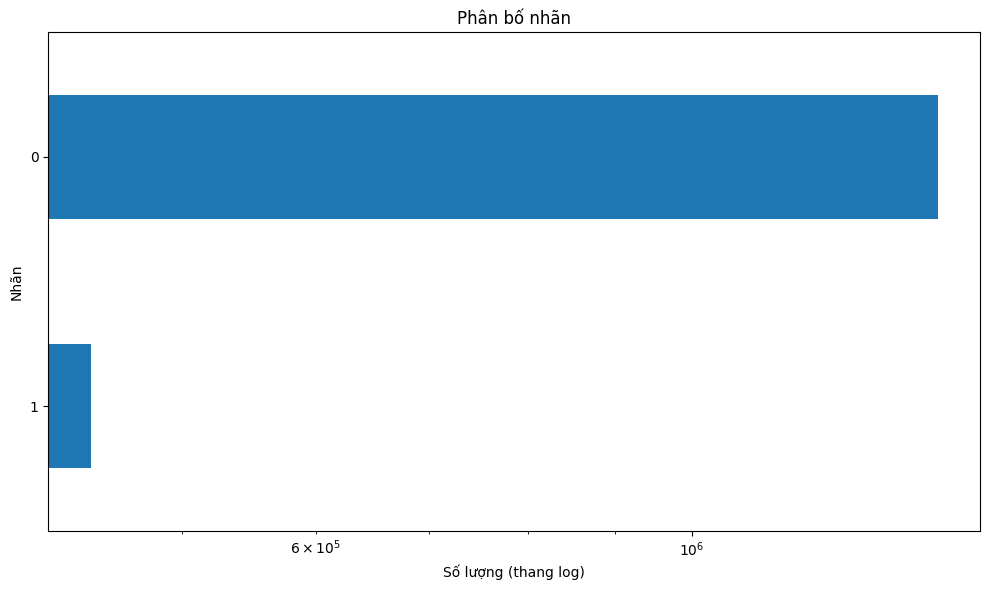

In [37]:
# Kiểm tra phân bổ nhãn
ax = label_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

In [38]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(label_table))
print("Lớp nhiều nhất:", label_table.iloc[0]['label'], "-", label_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", label_table.iloc[-1]['label'], "-", label_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(label_table['count'].max() / label_table['count'].min(), 1))

Số lớp: 2
Lớp nhiều nhất: 0.0 - 1395675.0 mẫu
Lớp ít nhất: 1.0 - 441823.0 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.2


### Phân bố - Loại tấn công

In [39]:
# Phân bố nhãn
attack_table = df_raw['attack_type'].value_counts(dropna=False).rename_axis('attack_type').reset_index(name='count')
attack_table['percent'] = (attack_table['count'] / len(df_raw) * 100).round(3)

attack_table

,attack_type,count,percent
0,benign,1395675,75.955
1,portscan,160106,8.713
2,dos_hulk,158988,8.652
3,ddos,95683,5.207
4,dos_goldeneye,6765,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4003,0.218
8,ssh_patator,2959,0.161
9,webattack_bruteforce,1360,0.074


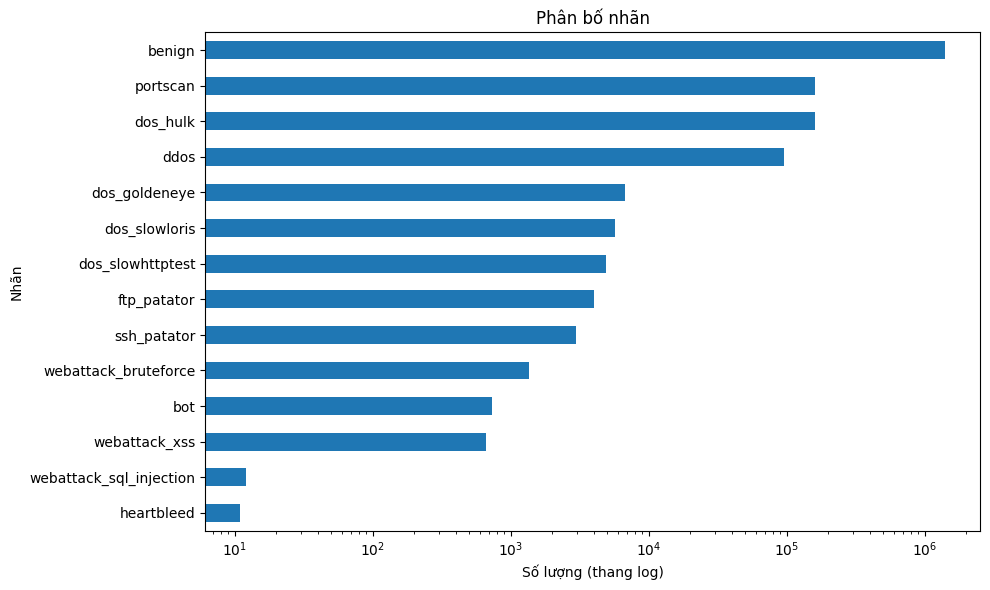

In [40]:
# Kiểm tra phân bổ nhãn
ax = attack_table.sort_values('count').plot.barh(
    x='attack_type',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

In [41]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(attack_table))
print("Lớp nhiều nhất:", attack_table.iloc[0]['attack_type'], "-", attack_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", attack_table.iloc[-1]['attack_type'], "-", attack_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(attack_table['count'].max() / attack_table['count'].min(), 1))

Số lớp: 14
Lớp nhiều nhất: benign - 1395675 mẫu
Lớp ít nhất: heartbleed - 11 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 126879.5


## Features - numeric

### Thống kê mô tả

In [42]:
# Thống kê mô tả
df_raw[numeric_cols].describe()

,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes
count,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1837498.0,1837498.0,1837498.0,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06
mean,1.499277e+15,1.199375e+07,1.051375e+00,1.388679e+03,2.117446e+01,3.051886e+02,9.484971e+05,4.775796e+02,5.902847e+05,1.233599e+04,7.515683e+03,4.820309e+03,1.214130e+01,5.751877e+02,2.156581e+02,2.143513e+01,6.066870e+01,7.115022e+01,2.770368e+02,1.793393e+01,2.751816e+00,1.467427e+01,2.396352e+04,1.351654e+03,1.550679e-01,4.759030e+02,5.322375e+02,3.280494e+02,1.684333e+01,1.268193e+01,4.592725e+06,1.820236e+04,8.792799e+05,1.721531e+06,1.163050e+07,4.417167e+06,1.214749e+06,2.005897e+06,1.244304e+06,1.091002e+07,3.891474e+06,1.353950e+06,2.072981e+06,9.999340e+05,1.827067e+05,6.236271e+04,9.085547e+04,5.248137e+04,4.033050e+06,3.658133e+06,3.855138e+06,2.046651e+05,9.387292e-01,3.834197e-01,9.971603e-02,2.442314e+01,3.168392e+00,1.415754e+00,1.752638e+00,0.0,0.0,0.0,4.087079e-04,6.057149e-04,6.775367e+01,2.369940e-01,1.821951e+05,4.215857e+03,2.093305e+00,2.855677e+06,2.681484e+02,6.813951e+00,1.395996e+04,8.270970e+00,1.069511e+04,1.146236e+04
std,1.302638e+11,3.091508e+07,4.082071e-01,2.375817e+03,2.643862e+01,4.622562e+02,2.627050e+06,8.487727e+02,8.554230e+06,6.437455e+04,5.069289e+04,2.674976e+04,9.299889e+02,5.453320e+03,4.787516e+02,3.567512e+01,9.875525e+01,1.549067e+02,1.943498e+04,1.079900e+01,6.477690e+00,1.237128e+03,2.807826e+06,2.364553e+03,6.027267e+00,7.377988e+02,1.044318e+03,2.477432e+04,9.914960e+00,1.236598e+03,1.427997e+07,2.505621e+05,3.445050e+06,6.219367e+06,3.078804e+07,1.426006e+07,9.487244e+06,9.758034e+06,4.235076e+06,3.004978e+07,1.377562e+07,9.815013e+06,1.020862e+07,4.199289e+06,1.104878e+06,6.403329e+05,7.130510e+05,4.322259e+05,1.401476e+07,1.336863e+07,1.356828e+07,2.171198e+06,1.059359e+00,4.862193e-01,2.996211e-01,2.166668e+03,2.880648e+01,4.787257e+00,2.694965e+01,0.0,0.0,0.0,2.888114e-02,3.414518e-02,1.404031e+03,1.642841e+00,4.130112e+06,3.184214e+05,1.130538e+02,1.033698e+07,2.453107e+03,7.225960e+02,2.151137e+06,9.674378e+02,1.568257e+04,1.554986e+04
min,1.499083e+1

### Độ lệch skew

In [43]:
# Kiểm tra lệch
df_num = df_raw[numeric_cols].select_dtypes(include='number')

pd.DataFrame({
    'Skew gốc': df_num.skew(),
    'Skew log': np.log1p(df_num).skew()
}).round(4)

,Skew gốc,Skew log
timestamp,0.0784,0.0783
flow_duration,2.6760,-0.0658
down_up_ratio,1.1333,-0.1882
pkt_len_max,2.1525,-0.5664
pkt_len_min,7.3112,0.0984
...,...,...
fwd_subflow_pkt_mean,257.6945,2.3839
bwd_subflow_bytes_mean,253.3431,-0.4246
bwd_subflow_pkt_mean,258.9417,1.9901
fwd_tcp_init_win_bytes,1.6645,NaN


### Phân bố - histogram

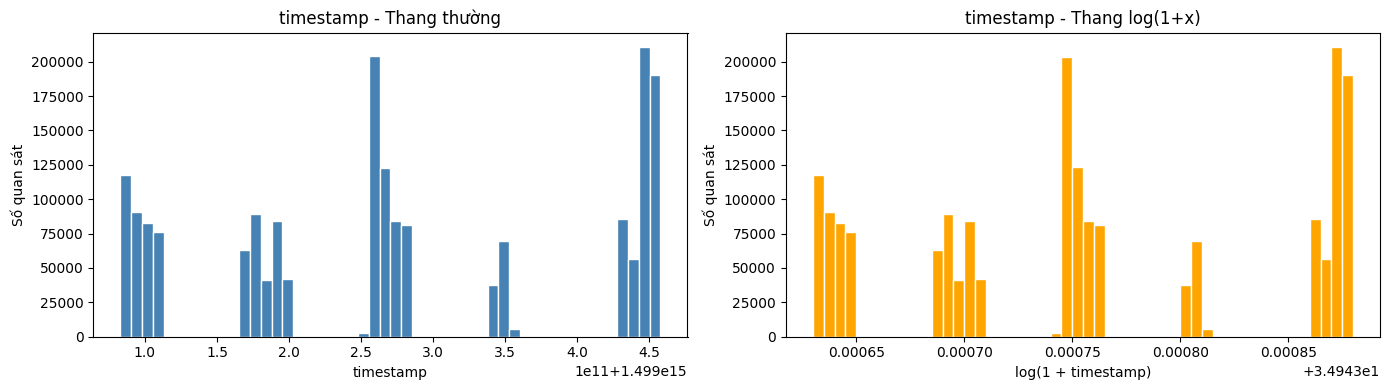

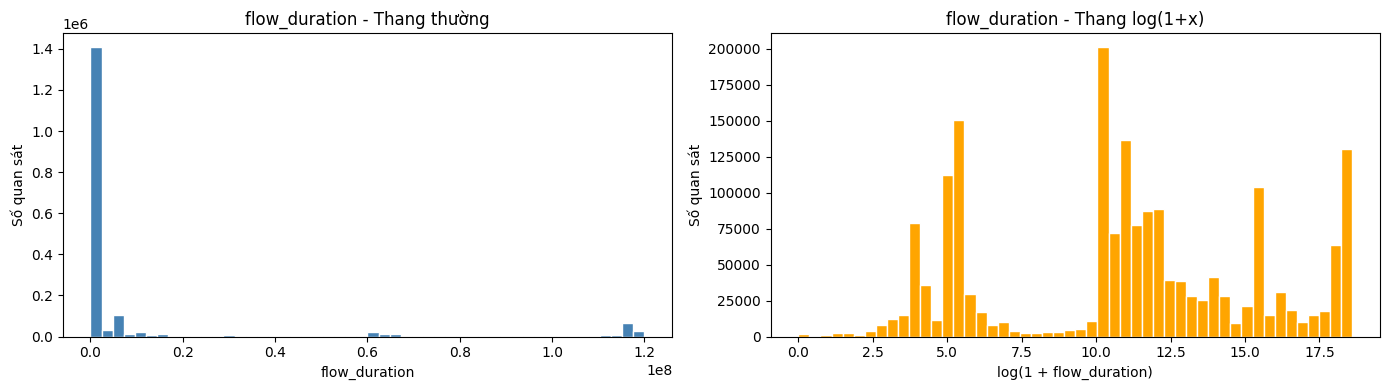

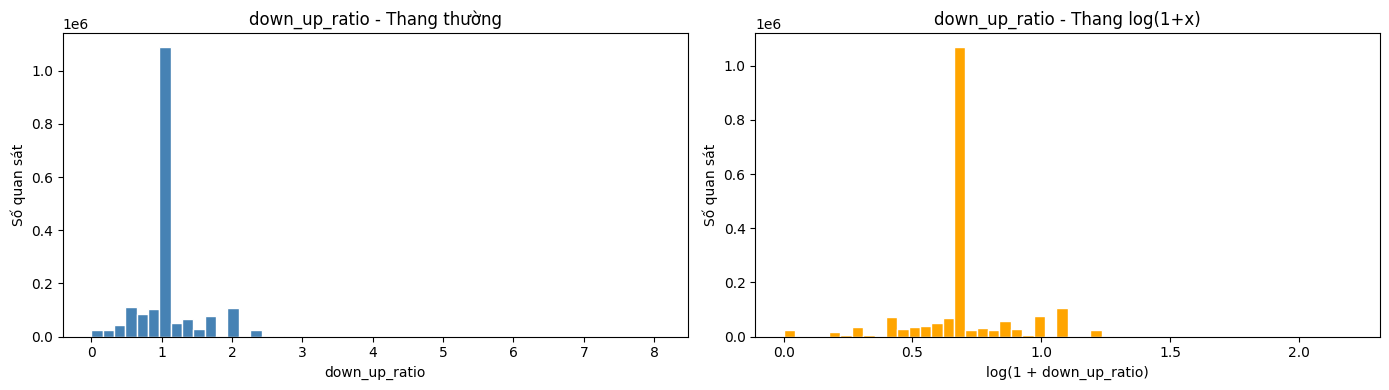

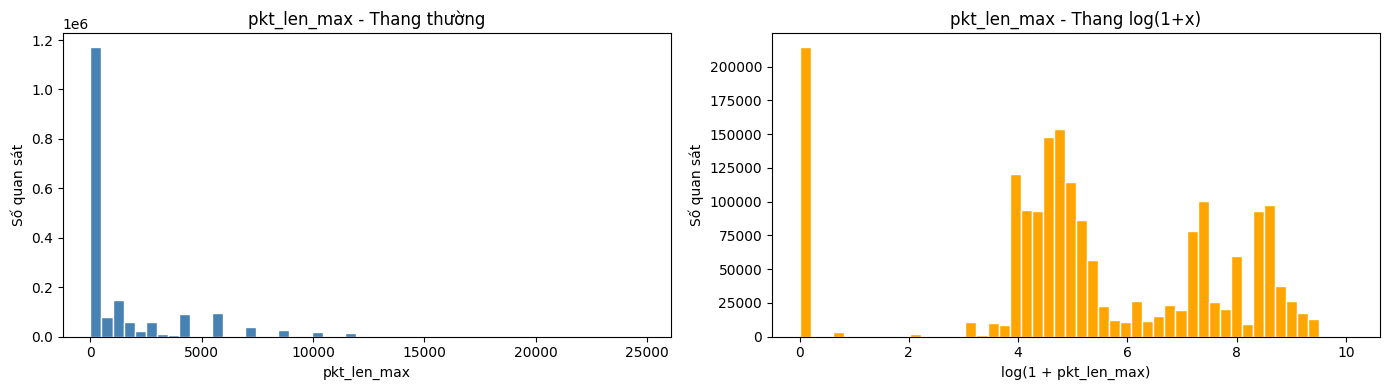

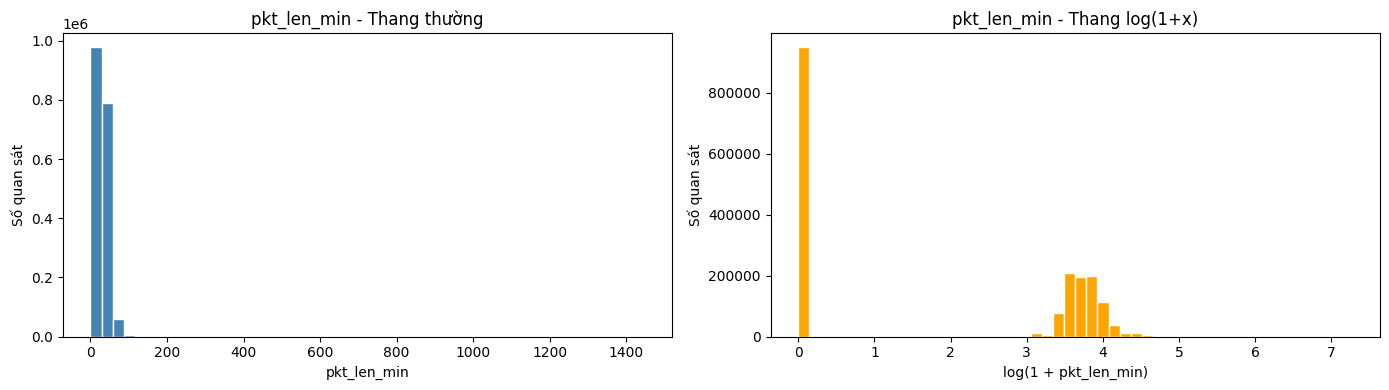

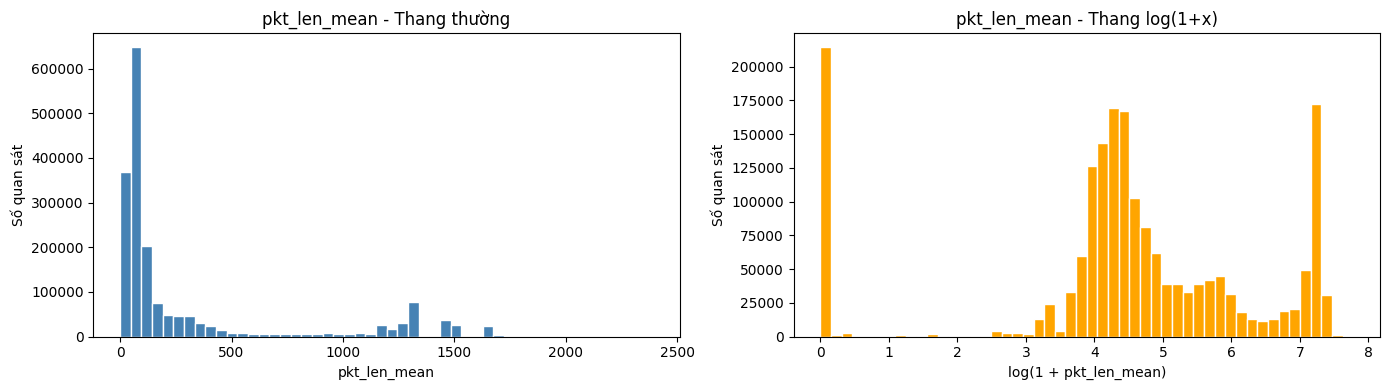

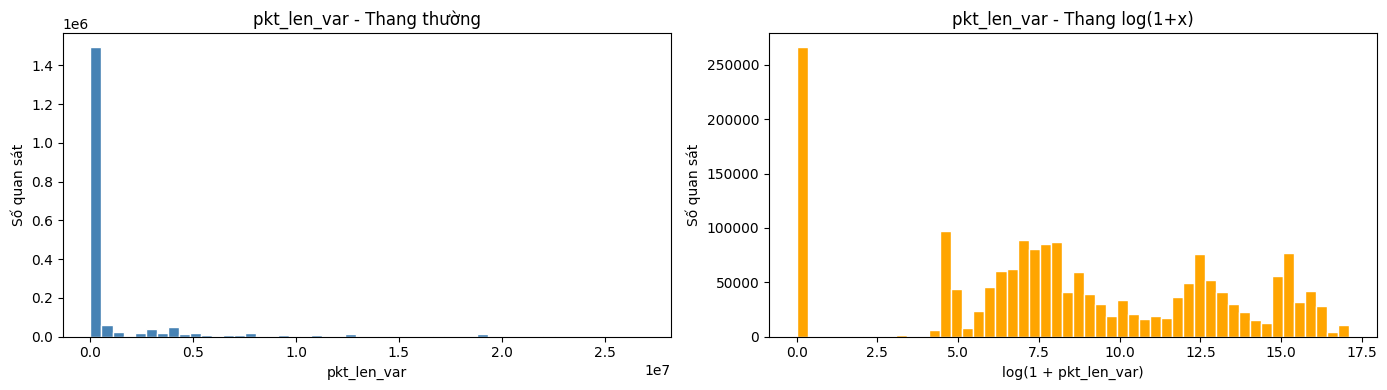

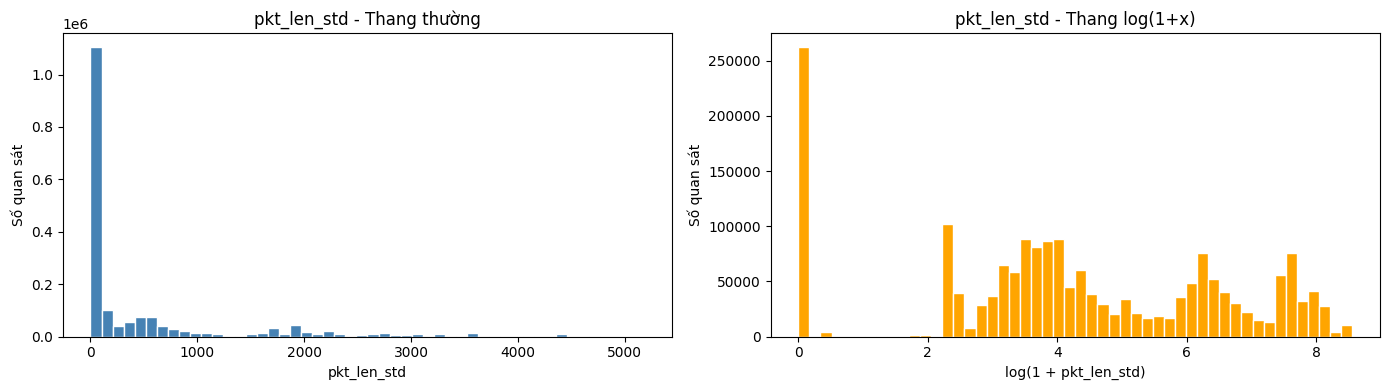

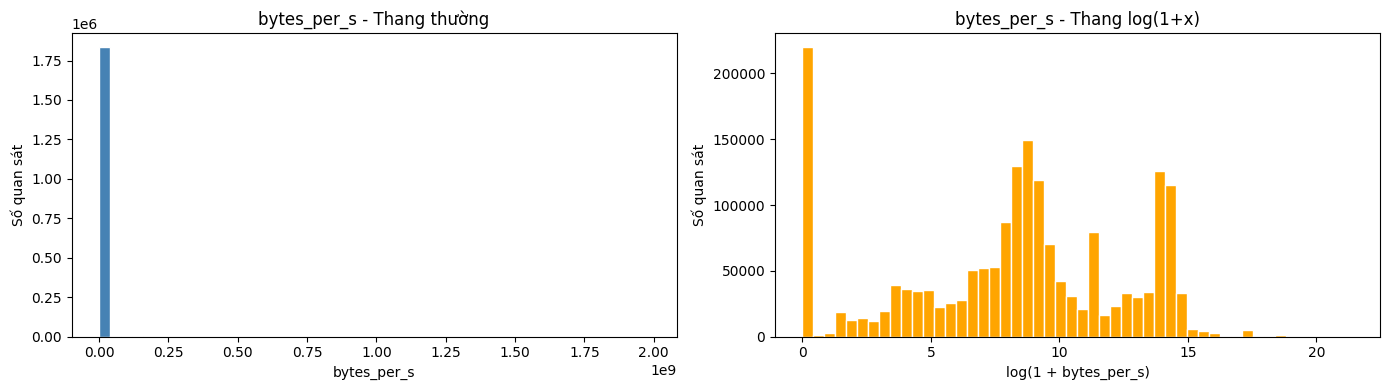

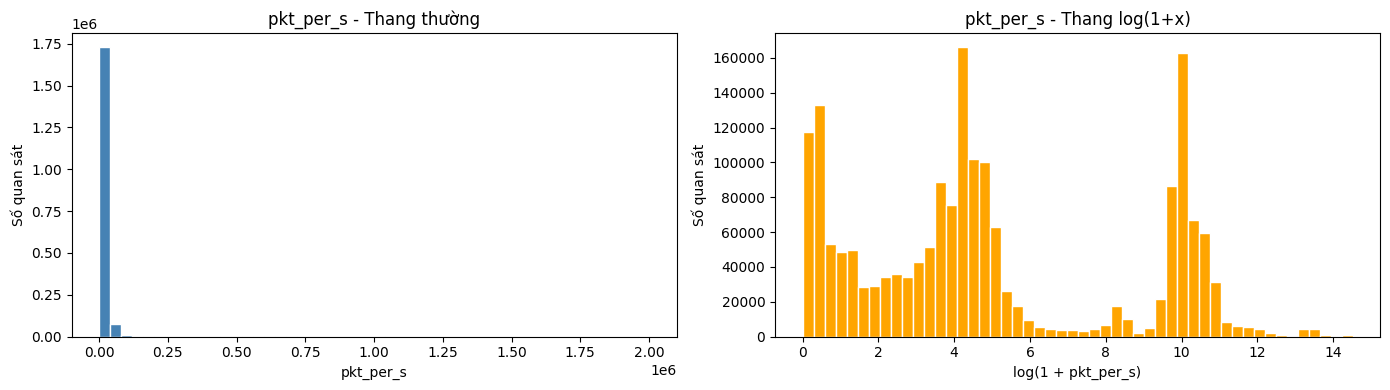

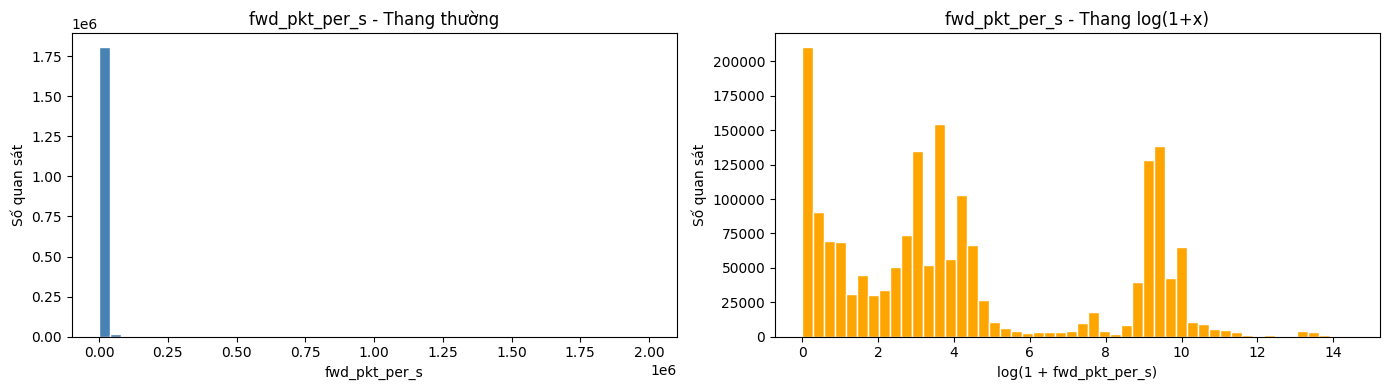

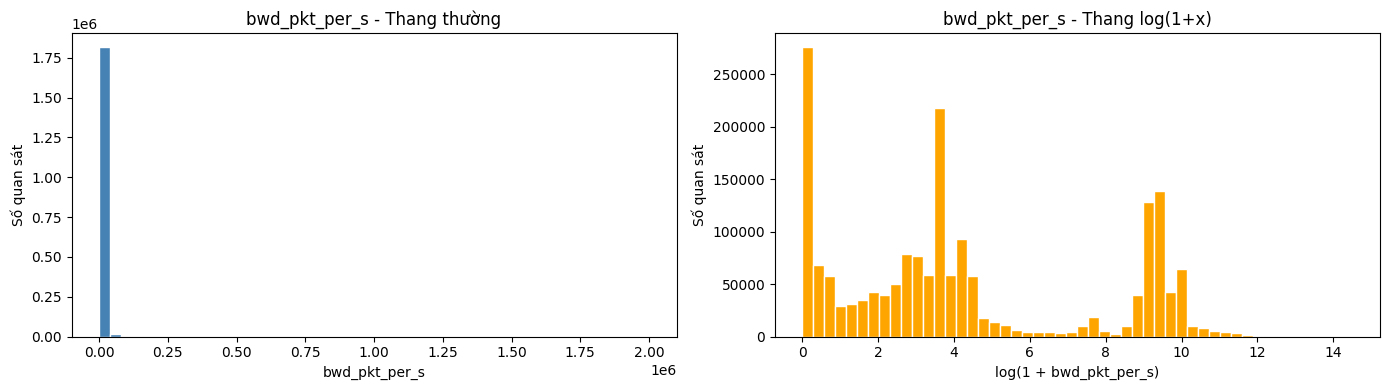

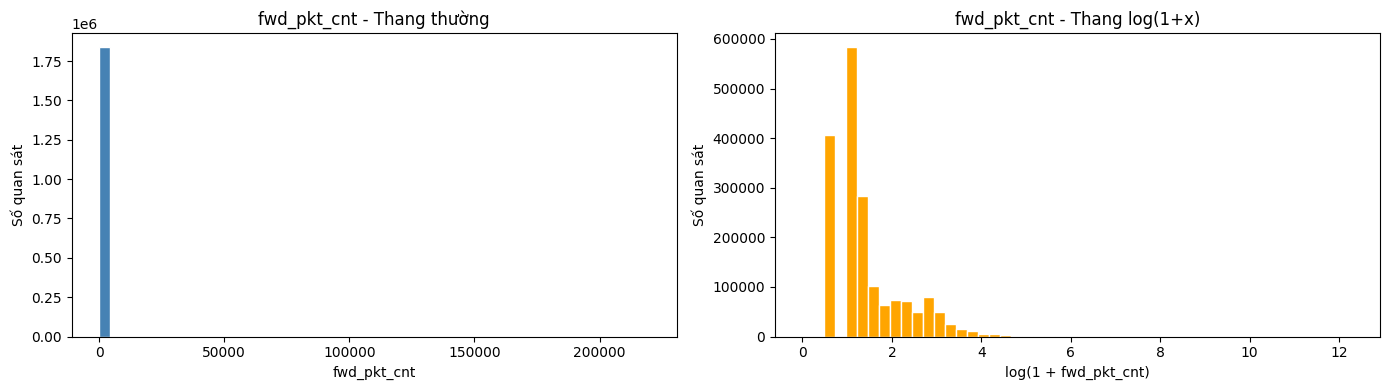

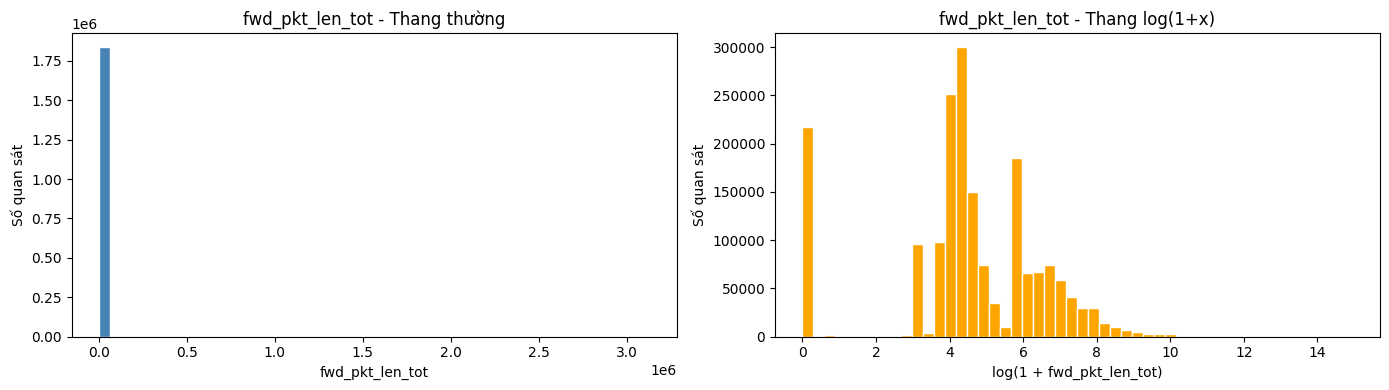

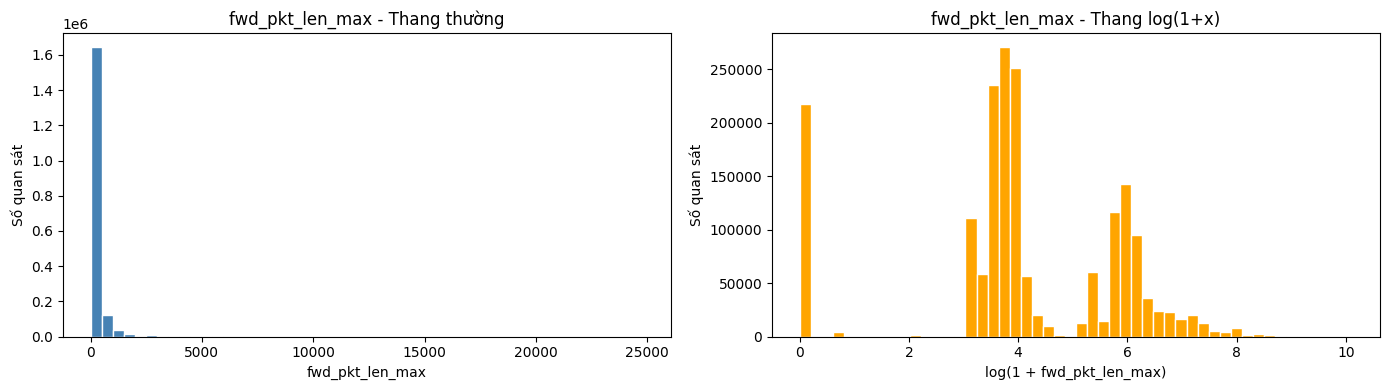

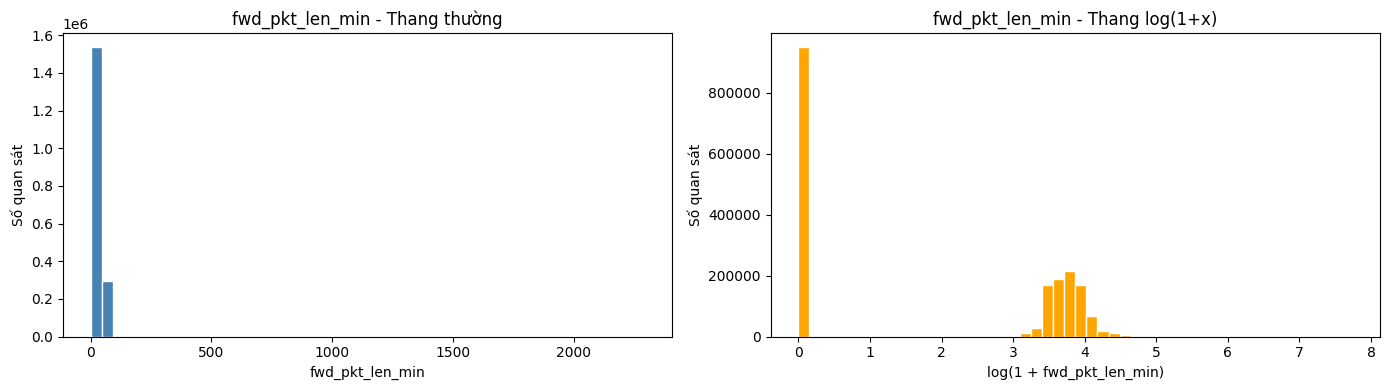

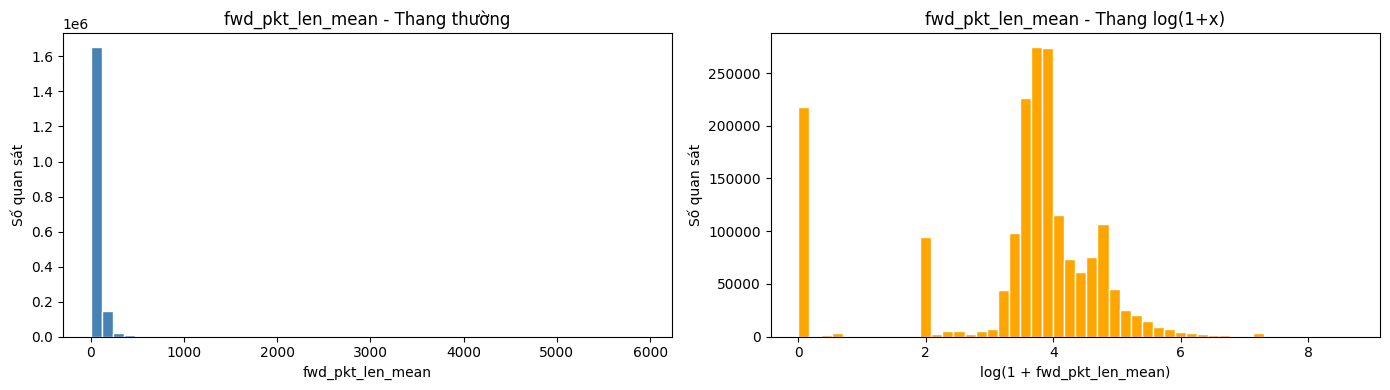

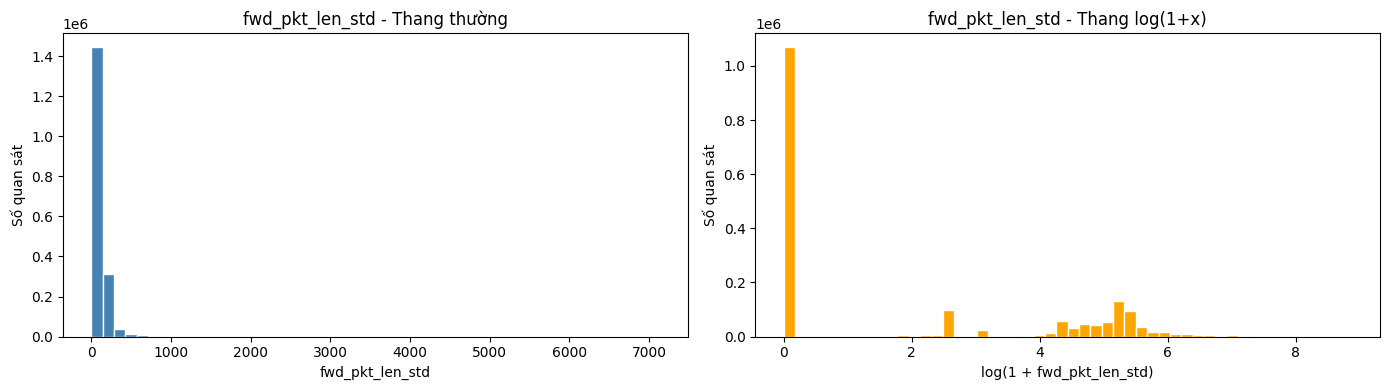

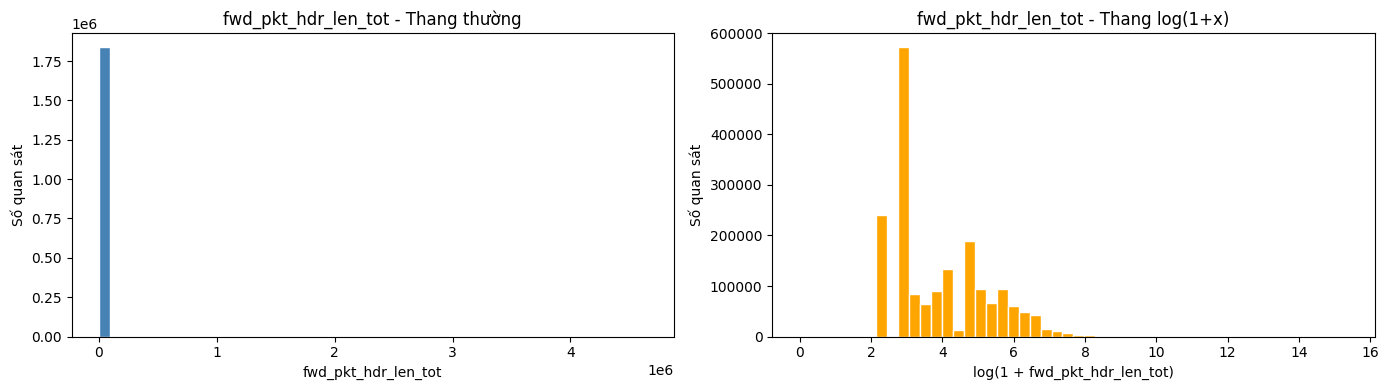

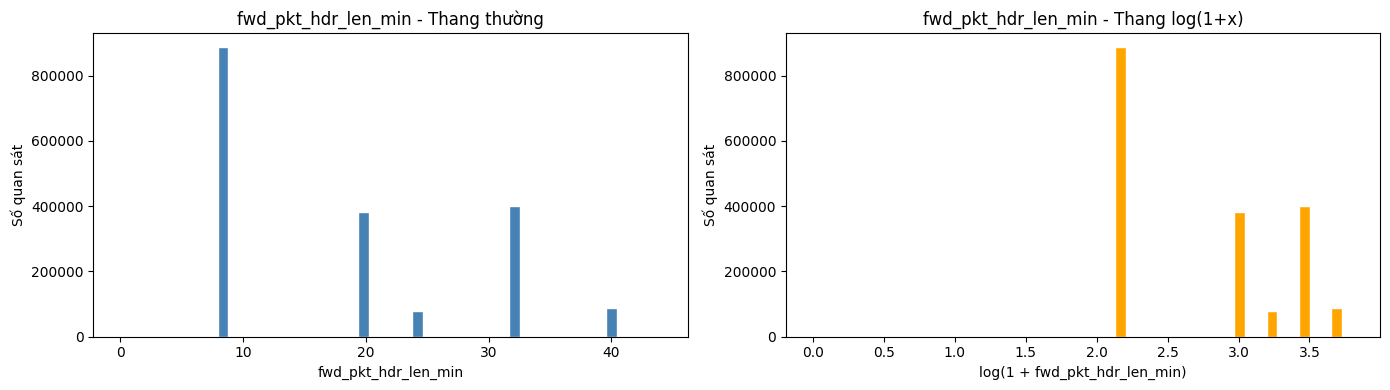

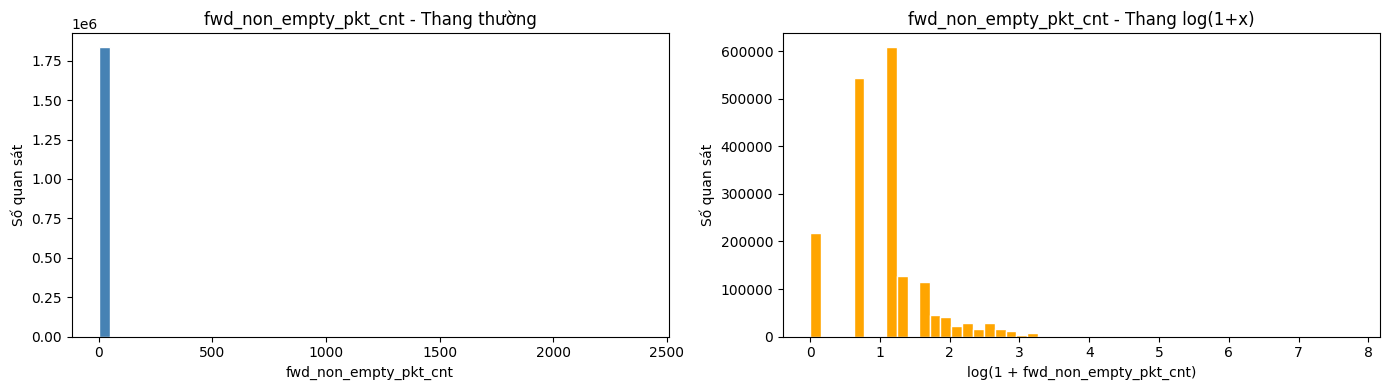

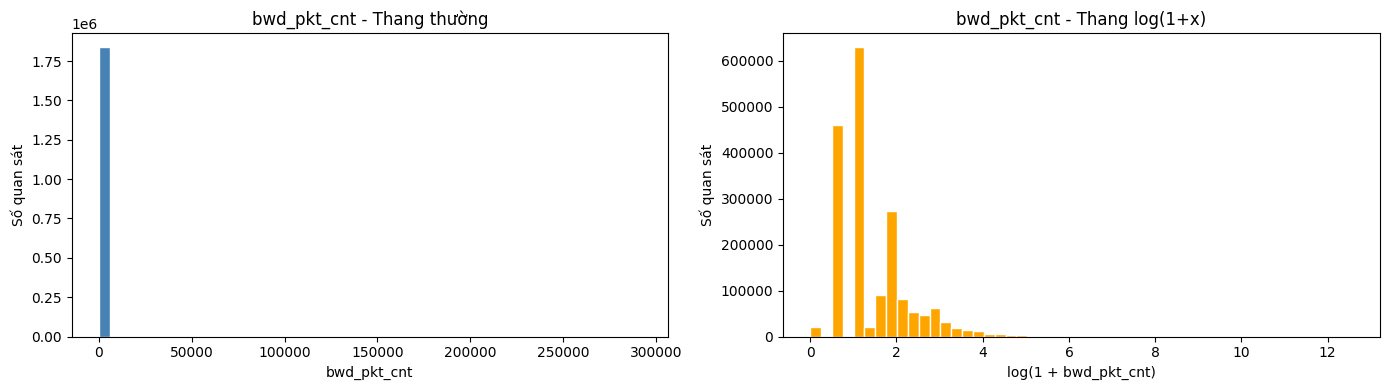

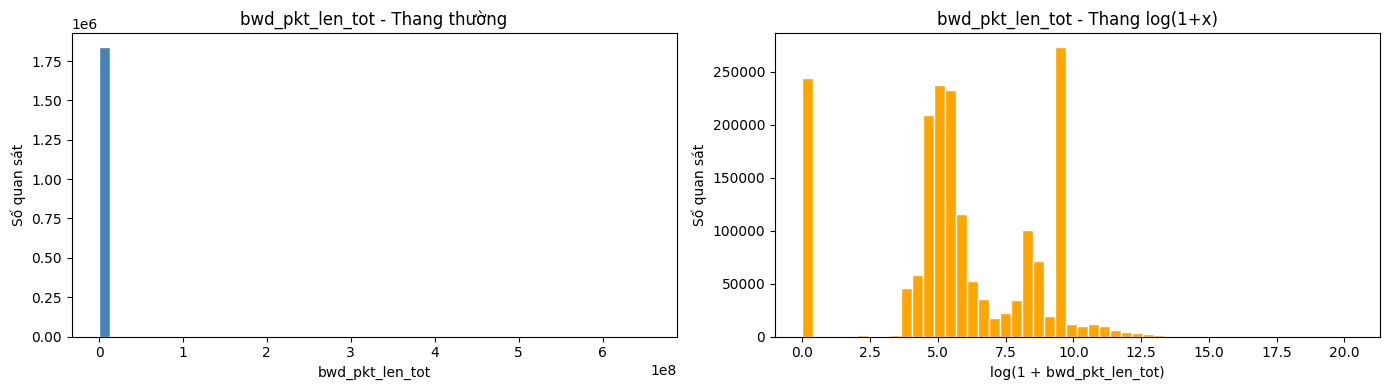

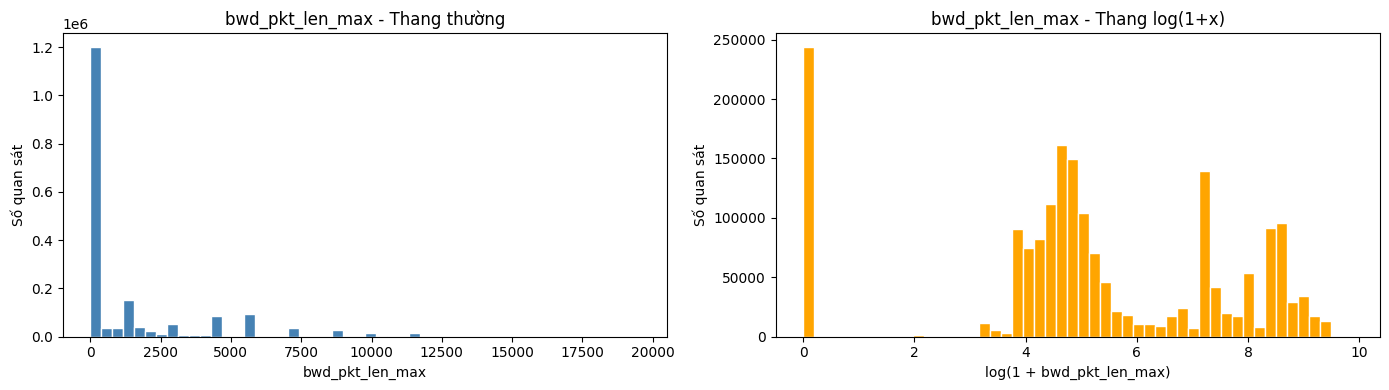

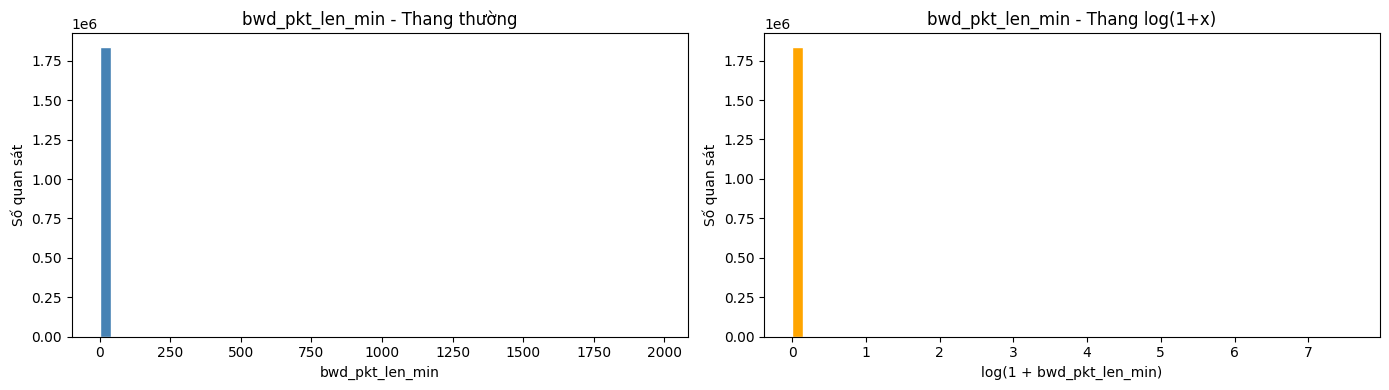

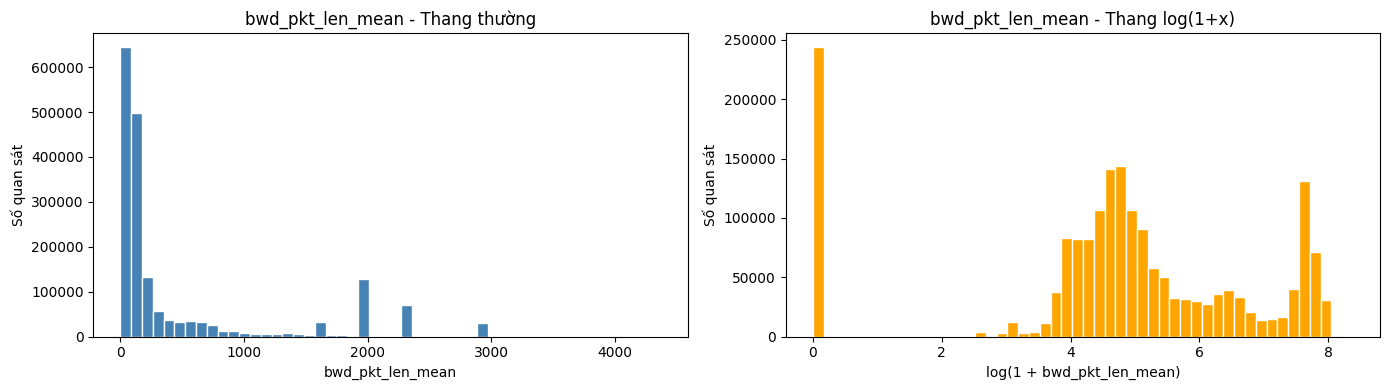

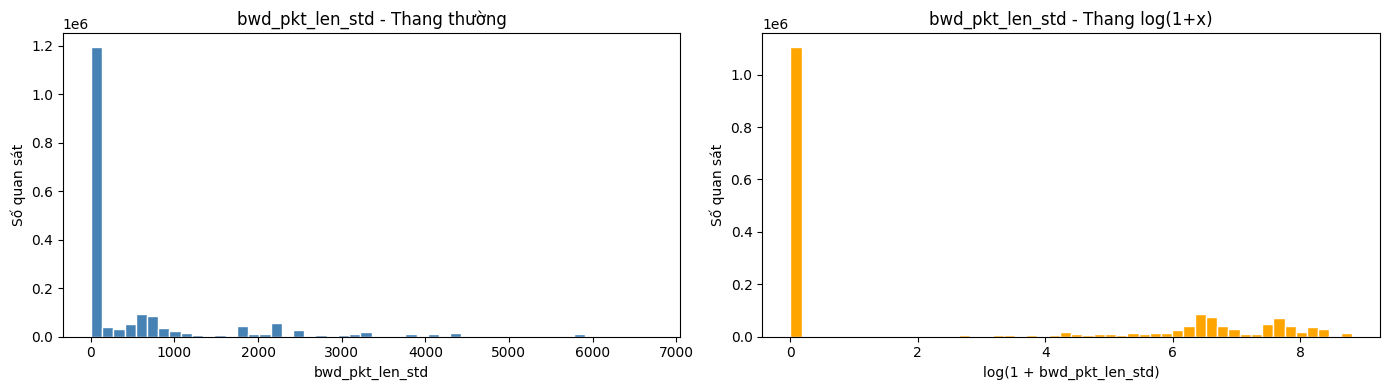

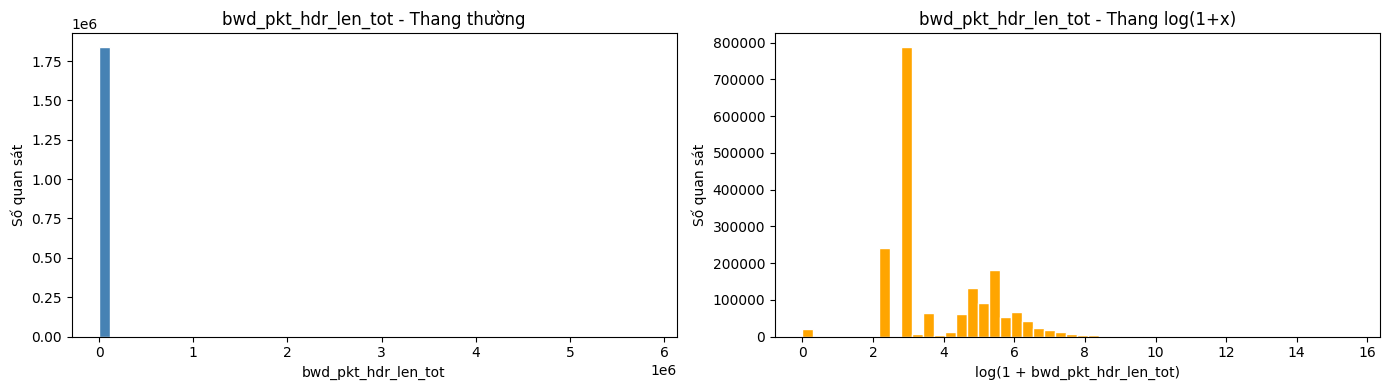

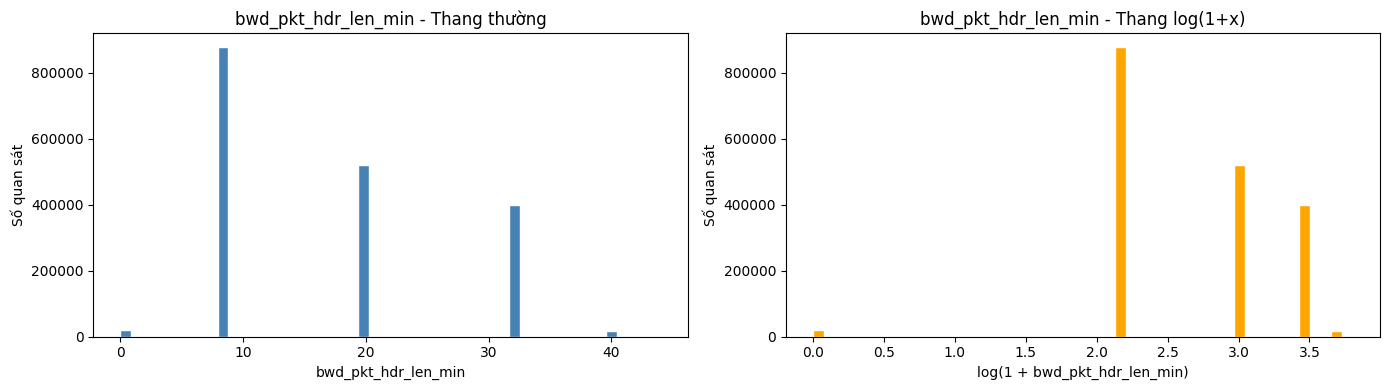

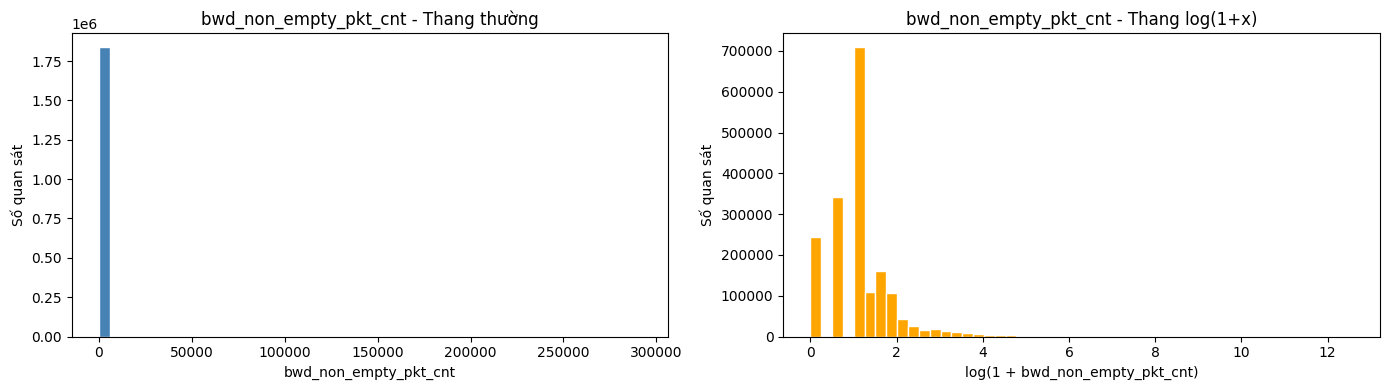

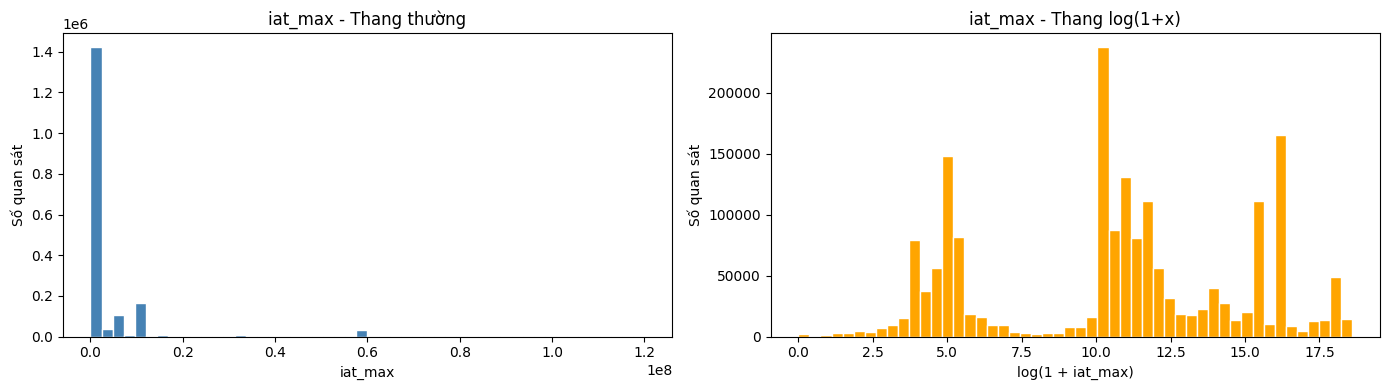

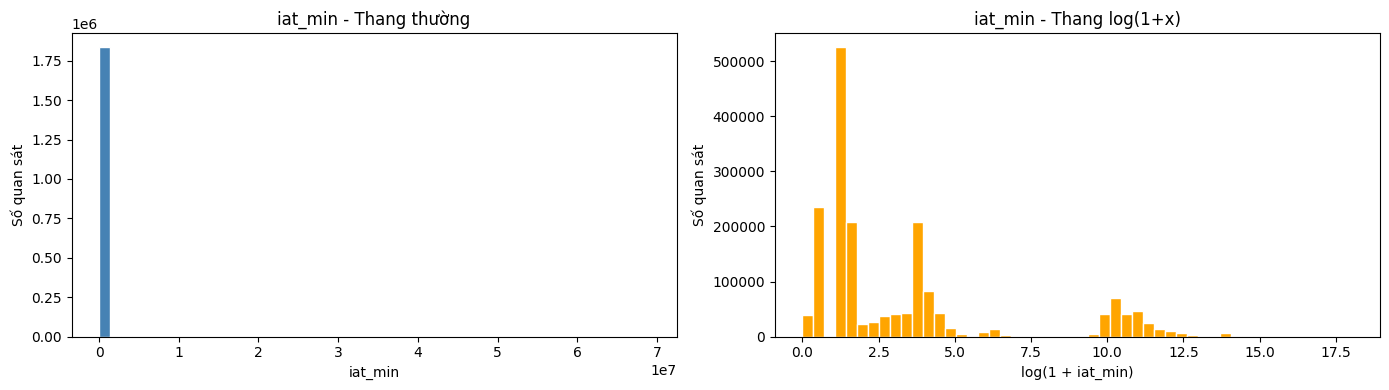

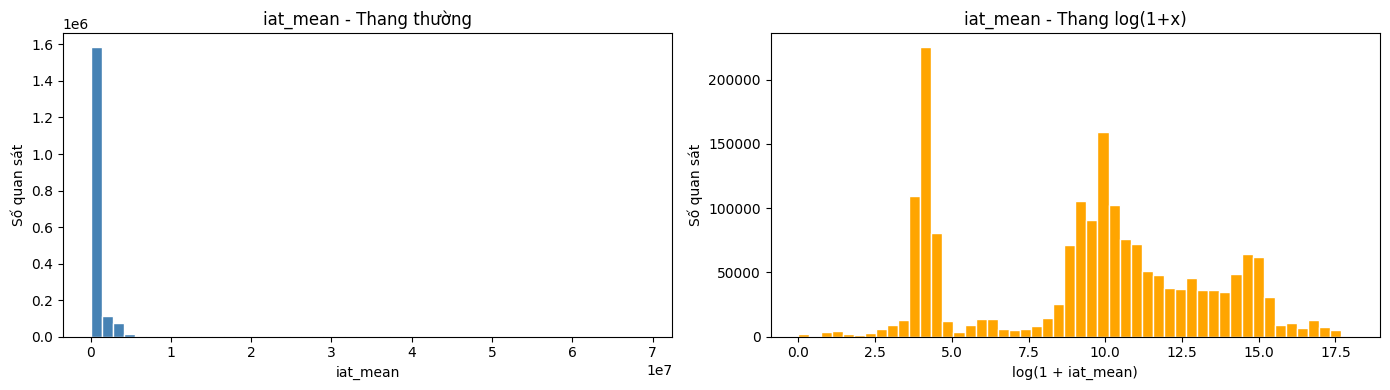

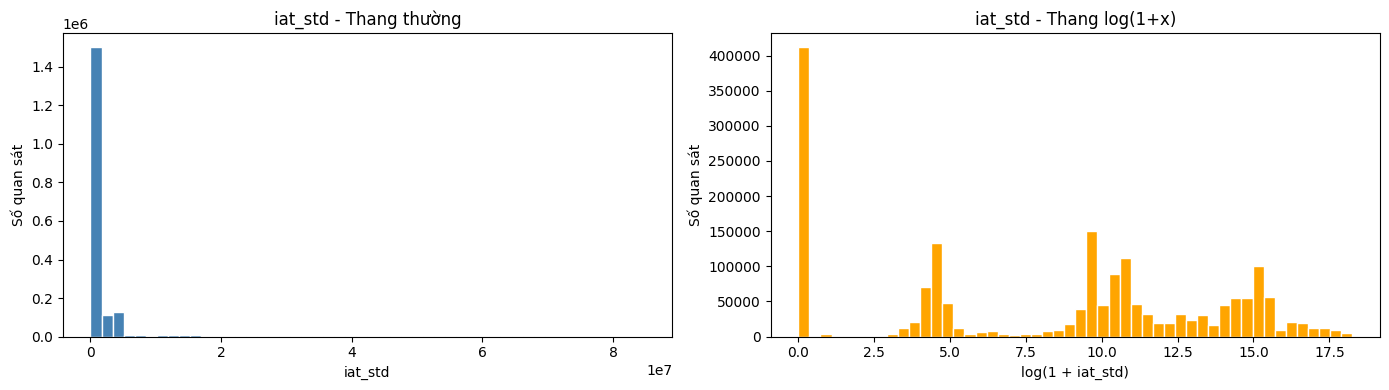

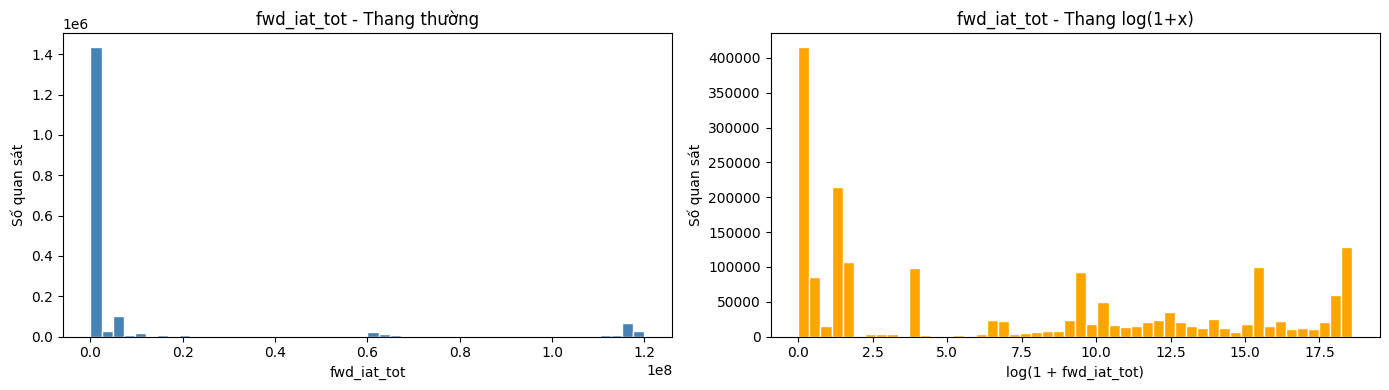

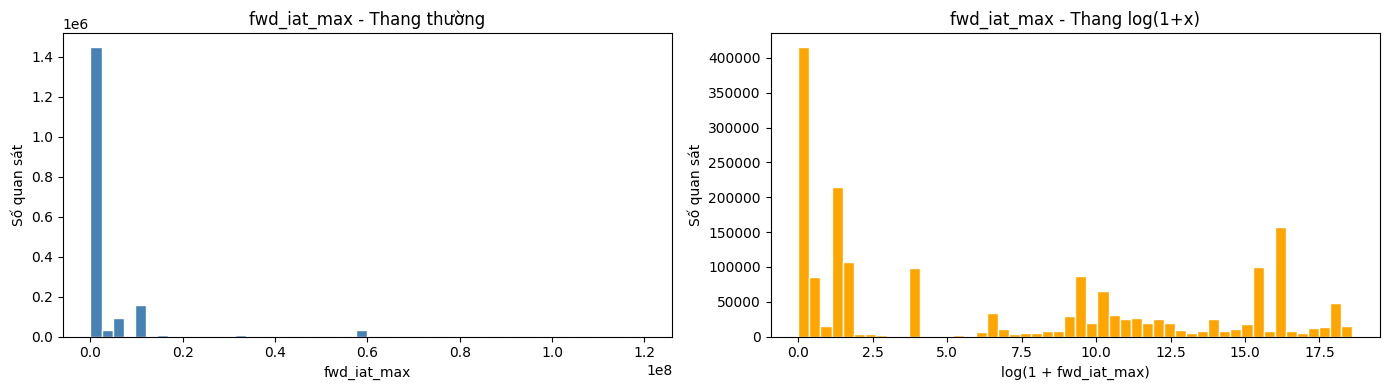

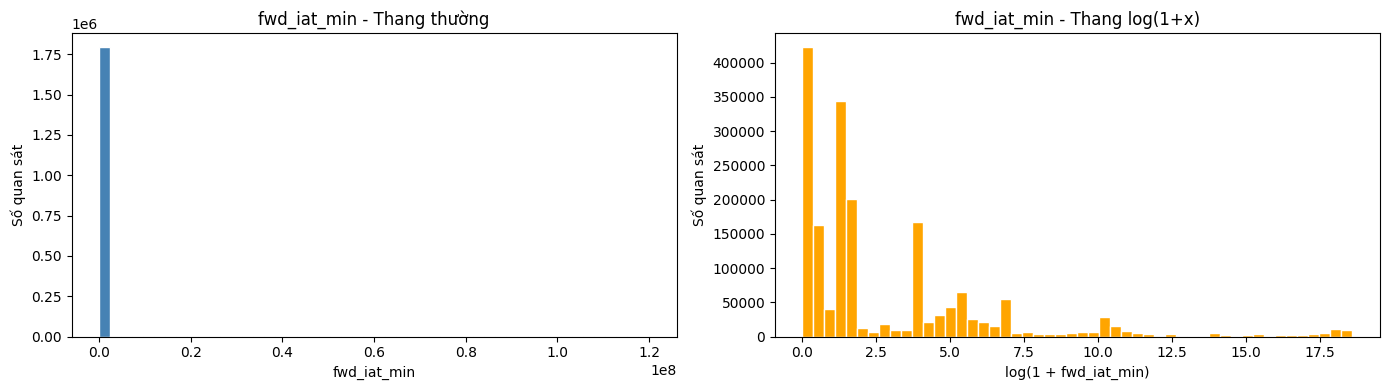

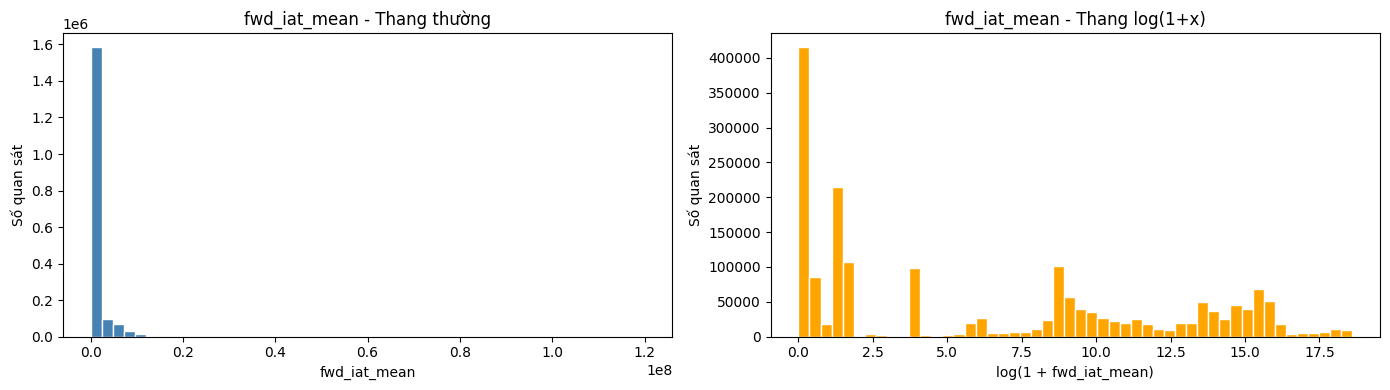

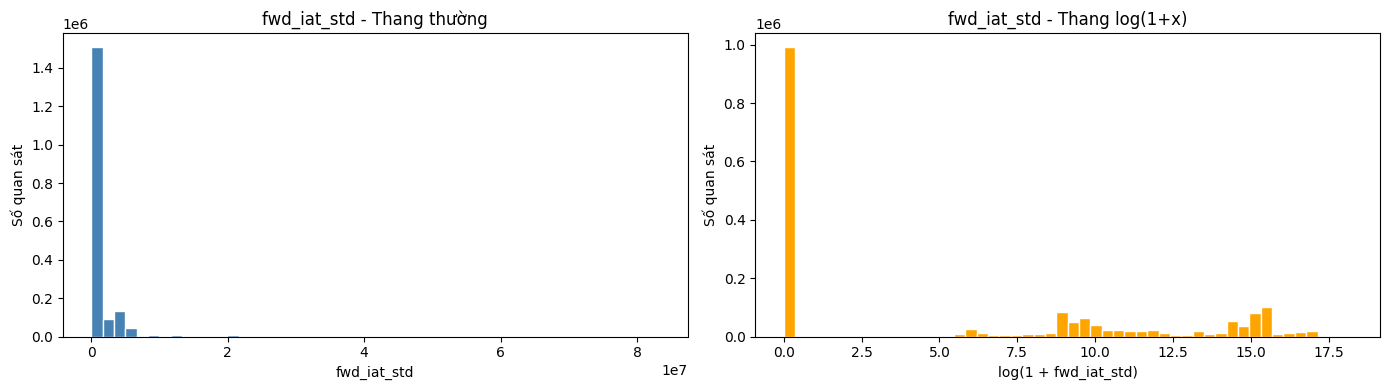

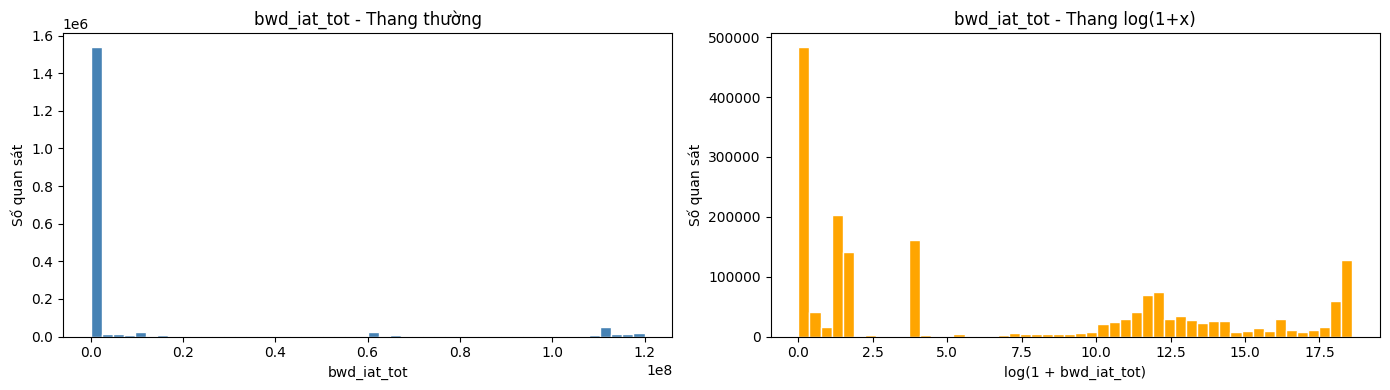

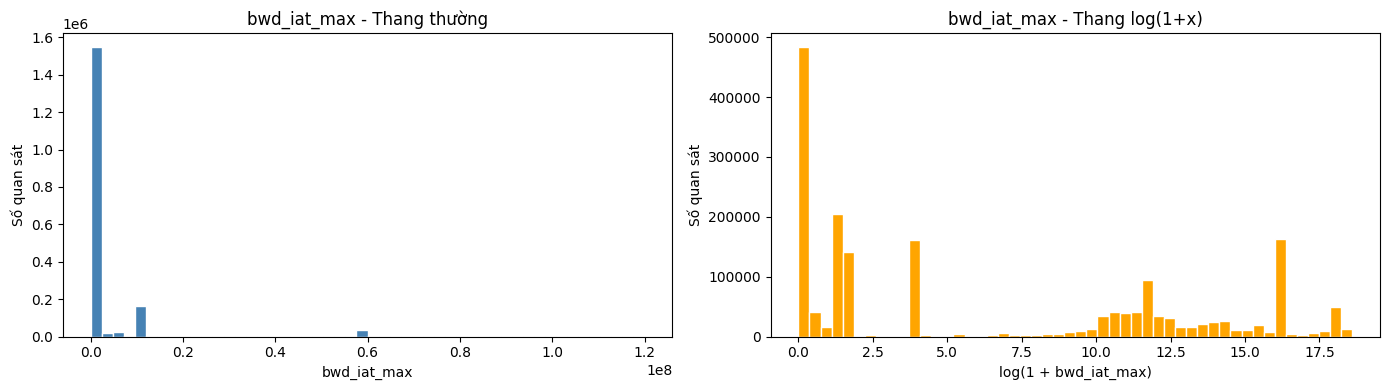

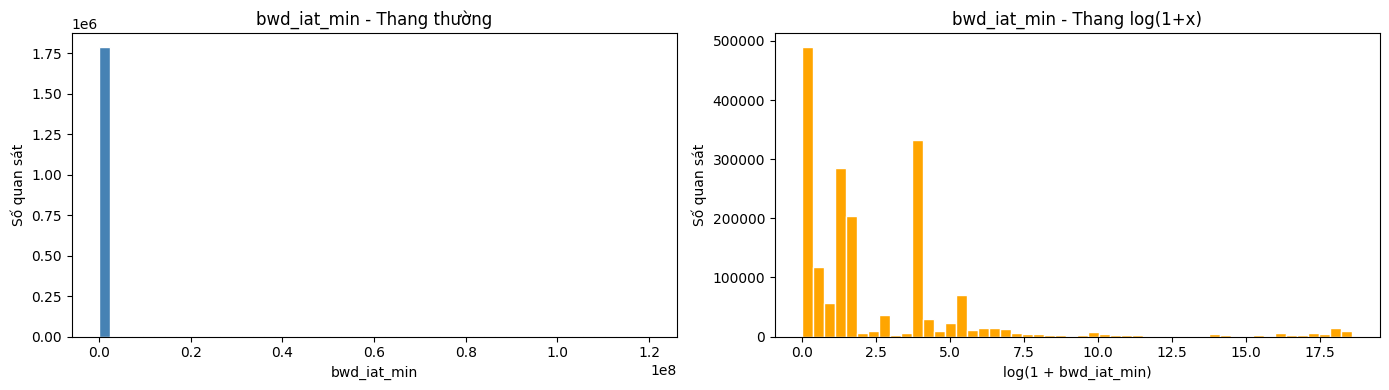

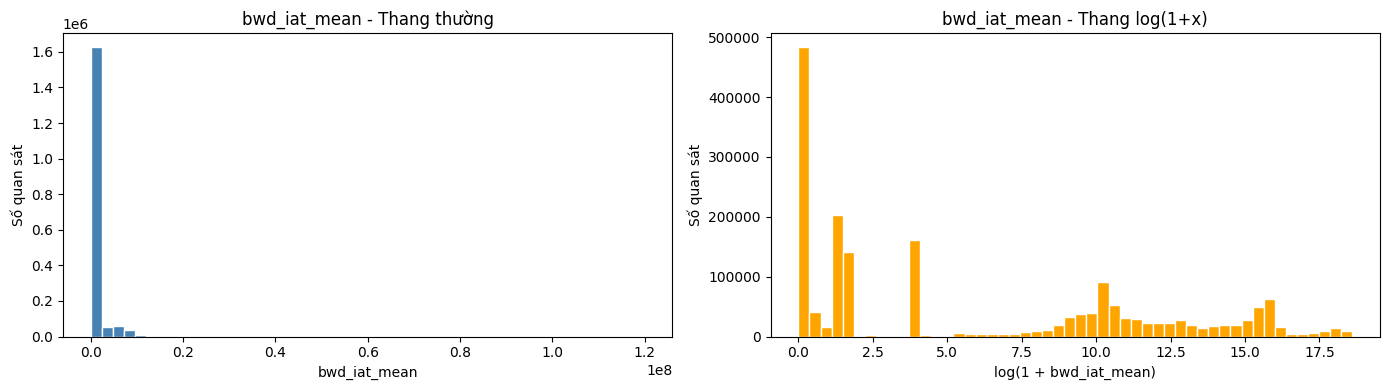

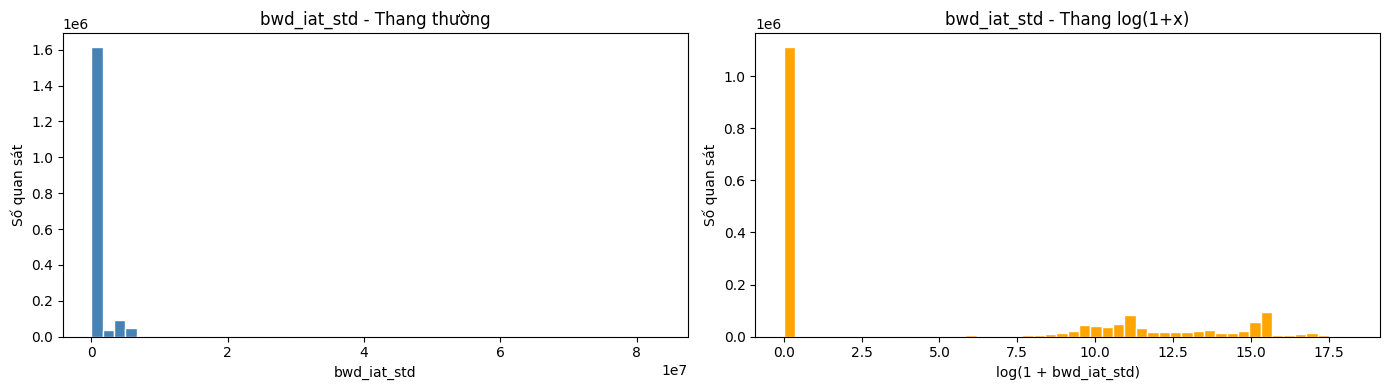

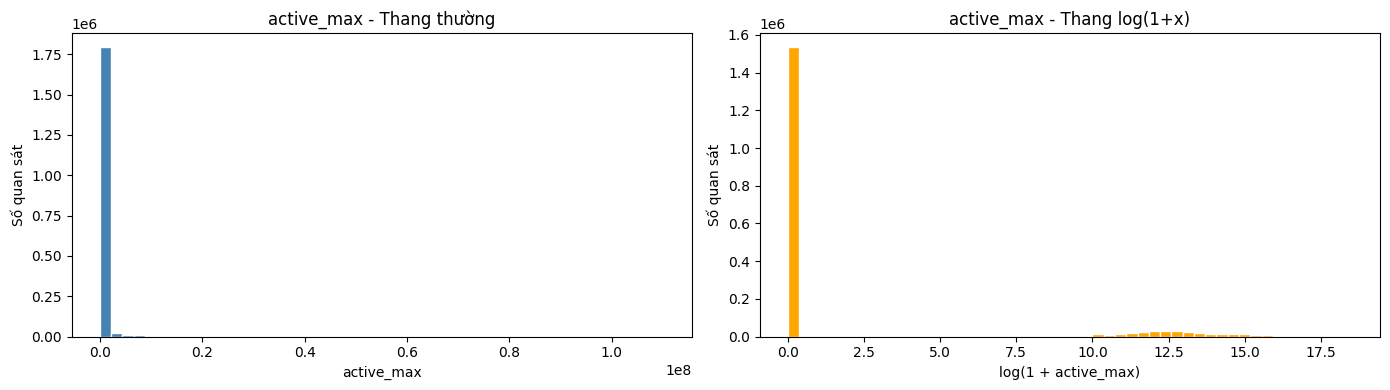

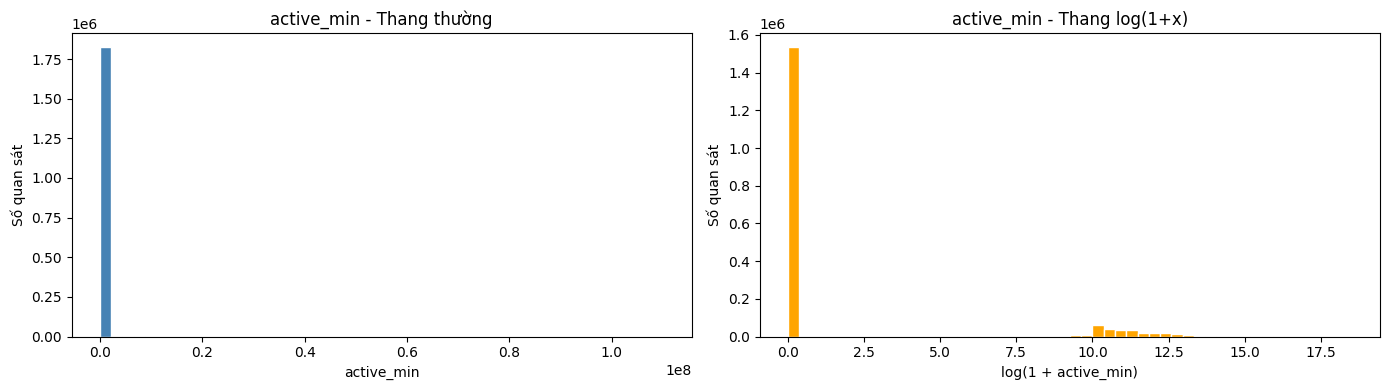

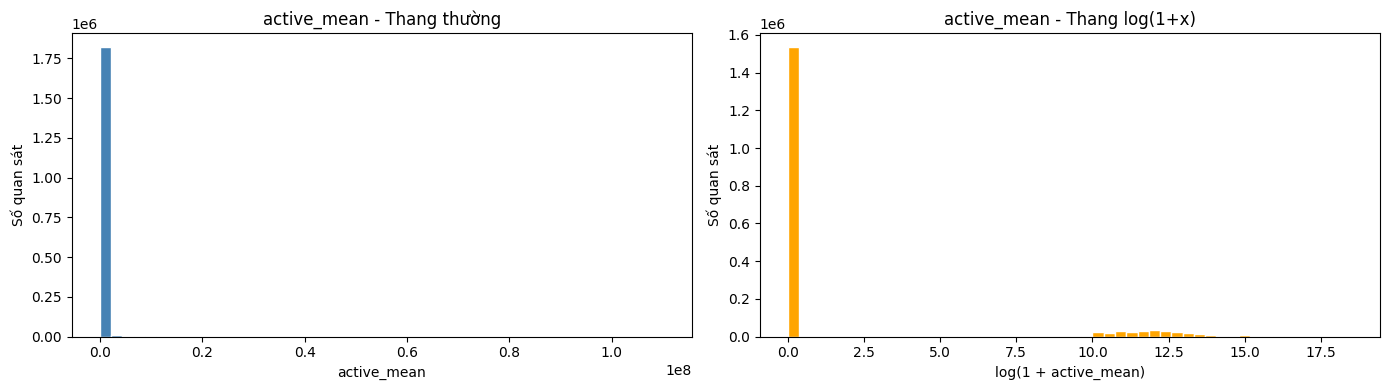

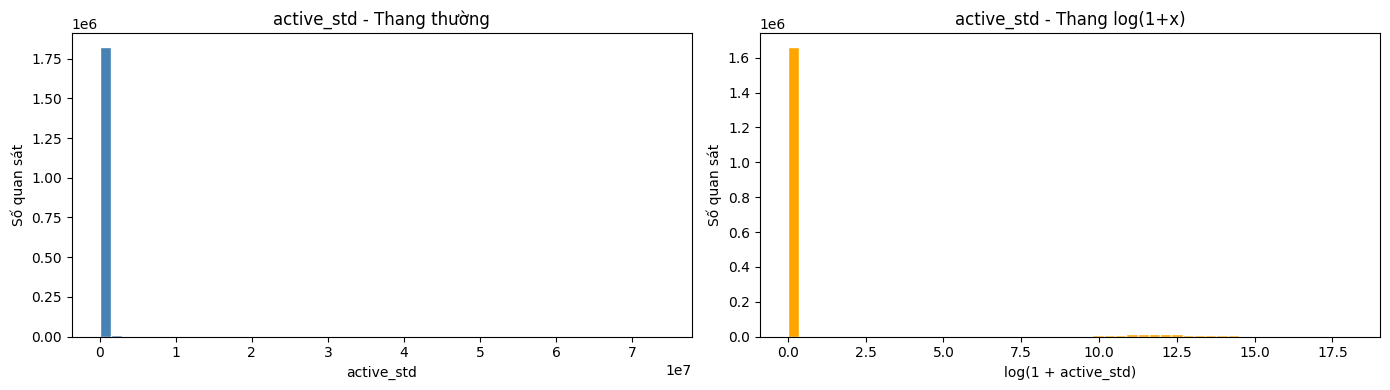

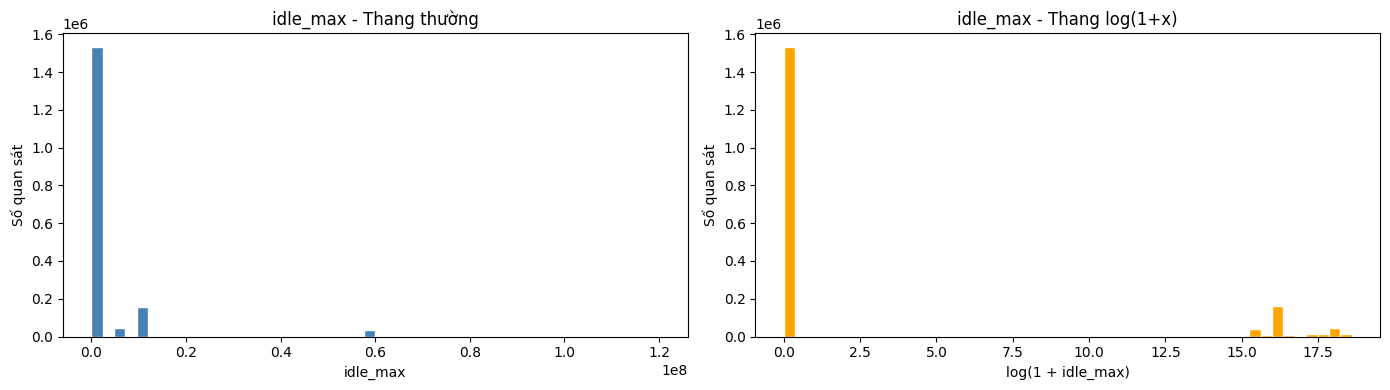

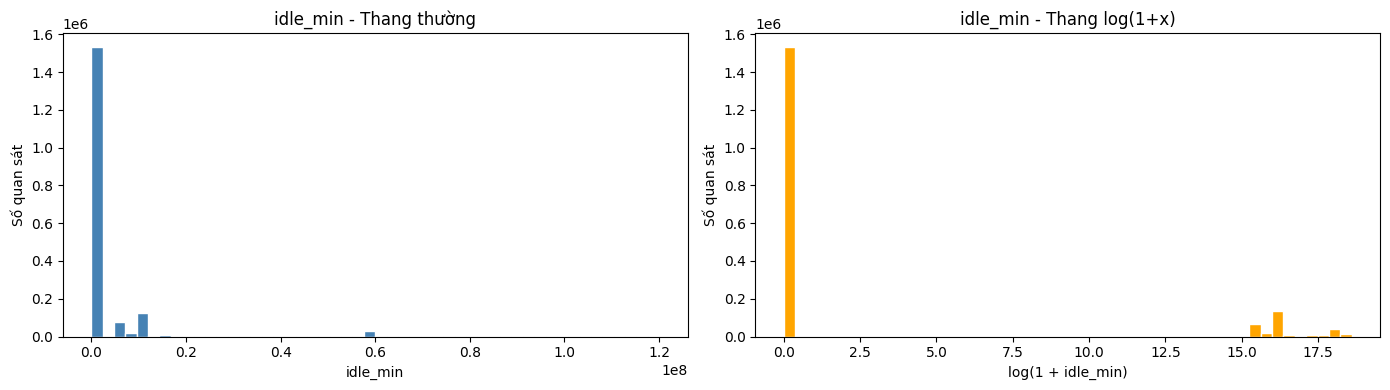

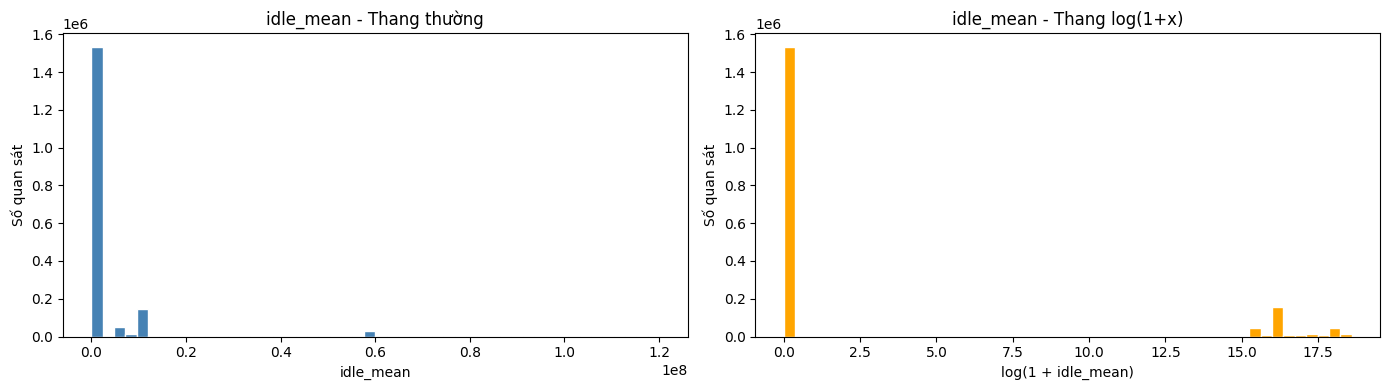

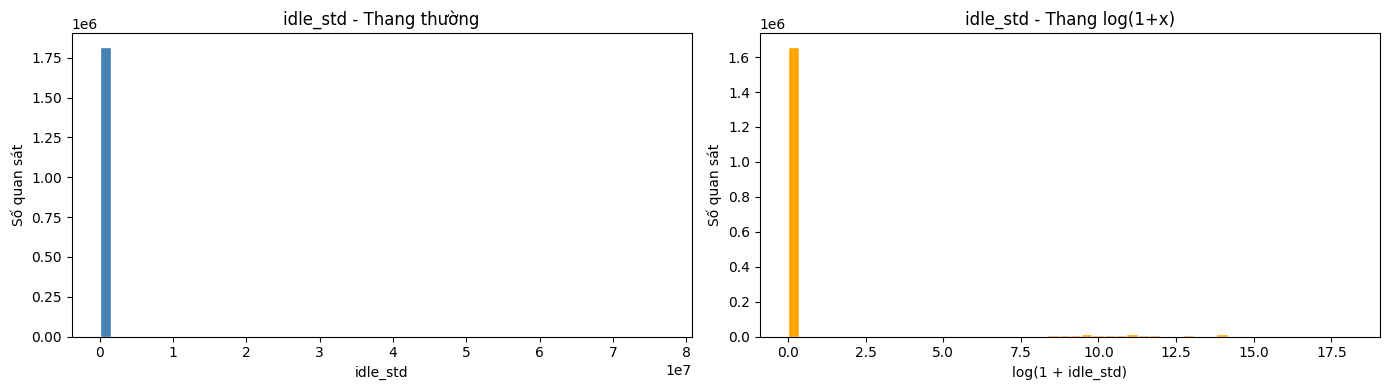

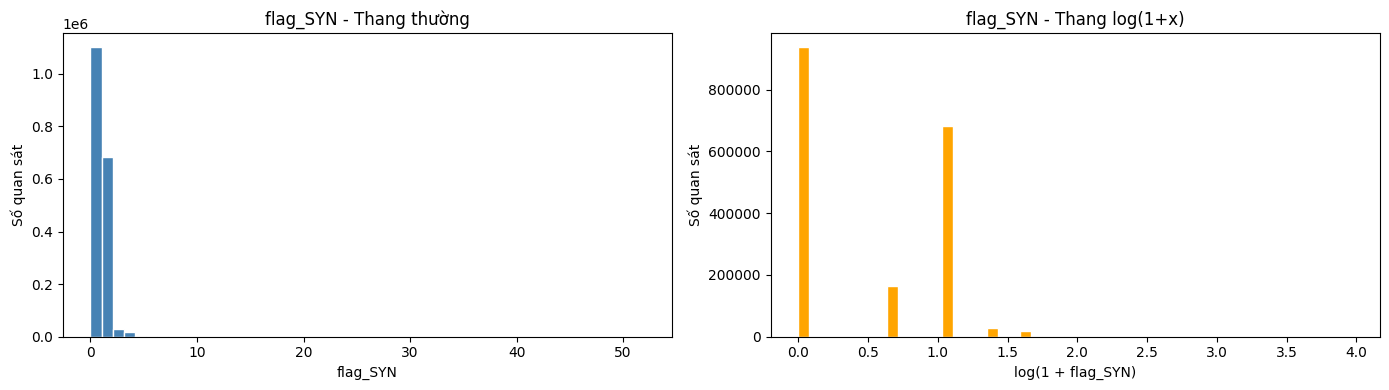

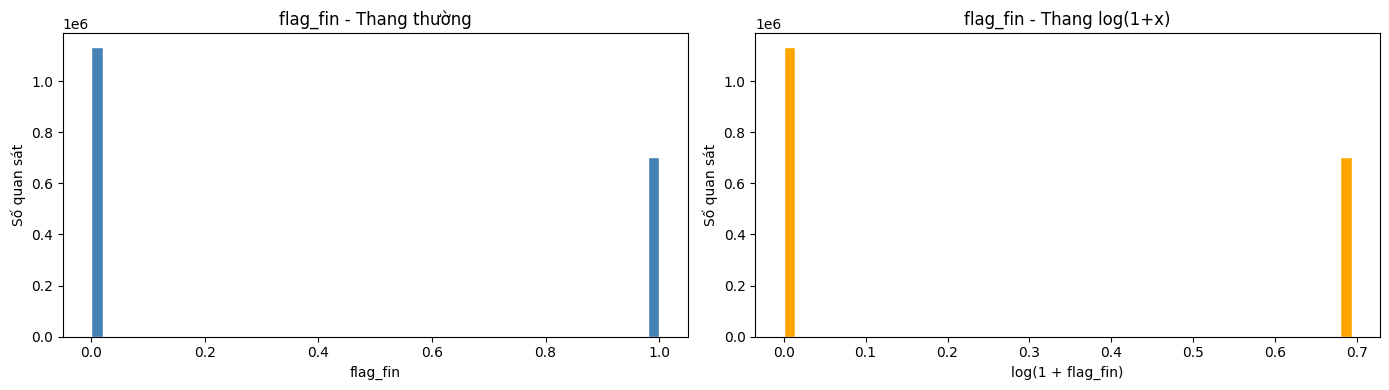

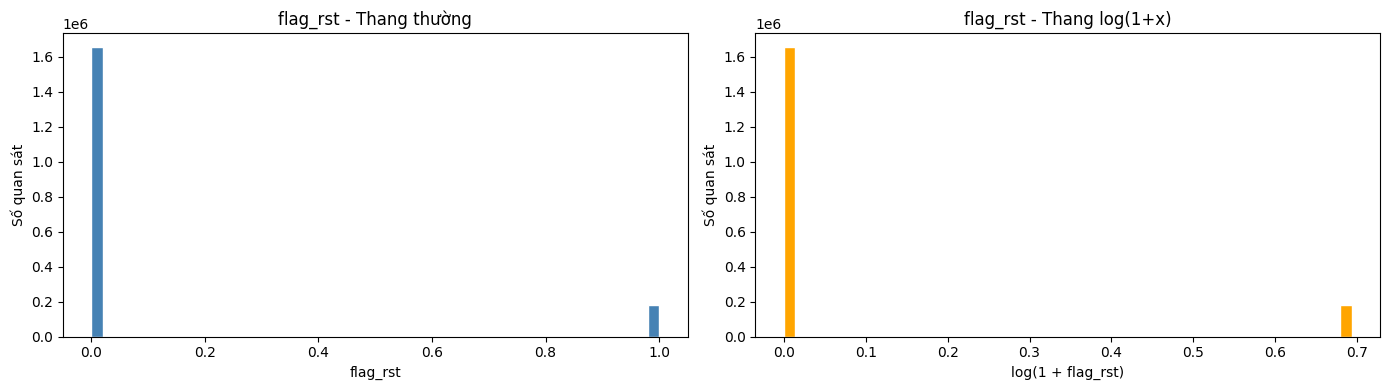

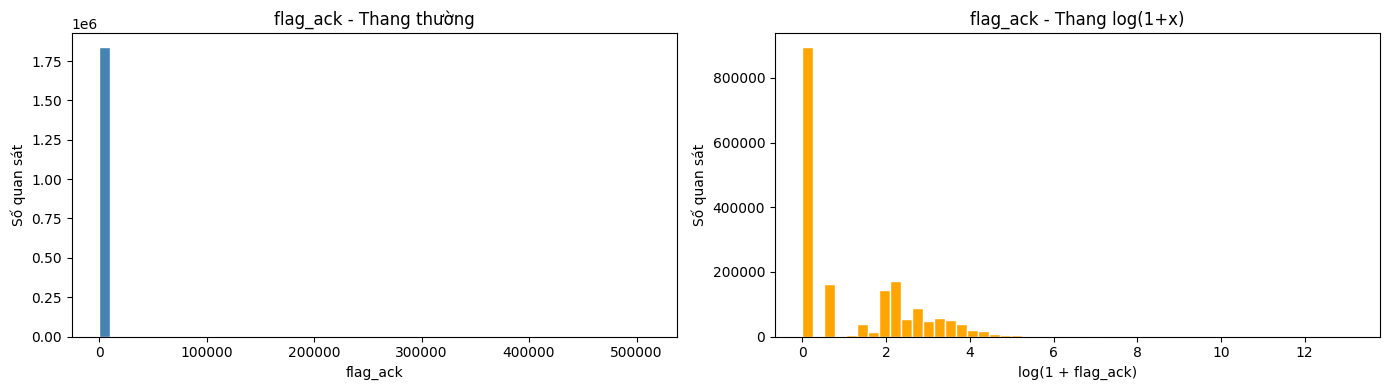

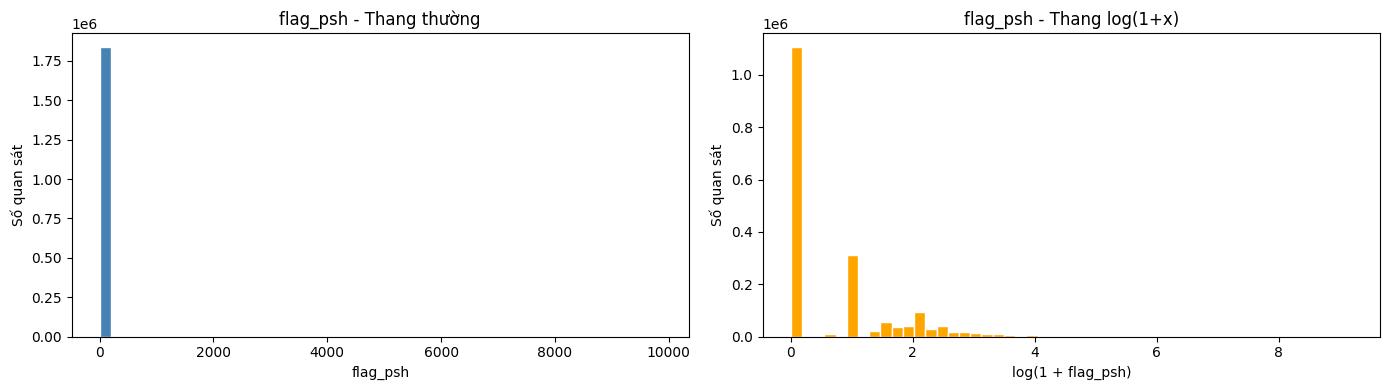

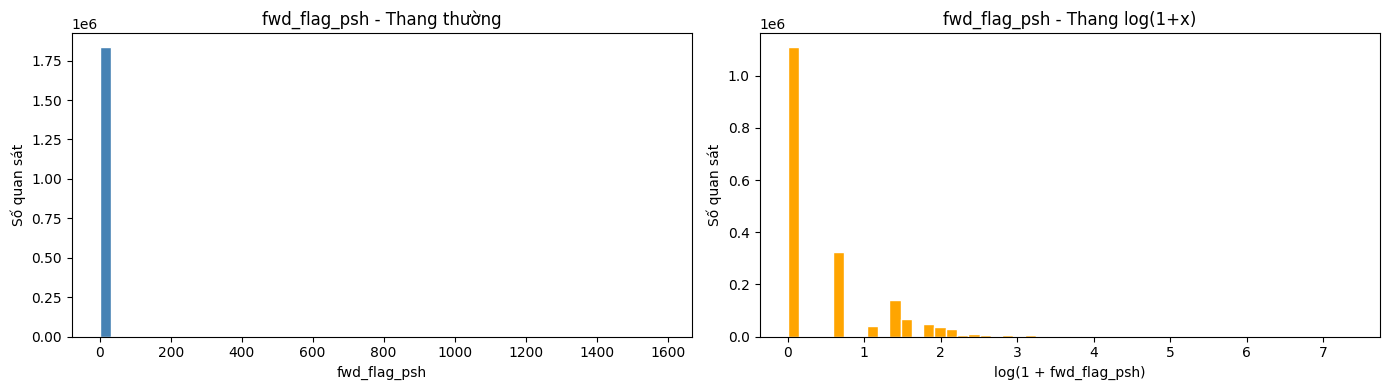

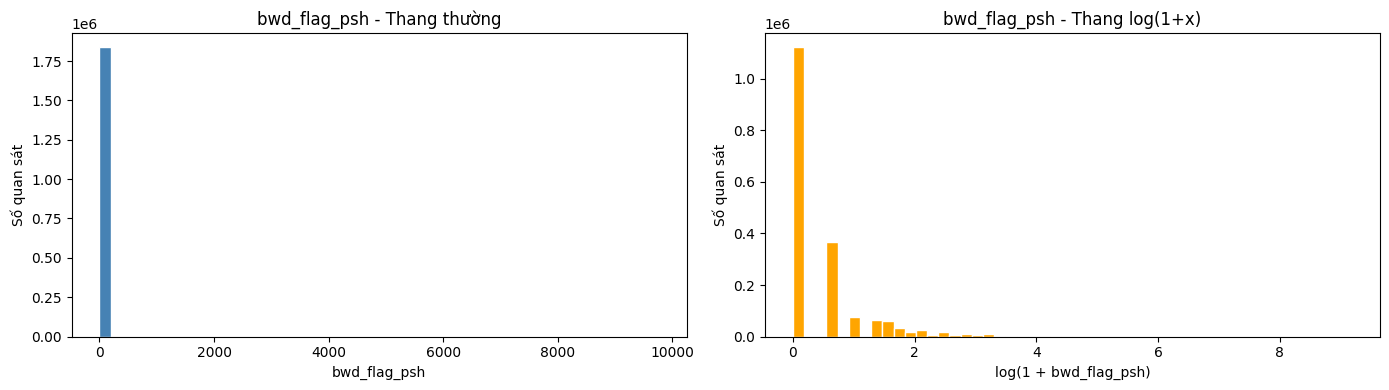

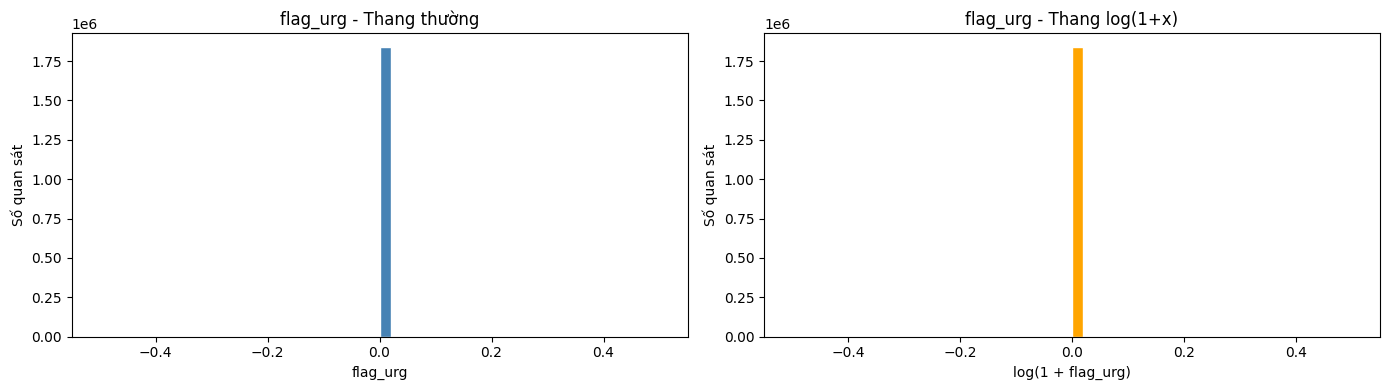

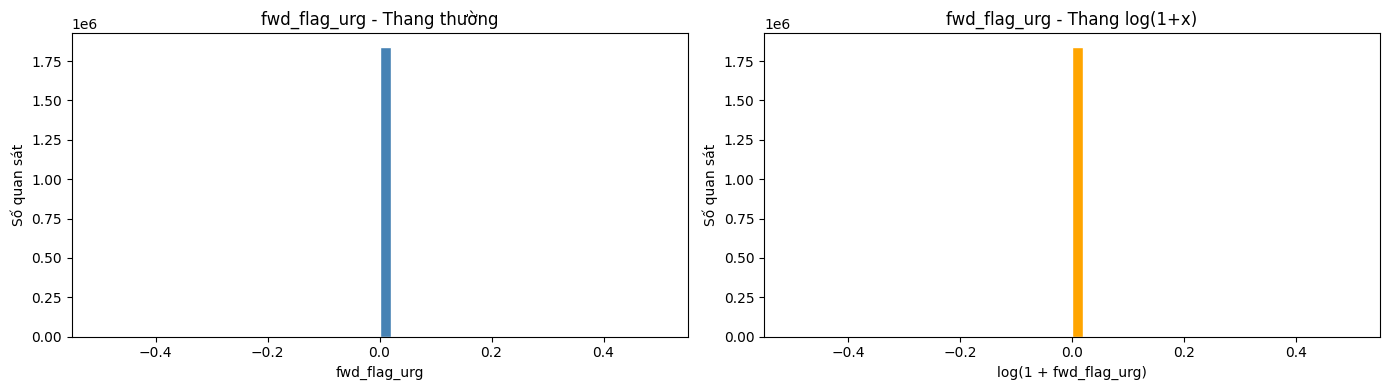

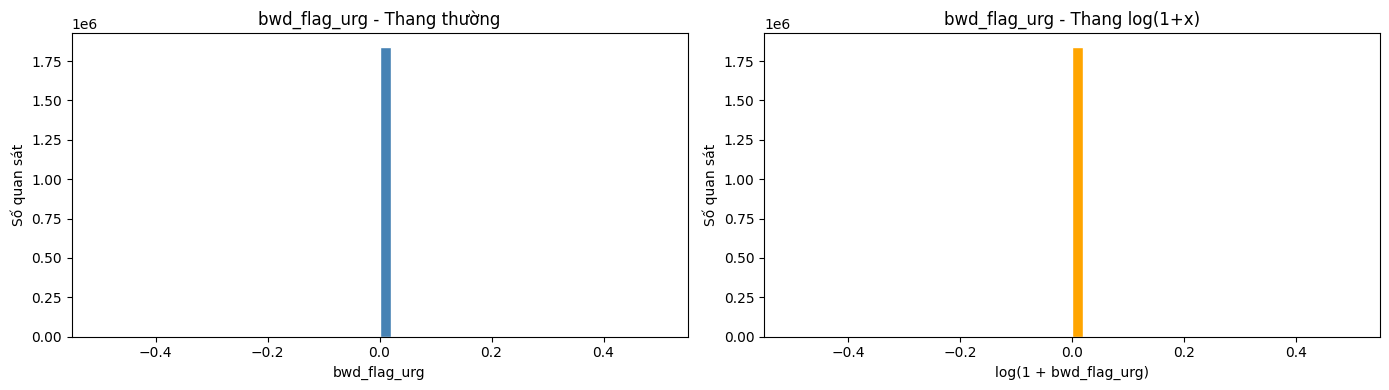

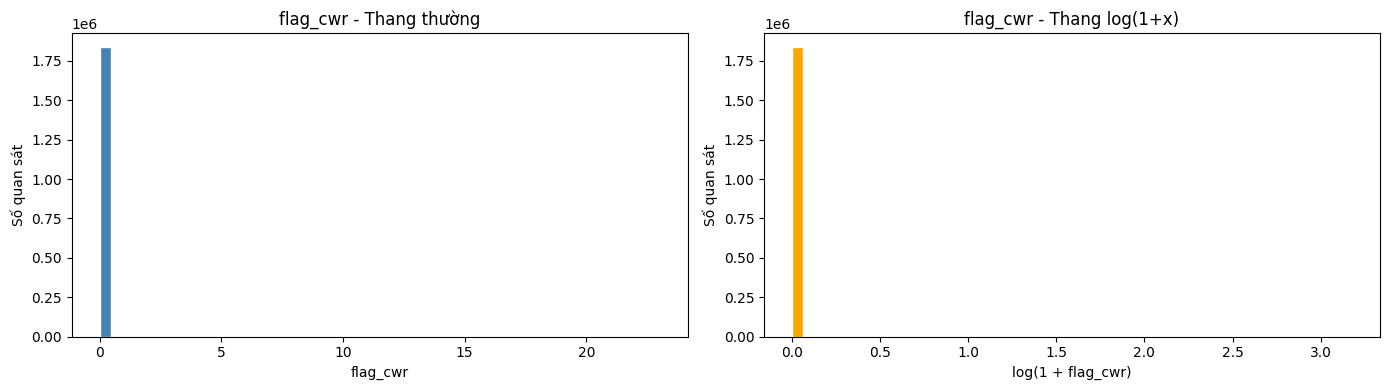

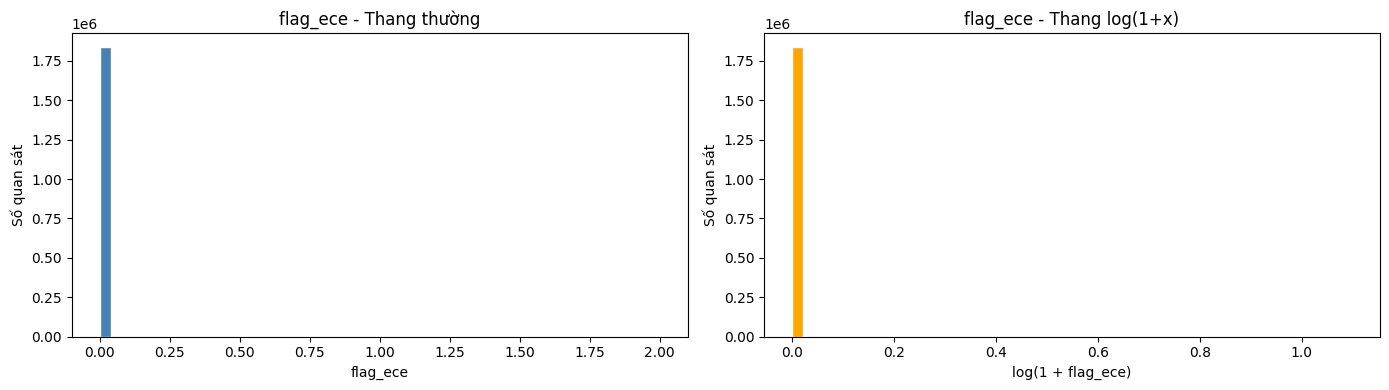

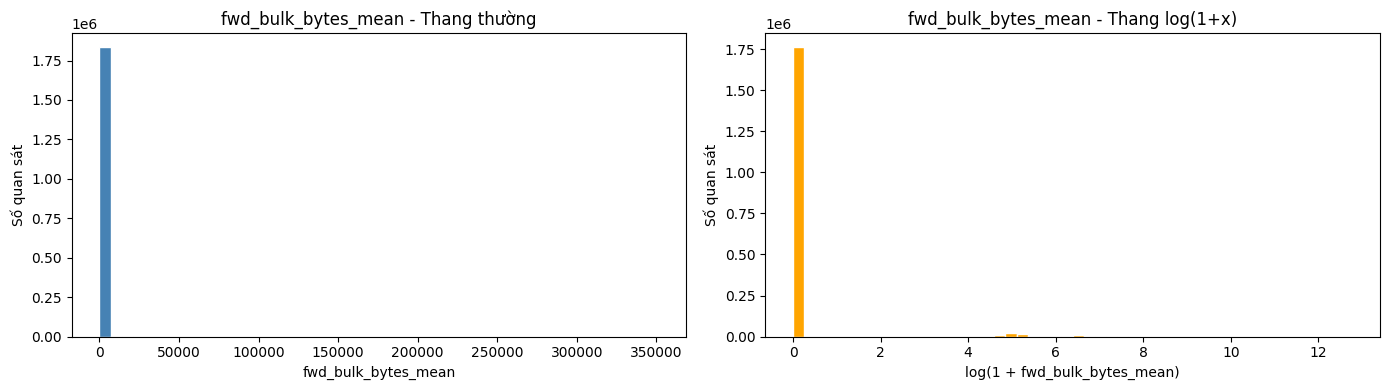

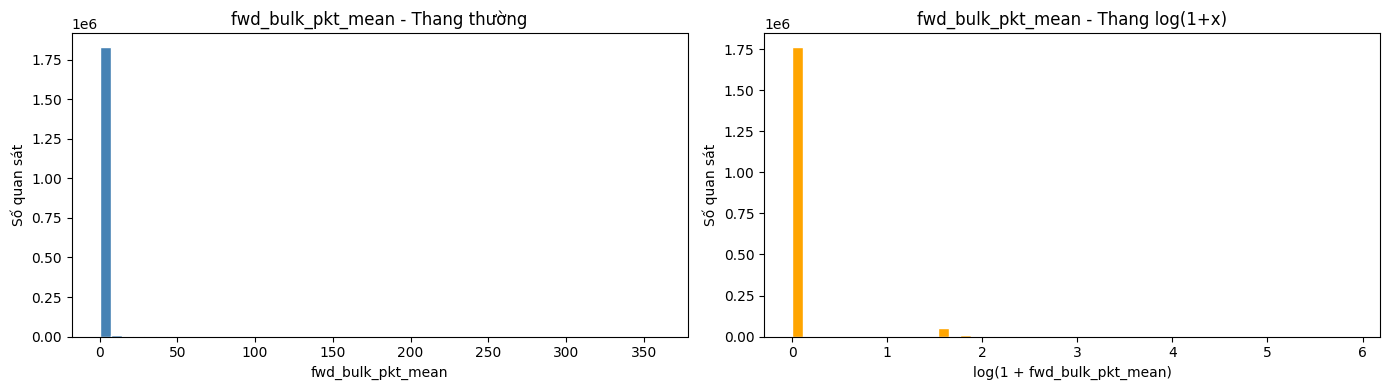

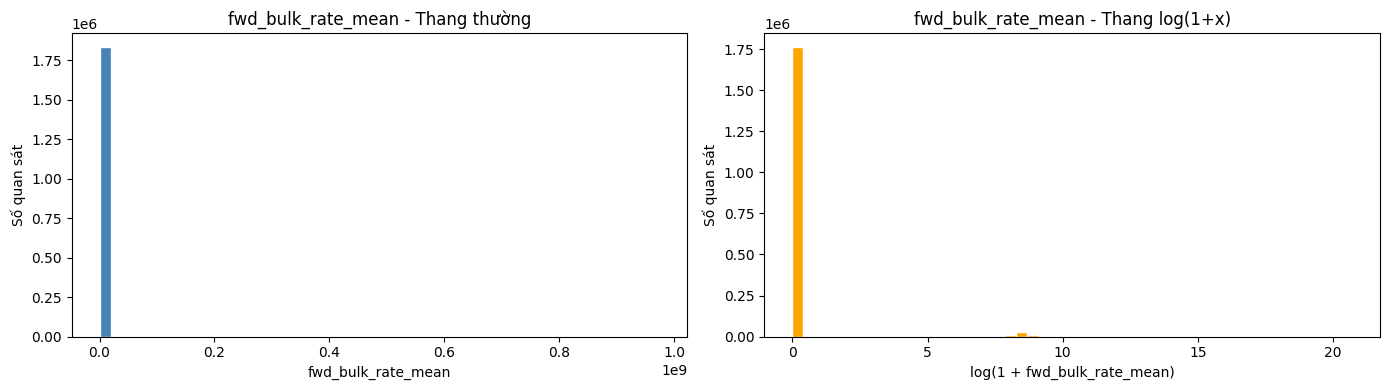

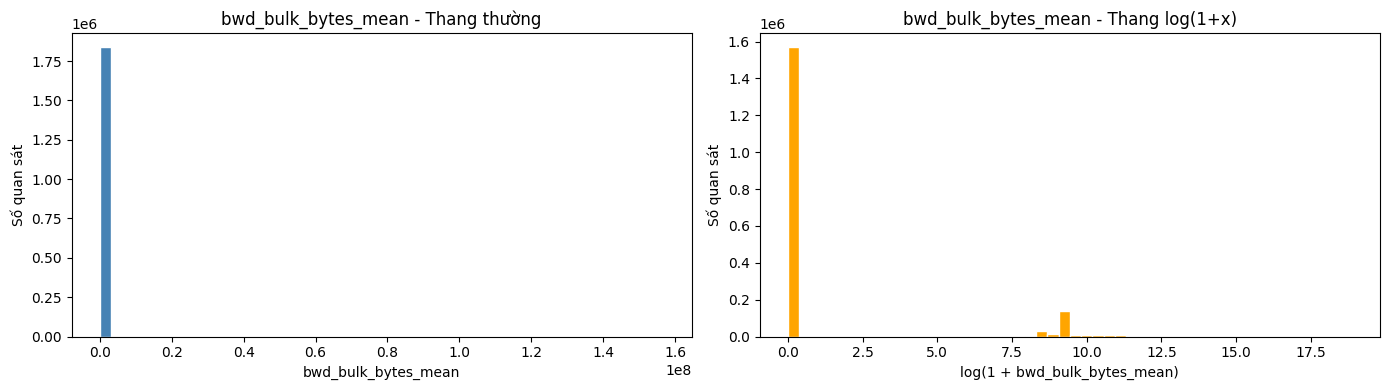

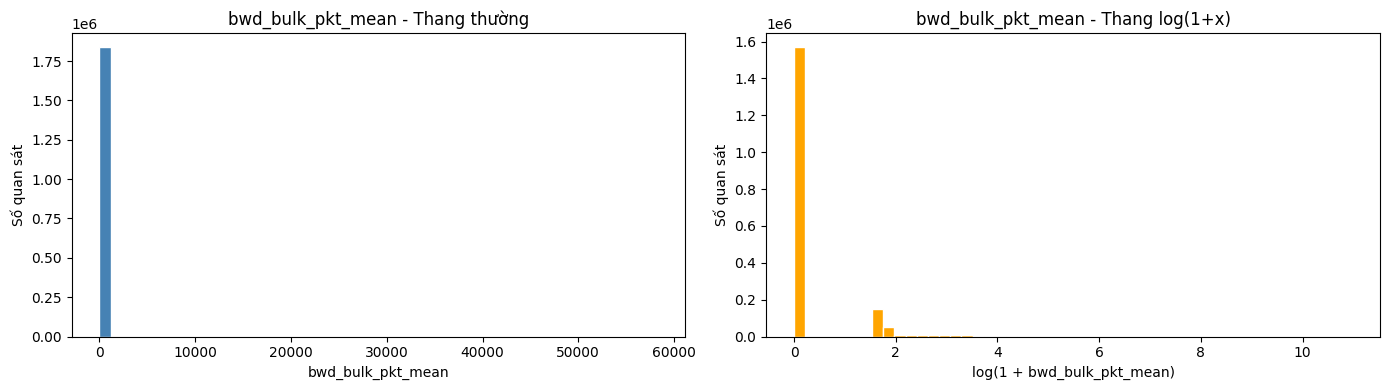

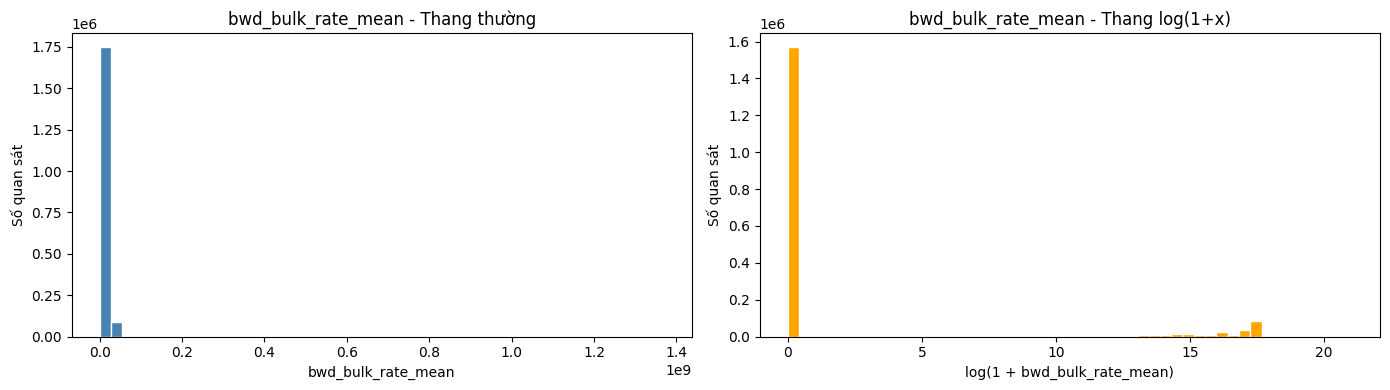

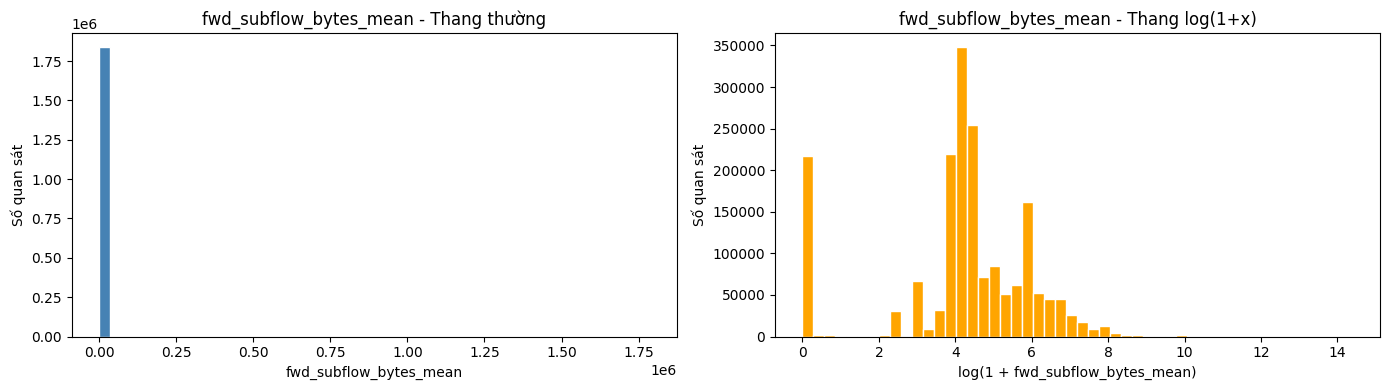

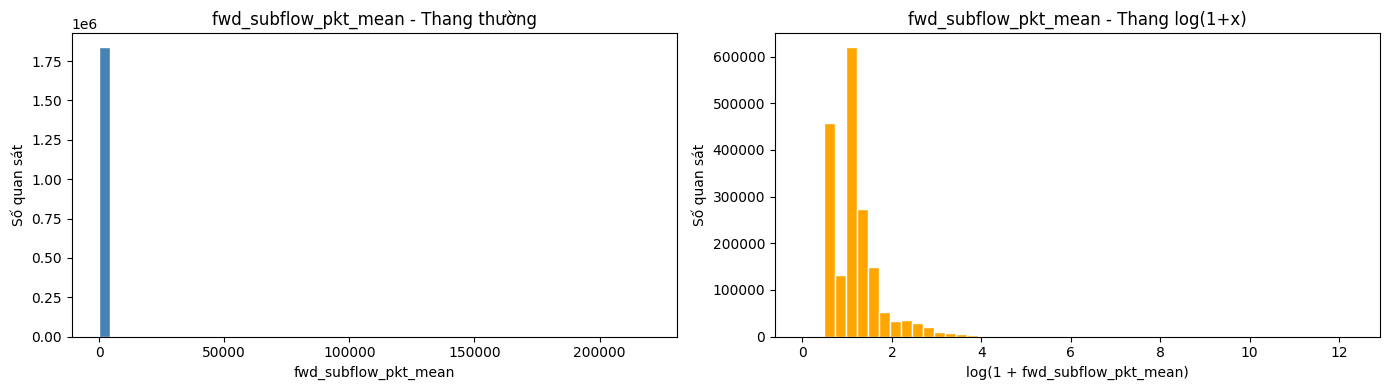

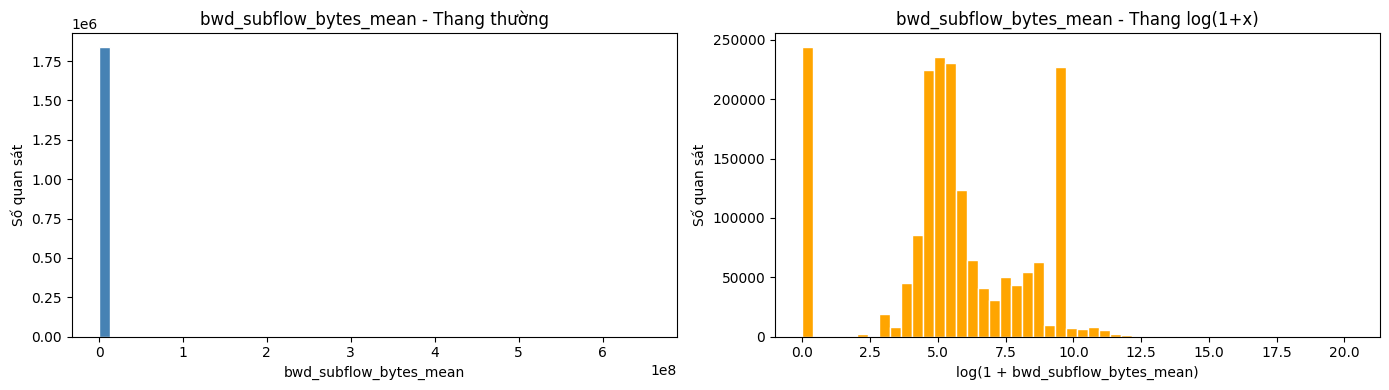

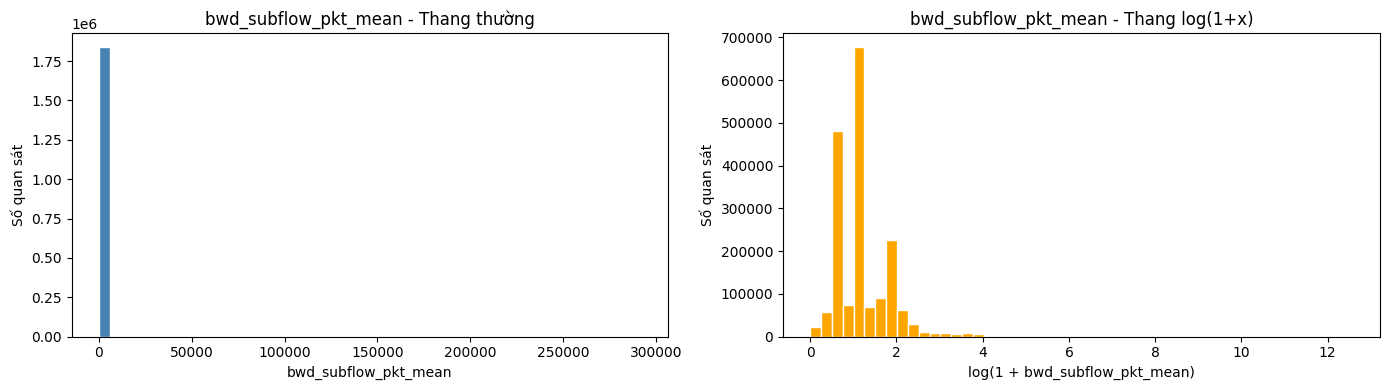

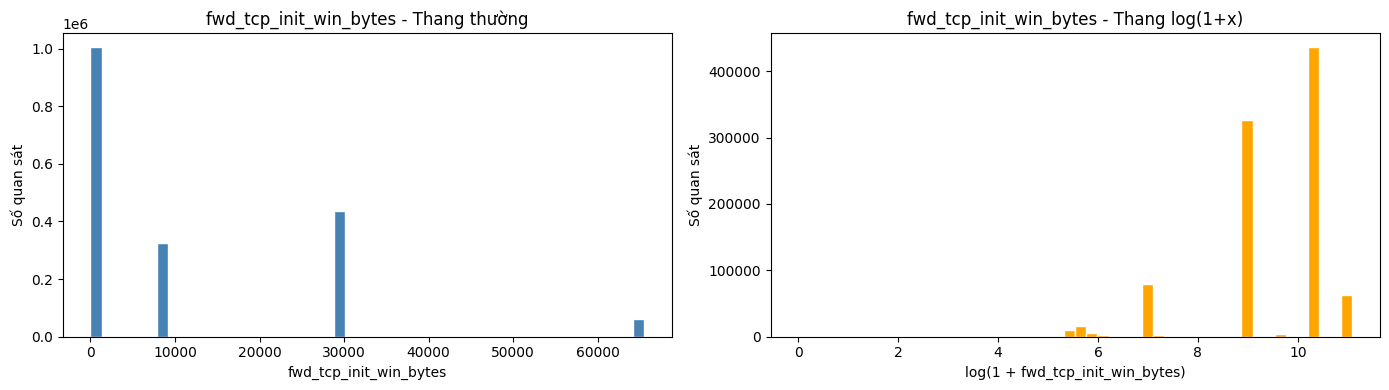

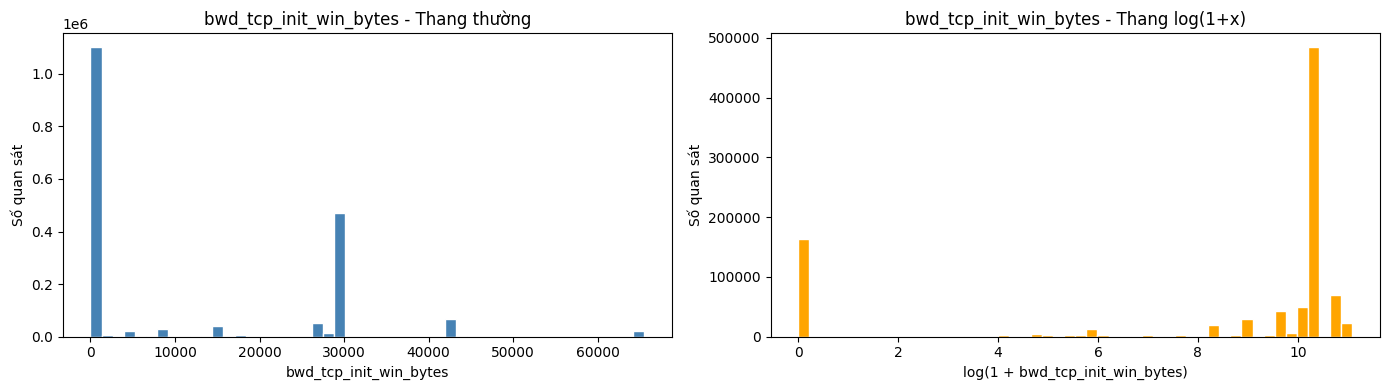

In [44]:
# Vẽ histogram trên thang thường và thang log(1+x)
for col in numeric_cols:
    data = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
    data_log = data[data >= 0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].hist(data, bins=50, color='steelblue', edgecolor='white')
    axes[0].set_title(f'{col} - Thang thường')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Số quan sát')

    axes[1].hist(np.log1p(data_log), bins=50, color='orange', edgecolor='white')
    axes[1].set_title(f'{col} - Thang log(1+x)')
    axes[1].set_xlabel(f'log(1 + {col})')
    axes[1].set_ylabel('Số quan sát')

    plt.tight_layout()
    plt.show()

### Chi tiết từng biến

=====
central tendency of timestamp: {'mean': 1499276514235305.5, 'median': 1499263034295687.0, 'mode': 1499263206097907, 'min': 1499082997567312, 'max': 1499457759567285, 'range': 374761999973}
=====
Dispersion of timestamp: 
 {'range': 374761999973, 'q1': 1499175111853781.0, 'q3': 1499434874491744.0, 'iqr': 259762637963.0, 'var': 1.69686640218863e+22, 'skew': 0.07837808809656877, 'kurtosis': -1.331293900082861}
=====


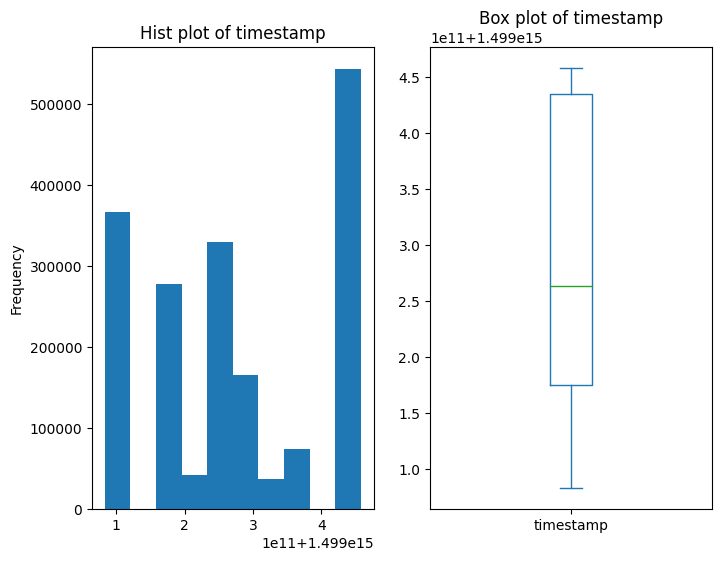

=====
central tendency of flow_duration: {'mean': 11993751.739467472, 'median': 62050.0, 'mode': 43, 'min': 0, 'max': 119999998, 'range': 119999998}
=====
Dispersion of flow_duration: 
 {'range': 119999998, 'q1': 324.0, 'q3': 1459715.5, 'iqr': 1459391.5, 'var': 955742291588323.4, 'skew': 2.676049516132347, 'kurtosis': 5.723619282058412}
=====


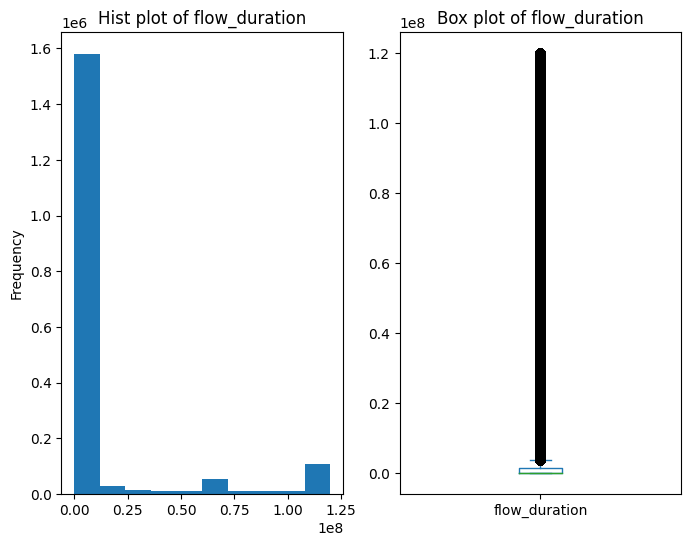

=====
central tendency of down_up_ratio: {'mean': 1.0513746334640903, 'median': 1.0, 'mode': 1.0, 'min': 0.0, 'max': 8.070423, 'range': 8.070423}
=====
Dispersion of down_up_ratio: 
 {'range': 8.070423, 'q1': 1.0, 'q3': 1.0, 'iqr': 0.0, 'var': 0.16663307018657603, 'skew': 1.1333418387955074, 'kurtosis': 4.620579327376066}
=====


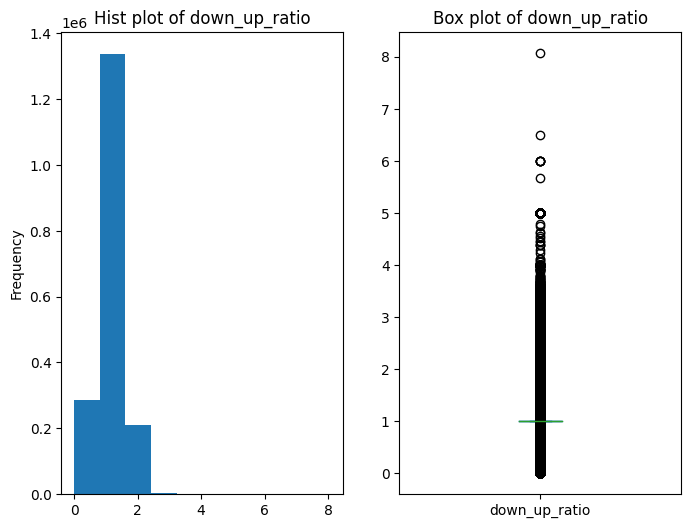

=====
central tendency of pkt_len_max: {'mean': 1388.6792731202972, 'median': 138.0, 'mode': 0.0, 'min': 0.0, 'max': 24820.0, 'range': 24820.0}
=====
Dispersion of pkt_len_max: 
 {'range': 24820.0, 'q1': 68.0, 'q3': 1460.0, 'iqr': 1392.0, 'var': 5644506.594456167, 'skew': 2.1524519386344783, 'kurtosis': 4.423959465336802}
=====


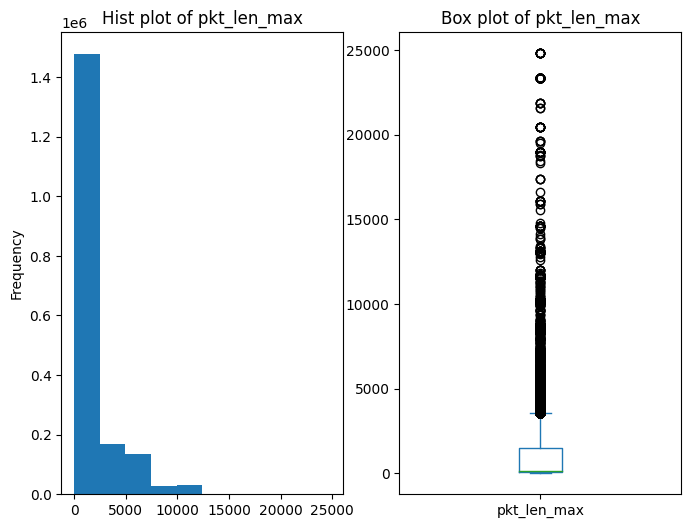

=====
central tendency of pkt_len_min: {'mean': 21.174455700087837, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1448.0, 'range': 1448.0}
=====
Dispersion of pkt_len_min: 
 {'range': 1448.0, 'q1': 0.0, 'q3': 41.0, 'iqr': 41.0, 'var': 699.000741841684, 'skew': 7.311207945730882, 'kurtosis': 297.57771322254115}
=====


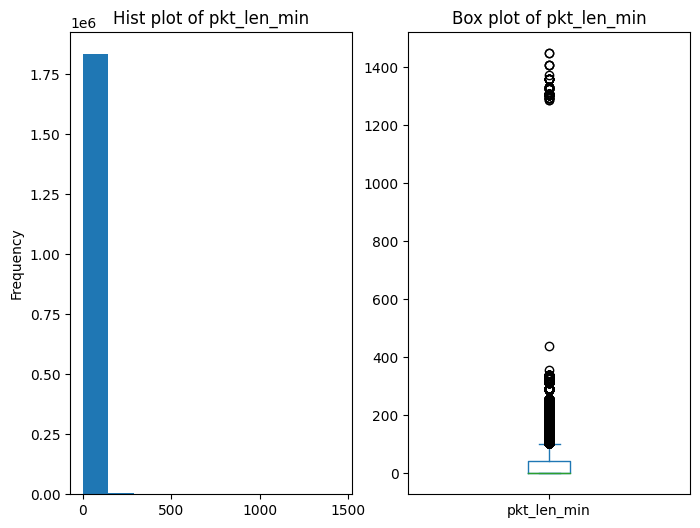

=====
central tendency of pkt_len_mean: {'mean': 305.18858299066113, 'median': 84.5, 'mode': 0.0, 'min': 0.0, 'max': 2391.375, 'range': 2391.375}
=====
Dispersion of pkt_len_mean: 
 {'range': 2391.375, 'q1': 53.0, 'q3': 274.8, 'iqr': 221.8, 'var': 213680.8095659552, 'skew': 1.7620046533599294, 'kurtosis': 1.5633280288211404}
=====


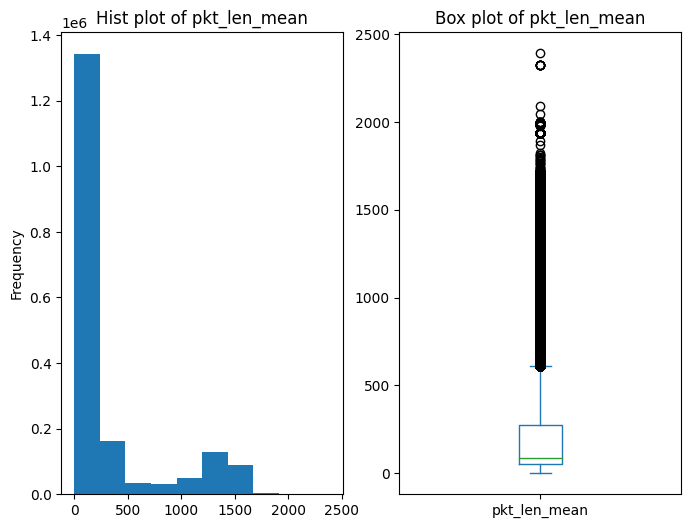

=====
central tendency of pkt_len_var: {'mean': 948497.1007454598, 'median': 3267.0, 'mode': 0.0, 'min': 0.0, 'max': 26865695.0, 'range': 26865695.0}
=====
Dispersion of pkt_len_var: 
 {'range': 26865695.0, 'q1': 341.333333, 'q3': 271906.807692, 'iqr': 271565.474359, 'var': 6901391839495.047, 'skew': 4.073046712921312, 'kurtosis': 19.55748383111322}
=====


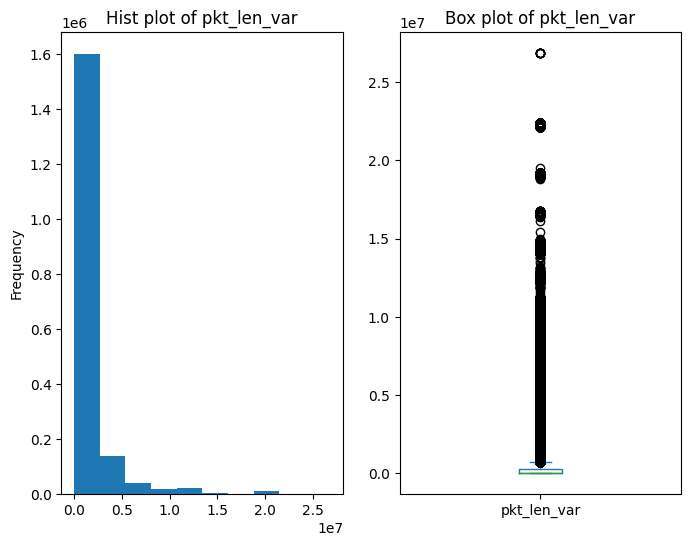

=====
central tendency of pkt_len_std: {'mean': 477.57964098427385, 'median': 57.157677, 'mode': 0.0, 'min': 0.0, 'max': 5183.212807, 'range': 5183.212807}
=====
Dispersion of pkt_len_std: 
 {'range': 5183.212807, 'q1': 18.475209, 'q3': 521.446841, 'iqr': 502.97163199999994, 'var': 720415.1793107875, 'skew': 2.2844609145598196, 'kurtosis': 4.889564326800744}
=====


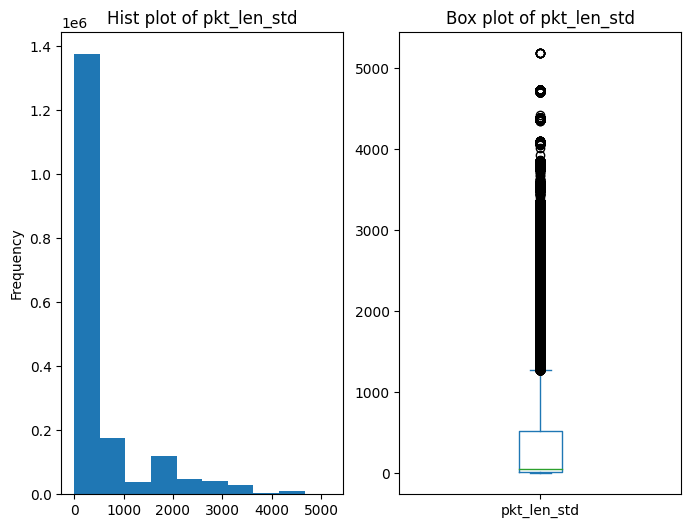

=====
central tendency of bytes_per_s: {'mean': 590284.6995366423, 'median': 5623.0890805, 'mode': 0.0, 'min': 0.0, 'max': 1983000000.0, 'range': 1983000000.0}
=====
Dispersion of bytes_per_s: 
 {'range': 1983000000.0, 'q1': 217.89949125, 'q3': 81667.864092, 'iqr': 81449.96460075, 'var': 73174856341219.14, 'skew': 114.46999585703905, 'kurtosis': 20839.930089047284}
=====


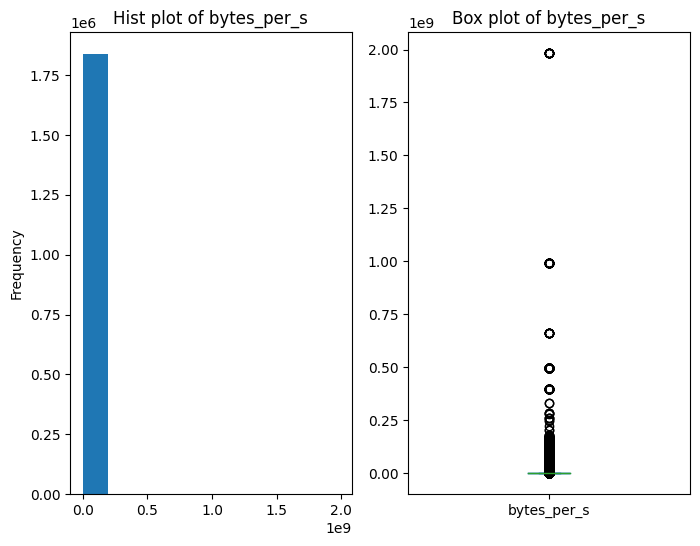

=====
central tendency of pkt_per_s: {'mean': 12335.991702468516, 'median': 65.272021, 'mode': 46511.627907, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of pkt_per_s: 
 {'range': 2000000.0, 'q1': 6.62374725, 'q3': 12383.900929, 'iqr': 12377.27718175, 'var': 4144082804.2462783, 'skew': 17.028622528456335, 'kurtosis': 403.58579436581186}
=====


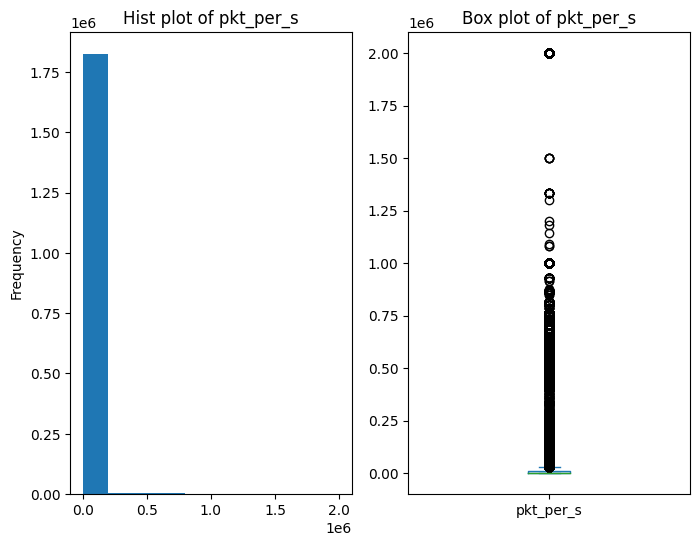

=====
central tendency of fwd_pkt_per_s: {'mean': 7515.6826609485115, 'median': 32.497075, 'mode': 23255.813953, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of fwd_pkt_per_s: 
 {'range': 2000000.0, 'q1': 2.8047315, 'q3': 6116.207951, 'iqr': 6113.4032195, 'var': 2569768831.6396823, 'skew': 16.844664987420604, 'kurtosis': 382.4473769864198}
=====


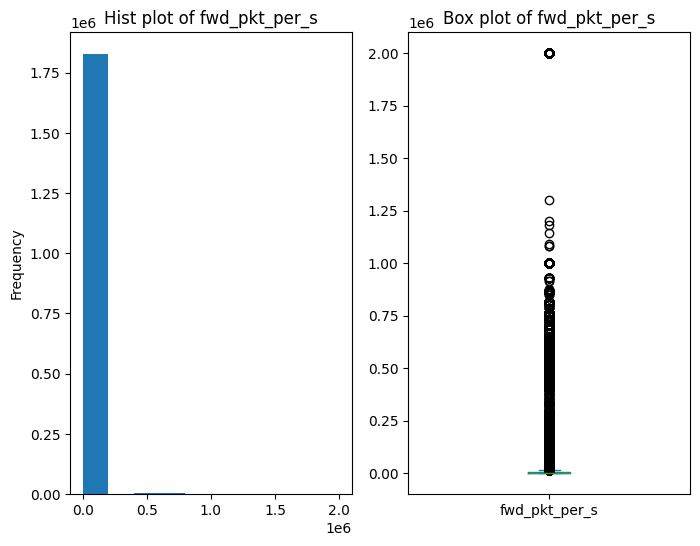

=====
central tendency of bwd_pkt_per_s: {'mean': 4820.309041508117, 'median': 32.926147, 'mode': 0.0, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of bwd_pkt_per_s: 
 {'range': 2000000.0, 'q1': 3.2086759999999996, 'q3': 4618.937644, 'iqr': 4615.728967999999, 'var': 715549473.3065093, 'skew': 32.143906336951446, 'kurtosis': 1456.4756709213634}
=====


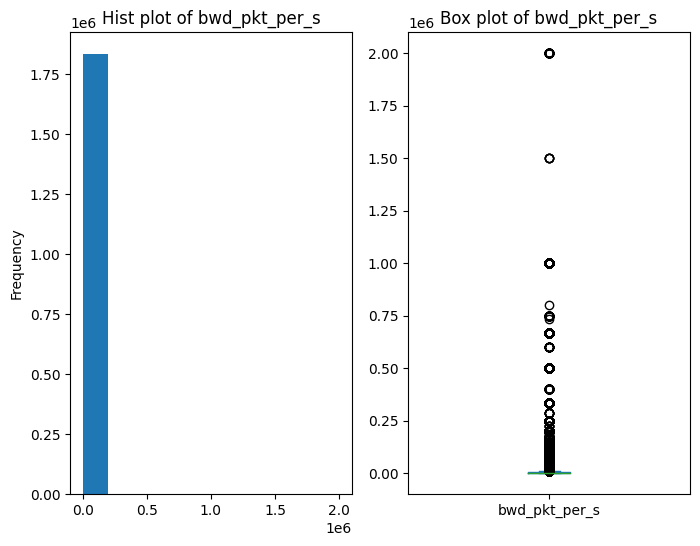

=====
central tendency of fwd_pkt_cnt: {'mean': 12.141304099378612, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 219759, 'range': 219759}
=====
Dispersion of fwd_pkt_cnt: 
 {'range': 219759, 'q1': 2.0, 'q3': 5.0, 'iqr': 3.0, 'var': 864879.3735233056, 'skew': 197.18406111888828, 'kurtosis': 40167.429762908716}
=====


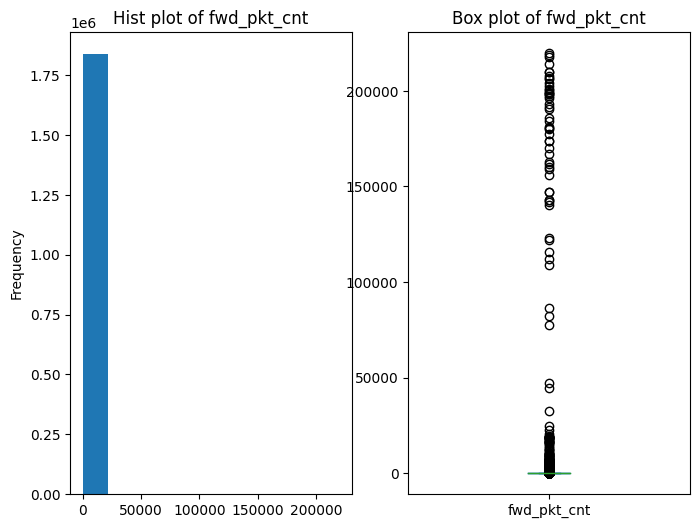

=====
central tendency of fwd_pkt_len_tot: {'mean': 575.187670952567, 'median': 82.0, 'mode': 0, 'min': 0, 'max': 3127392, 'range': 3127392}
=====
Dispersion of fwd_pkt_len_tot: 
 {'range': 3127392, 'q1': 50.0, 'q3': 362.0, 'iqr': 312.0, 'var': 29738698.130864773, 'skew': 231.28283122727902, 'kurtosis': 99307.59152349224}
=====


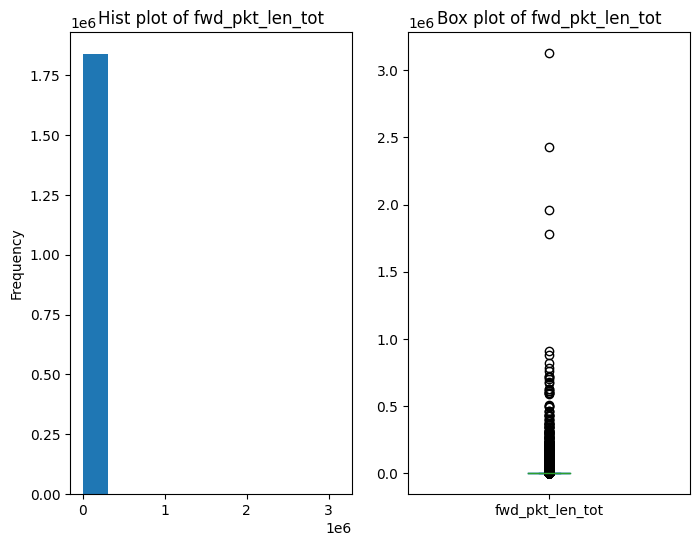

=====
central tendency of fwd_pkt_len_max: {'mean': 215.6581373149794, 'median': 46.0, 'mode': 0.0, 'min': 0.0, 'max': 24820.0, 'range': 24820.0}
=====
Dispersion of fwd_pkt_len_max: 
 {'range': 24820.0, 'q1': 32.0, 'q3': 324.0, 'iqr': 292.0, 'var': 229203.06668769167, 'skew': 11.467707345351558, 'kurtosis': 343.6213302047256}
=====


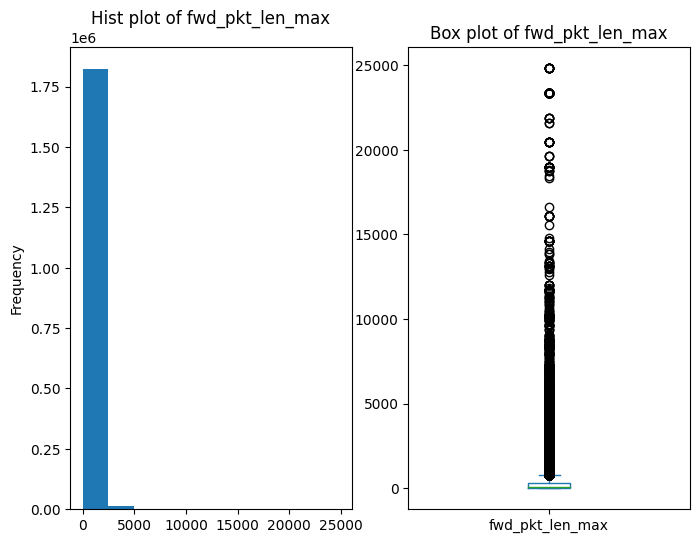

=====
central tendency of fwd_pkt_len_min: {'mean': 21.435128092656427, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 2293.0, 'range': 2293.0}
=====
Dispersion of fwd_pkt_len_min: 
 {'range': 2293.0, 'q1': 0.0, 'q3': 41.0, 'iqr': 41.0, 'var': 1272.714372670487, 'skew': 22.144180055924405, 'kurtosis': 873.8026047729203}
=====


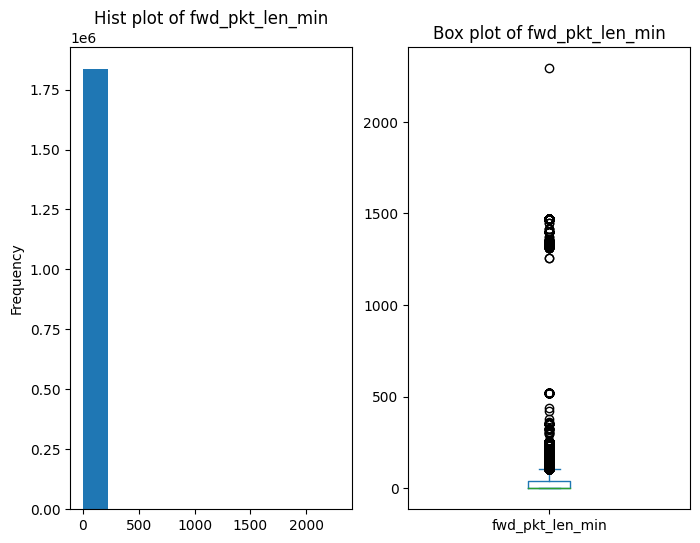

=====
central tendency of fwd_pkt_len_mean: {'mean': 60.66870248781984, 'median': 43.0, 'mode': 0.0, 'min': 0.0, 'max': 5940.514286, 'range': 5940.514286}
=====
Dispersion of fwd_pkt_len_mean: 
 {'range': 5940.514286, 'q1': 30.0, 'q3': 63.0, 'iqr': 33.0, 'var': 9752.598524789188, 'skew': 11.58498665433857, 'kurtosis': 257.6521128723365}
=====


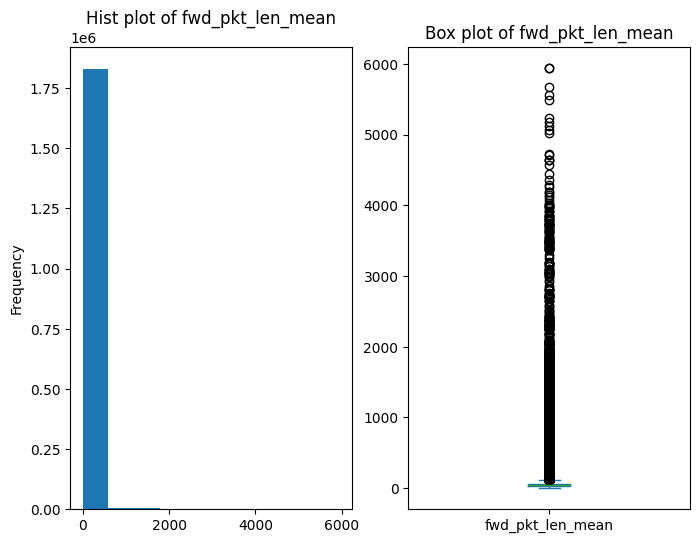

=====
central tendency of fwd_pkt_len_std: {'mean': 71.15021605705586, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 7127.074364, 'range': 7127.074364}
=====
Dispersion of fwd_pkt_len_std: 
 {'range': 7127.074364, 'q1': 0.0, 'q3': 108.75, 'iqr': 108.75, 'var': 23996.08135714062, 'skew': 6.308274550192978, 'kurtosis': 86.96053353916034}
=====


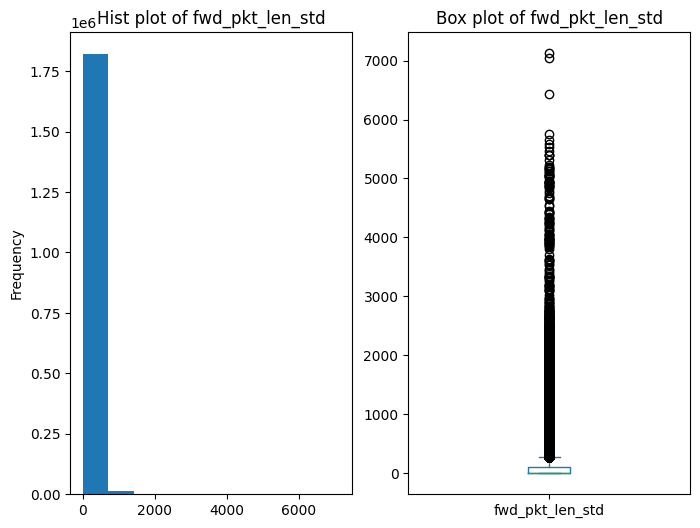

=====
central tendency of fwd_pkt_hdr_len_tot: {'mean': 277.03681636660286, 'median': 32.0, 'mode': 16, 'min': 0, 'max': 4644908, 'range': 4644908}
=====
Dispersion of fwd_pkt_hdr_len_tot: 
 {'range': 4644908, 'q1': 16.0, 'q3': 132.0, 'iqr': 116.0, 'var': 377718318.2977403, 'skew': 196.70047404650057, 'kurtosis': 40094.65799959114}
=====


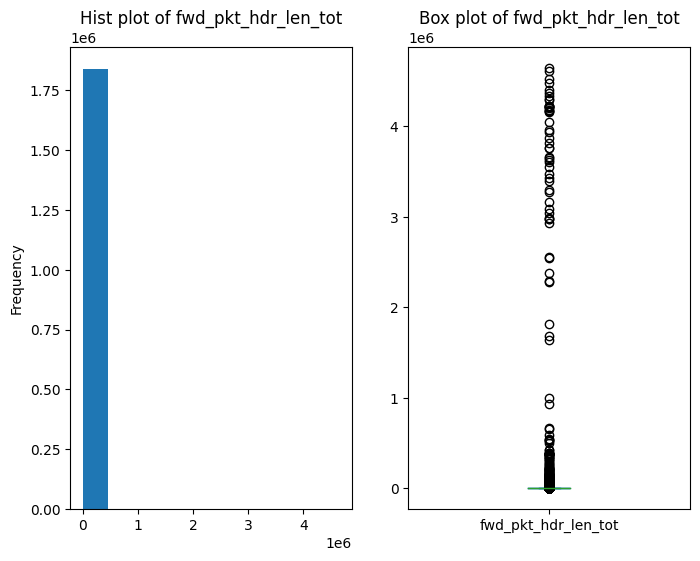

=====
central tendency of fwd_pkt_hdr_len_min: {'mean': 17.933927547132026, 'median': 20.0, 'mode': 8, 'min': 0, 'max': 44, 'range': 44}
=====
Dispersion of fwd_pkt_hdr_len_min: 
 {'range': 44, 'q1': 8.0, 'q3': 32.0, 'iqr': 24.0, 'var': 116.61840551339246, 'skew': 0.5158729451617842, 'kurtosis': -1.1913438015514348}
=====


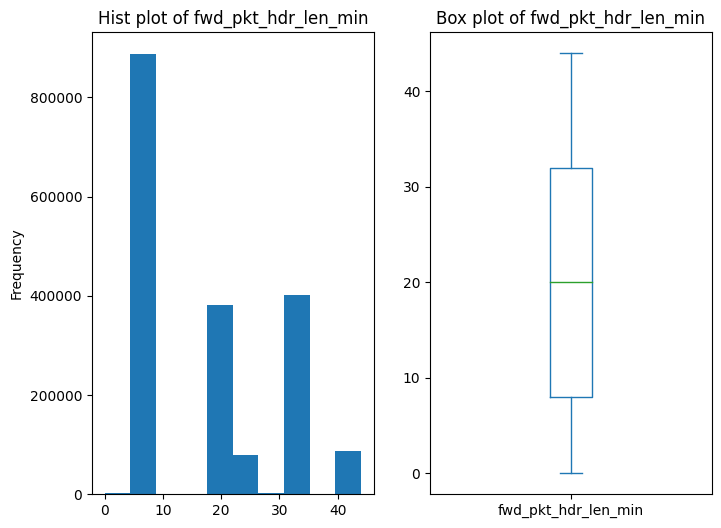

=====
central tendency of fwd_non_empty_pkt_cnt: {'mean': 2.7518163285075685, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 2388, 'range': 2388}
=====
Dispersion of fwd_non_empty_pkt_cnt: 
 {'range': 2388, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 41.96046473164504, 'skew': 89.03110479548236, 'kurtosis': 21033.39326485712}
=====


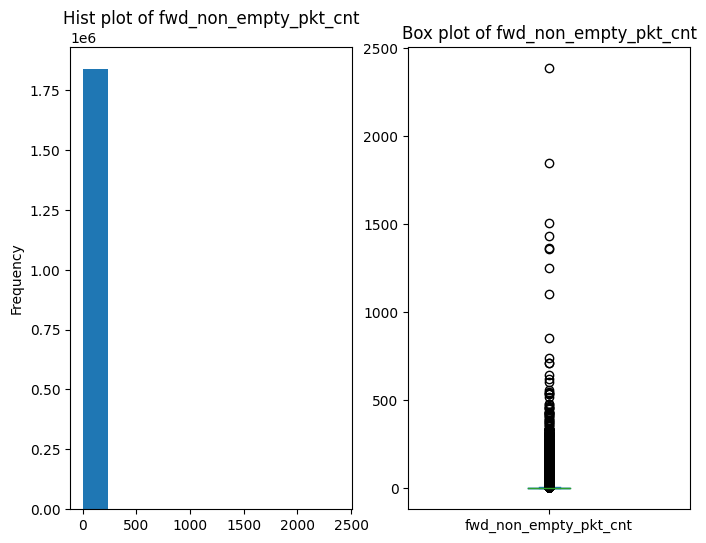

=====
central tendency of bwd_pkt_cnt: {'mean': 14.674267400563156, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 291922, 'range': 291922}
=====
Dispersion of bwd_pkt_cnt: 
 {'range': 291922, 'q1': 1.0, 'q3': 6.0, 'iqr': 5.0, 'var': 1530484.5851543096, 'skew': 197.48605271775045, 'kurtosis': 40359.24538658912}
=====


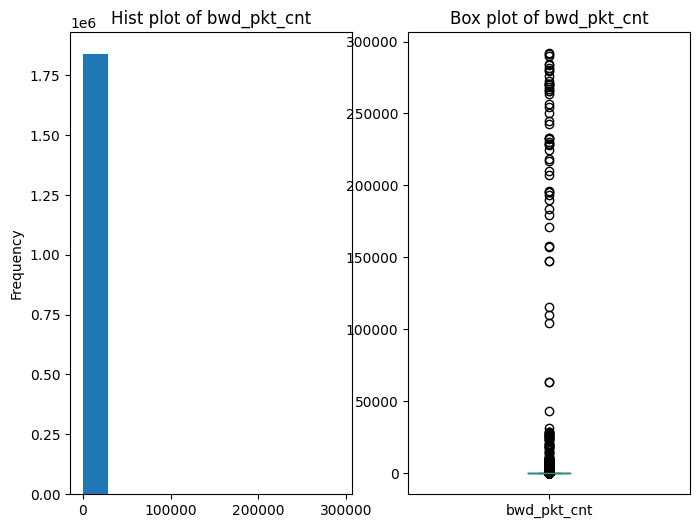

=====
central tendency of bwd_pkt_len_tot: {'mean': 23963.518453897635, 'median': 234.0, 'mode': 11595, 'min': 0, 'max': 655452323, 'range': 655452323}
=====
Dispersion of bwd_pkt_len_tot: 
 {'range': 655452323, 'q1': 110.0, 'q3': 4406.0, 'iqr': 4296.0, 'var': 7883885092088.172, 'skew': 197.05977837269836, 'kurtosis': 40045.13442191729}
=====


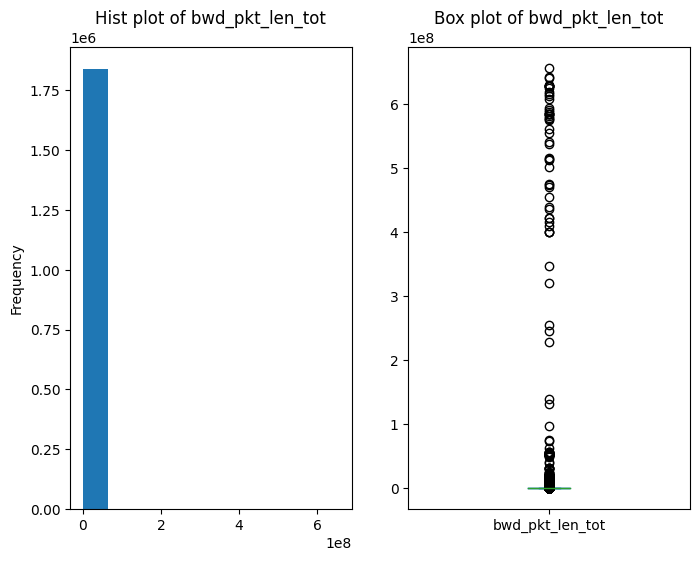

=====
central tendency of bwd_pkt_len_max: {'mean': 1351.6539892832536, 'median': 134.0, 'mode': 0.0, 'min': 0.0, 'max': 19530.0, 'range': 19530.0}
=====
Dispersion of bwd_pkt_len_max: 
 {'range': 19530.0, 'q1': 67.0, 'q3': 1460.0, 'iqr': 1393.0, 'var': 5591111.522248175, 'skew': 2.1673025942036115, 'kurtosis': 4.271035234429739}
=====


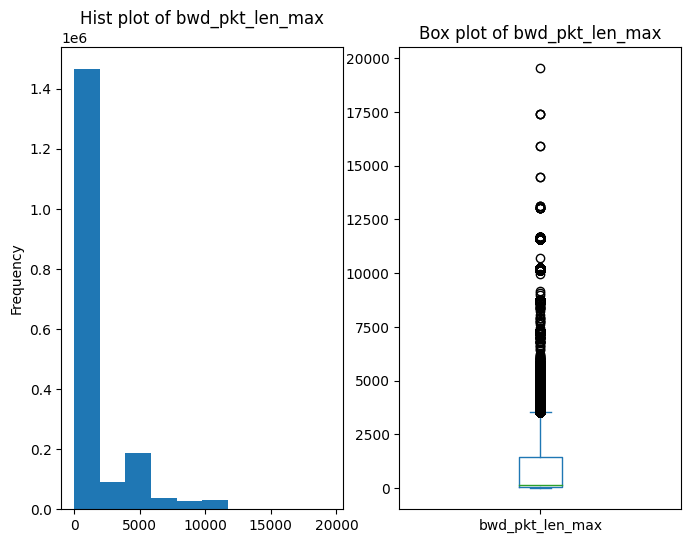

=====
central tendency of bwd_pkt_len_min: {'mean': 0.15506792388345456, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1983.0, 'range': 1983.0}
=====
Dispersion of bwd_pkt_len_min: 
 {'range': 1983.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 36.32794198356374, 'skew': 87.62961213625884, 'kurtosis': 16790.934705899977}
=====


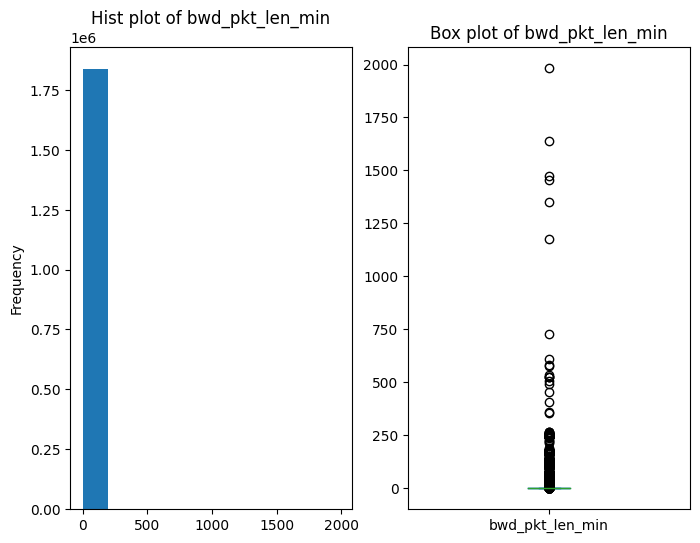

=====
central tendency of bwd_pkt_len_mean: {'mean': 475.90304423317355, 'median': 122.0, 'mode': 0.0, 'min': 0.0, 'max': 4370.686524, 'range': 4370.686524}
=====
Dispersion of bwd_pkt_len_mean: 
 {'range': 4370.686524, 'q1': 61.0, 'q3': 459.893275, 'iqr': 398.893275, 'var': 544347.0700260648, 'skew': 1.794540606237313, 'kurtosis': 1.9164072163178822}
=====


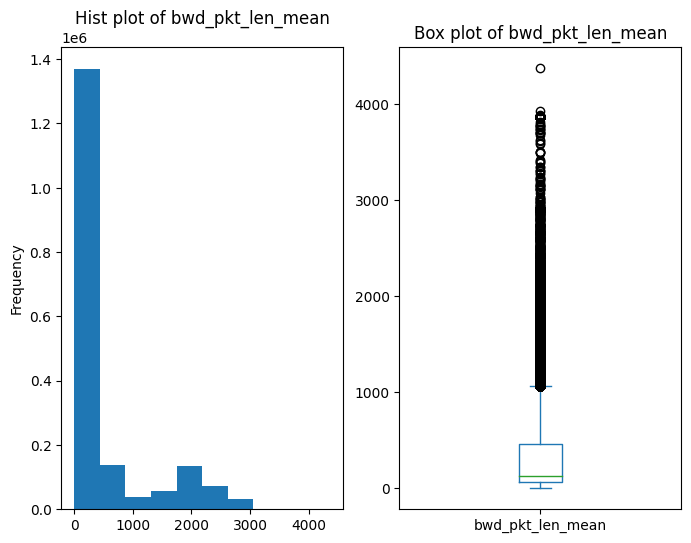

=====
central tendency of bwd_pkt_len_std: {'mean': 532.2374566290111, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 6715.738331, 'range': 6715.738331}
=====
Dispersion of bwd_pkt_len_std: 
 {'range': 6715.738331, 'q1': 0.0, 'q3': 635.9283745, 'iqr': 635.9283745, 'var': 1090600.404727226, 'skew': 2.5461353481502225, 'kurtosis': 6.773523627604882}
=====


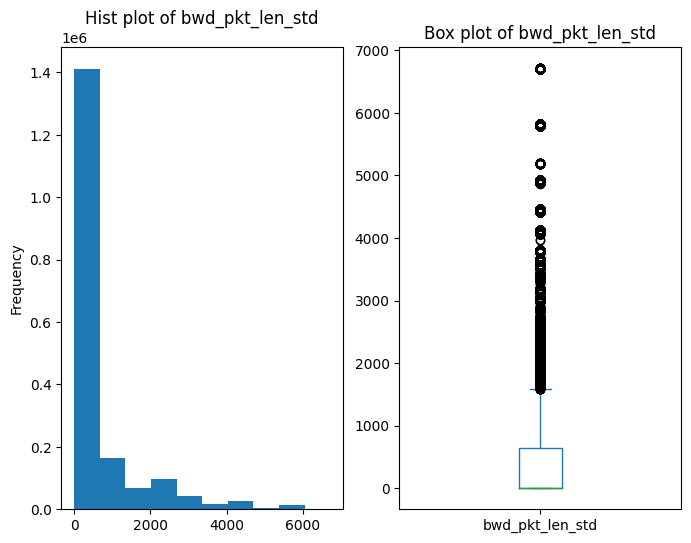

=====
central tendency of bwd_pkt_hdr_len_tot: {'mean': 328.04939107416715, 'median': 20.0, 'mode': 16, 'min': 0, 'max': 5838440, 'range': 5838440}
=====
Dispersion of bwd_pkt_hdr_len_tot: 
 {'range': 5838440, 'q1': 16.0, 'q3': 168.0, 'iqr': 152.0, 'var': 613767074.5162479, 'skew': 196.7949893953519, 'kurtosis': 40153.908955837134}
=====


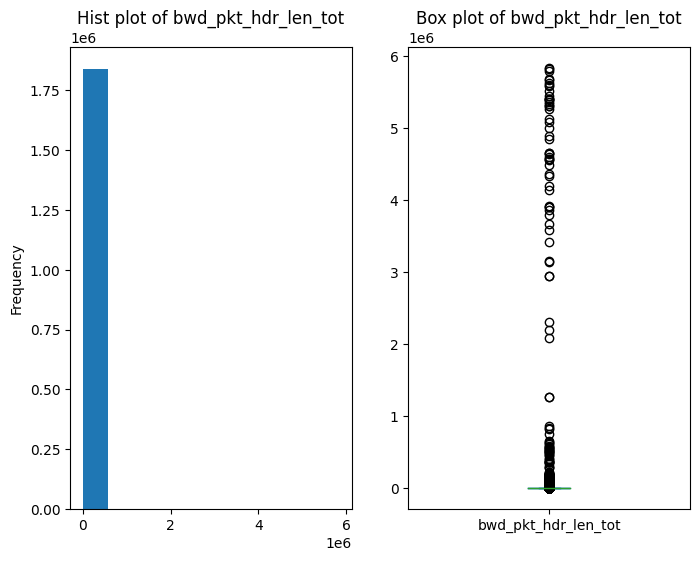

=====
central tendency of bwd_pkt_hdr_len_min: {'mean': 16.843333707029885, 'median': 20.0, 'mode': 8, 'min': 0, 'max': 44, 'range': 44}
=====
Dispersion of bwd_pkt_hdr_len_min: 
 {'range': 44, 'q1': 8.0, 'q3': 20.0, 'iqr': 12.0, 'var': 98.30644068946921, 'skew': 0.5055976931972149, 'kurtosis': -1.1465587704611089}
=====


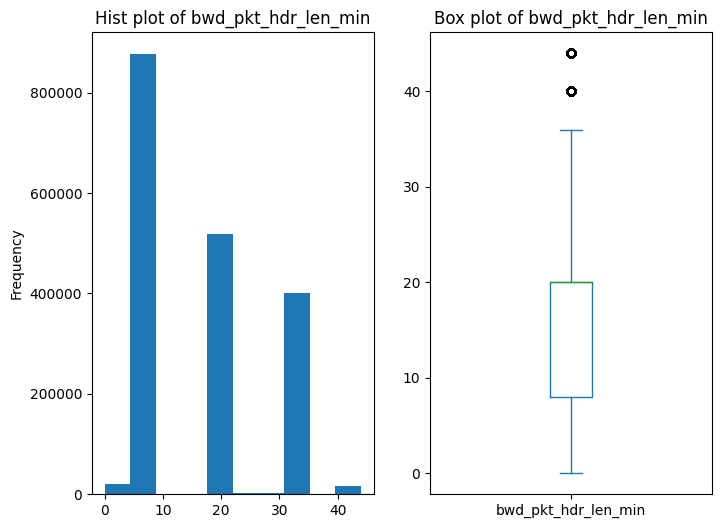

=====
central tendency of bwd_non_empty_pkt_cnt: {'mean': 12.681925640191173, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 291805, 'range': 291805}
=====
Dispersion of bwd_non_empty_pkt_cnt: 
 {'range': 291805, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 1529175.6202502323, 'skew': 197.50802870058877, 'kurtosis': 40364.7410962198}
=====


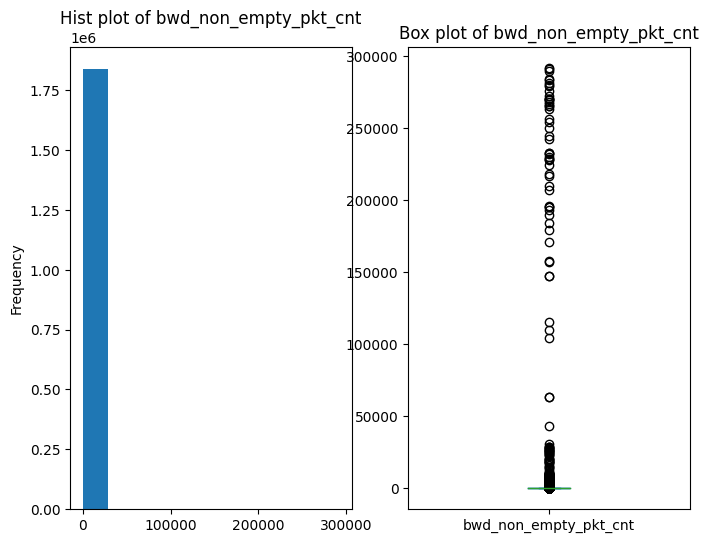

=====
central tendency of iat_max: {'mean': 4592724.5585997915, 'median': 53271.5, 'mode': 43.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of iat_max: 
 {'range': 119999735.0, 'q1': 290.0, 'q3': 1213640.5, 'iqr': 1213350.5, 'var': 203917404031448.28, 'skew': 4.657750589832414, 'kurtosis': 23.78315120577175}
=====


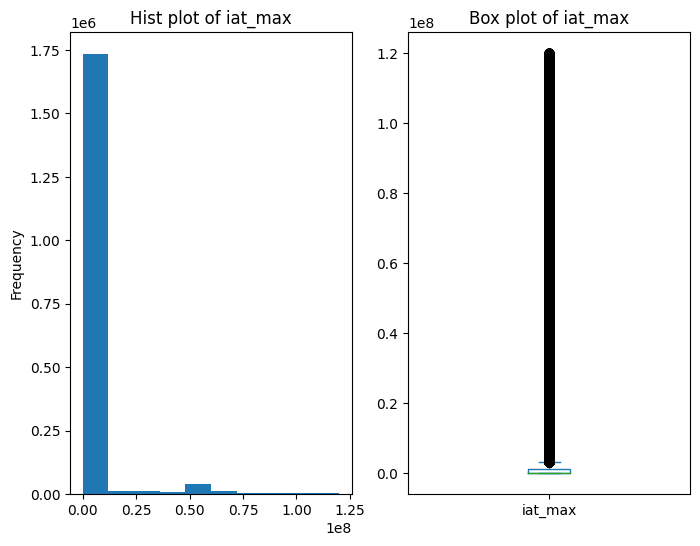

=====
central tendency of iat_min: {'mean': 18202.355479026373, 'median': 4.0, 'mode': 3.0, 'min': -14.0, 'max': 69000029.0, 'range': 69000043.0}
=====
Dispersion of iat_min: 
 {'range': 69000043.0, 'q1': 3.0, 'q3': 50.0, 'iqr': 47.0, 'var': 62781348213.70424, 'skew': 129.05727360778639, 'kurtosis': 27277.450667939265}
=====


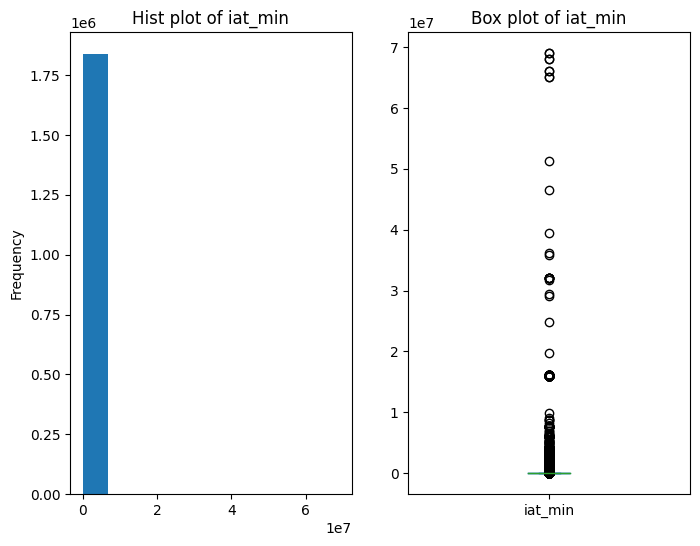

=====
central tendency of iat_mean: {'mean': 879279.8647131164, 'median': 20391.666667, 'mode': 43.0, 'min': 0.0, 'max': 69000029.0, 'range': 69000029.0}
=====
Dispersion of iat_mean: 
 {'range': 69000029.0, 'q1': 107.0, 'q3': 187650.1857145, 'iqr': 187543.1857145, 'var': 11868367902807.402, 'skew': 7.239257838965045, 'kurtosis': 60.926482679253375}
=====


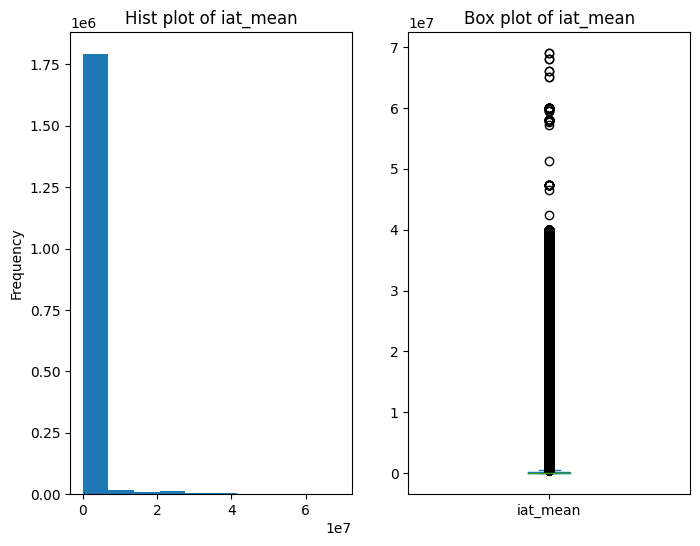

=====
central tendency of iat_std: {'mean': 1721530.78238147, 'median': 17740.544665, 'mode': 0.0, 'min': 0.0, 'max': 84819214.856571, 'range': 84819214.856571}
=====
Dispersion of iat_std: 
 {'range': 84819214.856571, 'q1': 56.589163, 'q3': 419117.63525225, 'iqr': 419061.04608925, 'var': 38680529494720.36, 'skew': 6.518426199003155, 'kurtosis': 49.67452264732382}
=====


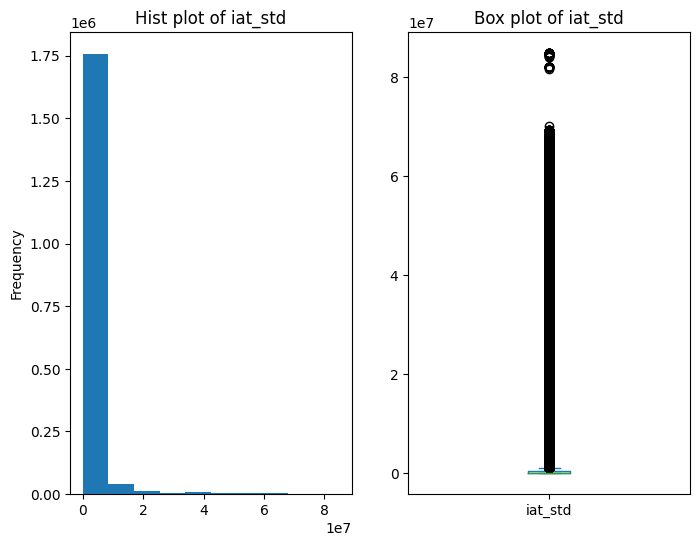

=====
central tendency of fwd_iat_tot: {'mean': 11630502.575558722, 'median': 49.0, 'mode': 0, 'min': 0, 'max': 119999998, 'range': 119999998}
=====
Dispersion of fwd_iat_tot: 
 {'range': 119999998, 'q1': 1.0, 'q3': 594063.75, 'iqr': 594062.75, 'var': 947903453487926.1, 'skew': 2.7133227793324317, 'kurtosis': 5.91497443881138}
=====


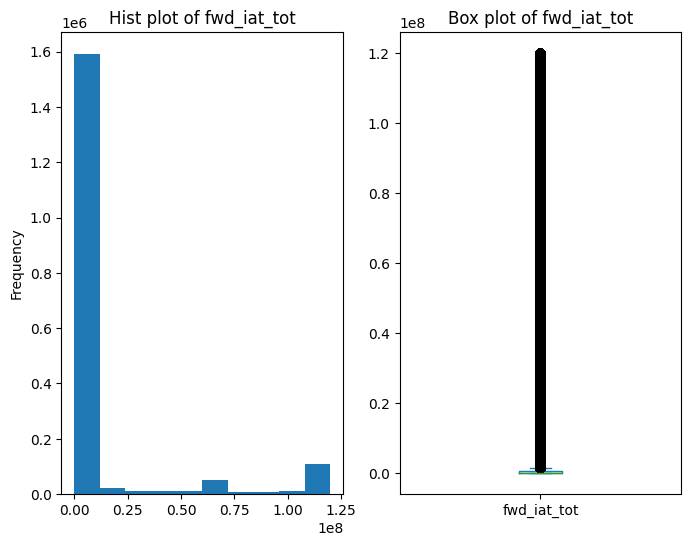

=====
central tendency of fwd_iat_max: {'mean': 4417167.388732396, 'median': 49.0, 'mode': 0.0, 'min': 0.0, 'max': 119999869.0, 'range': 119999869.0}
=====
Dispersion of fwd_iat_max: 
 {'range': 119999869.0, 'q1': 1.0, 'q3': 263761.5, 'iqr': 263760.5, 'var': 203349259047429.7, 'skew': 4.68940436932519, 'kurtosis': 24.062782380458412}
=====


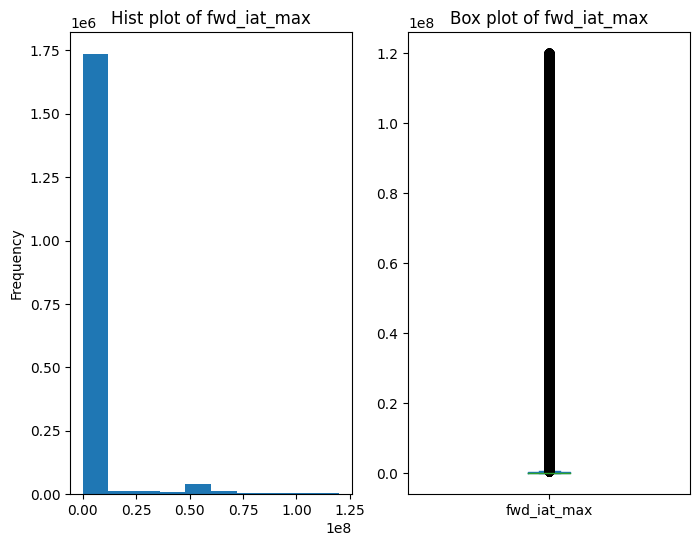

=====
central tendency of fwd_iat_min: {'mean': 1214749.340798194, 'median': 3.0, 'mode': 0.0, 'min': 0.0, 'max': 119999570.0, 'range': 119999570.0}
=====
Dispersion of fwd_iat_min: 
 {'range': 119999570.0, 'q1': 1.0, 'q3': 49.0, 'iqr': 48.0, 'var': 90007797267299.8, 'skew': 8.911015696355364, 'kurtosis': 83.81610193522519}
=====


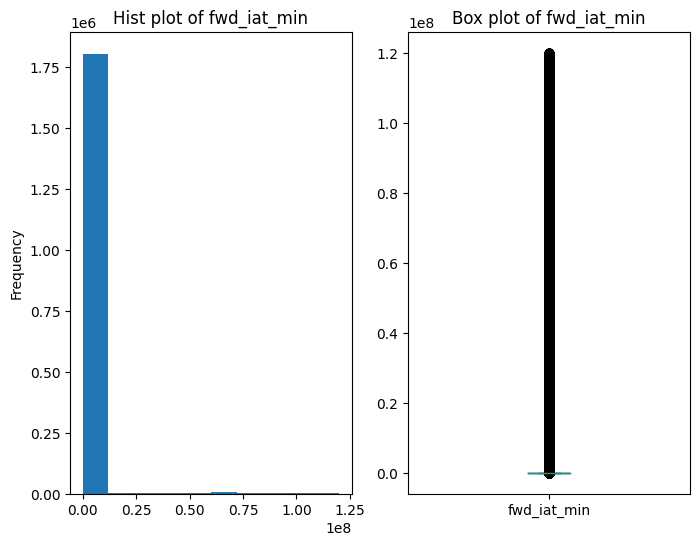

=====
central tendency of fwd_iat_mean: {'mean': 2005897.0636099617, 'median': 49.0, 'mode': 0.0, 'min': 0.0, 'max': 119999570.0, 'range': 119999570.0}
=====
Dispersion of fwd_iat_mean: 
 {'range': 119999570.0, 'q1': 1.0, 'q3': 81101.5, 'iqr': 81100.5, 'var': 95219232375038.03, 'skew': 8.112063399904024, 'kurtosis': 72.55961540535347}
=====


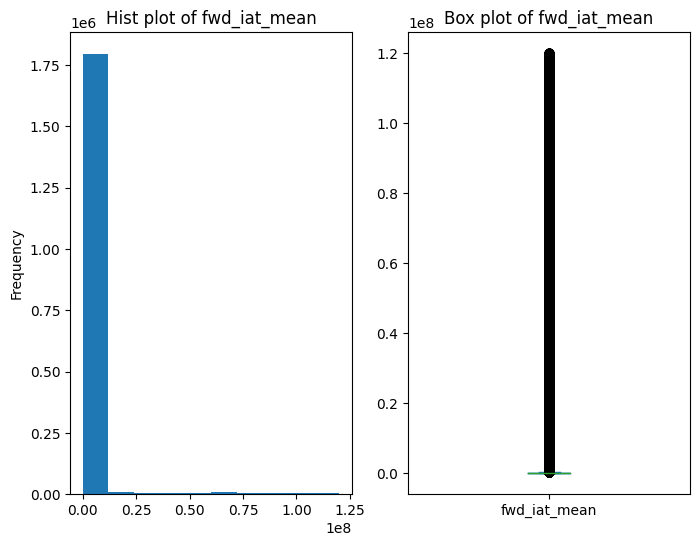

=====
central tendency of fwd_iat_std: {'mean': 1244303.5837361068, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 83228041.458245, 'range': 83228041.458245}
=====
Dispersion of fwd_iat_std: 
 {'range': 83228041.458245, 'q1': 0.0, 'q3': 56931.3376625, 'iqr': 56931.3376625, 'var': 17935867489802.535, 'skew': 7.255411496851478, 'kurtosis': 75.54072917705889}
=====


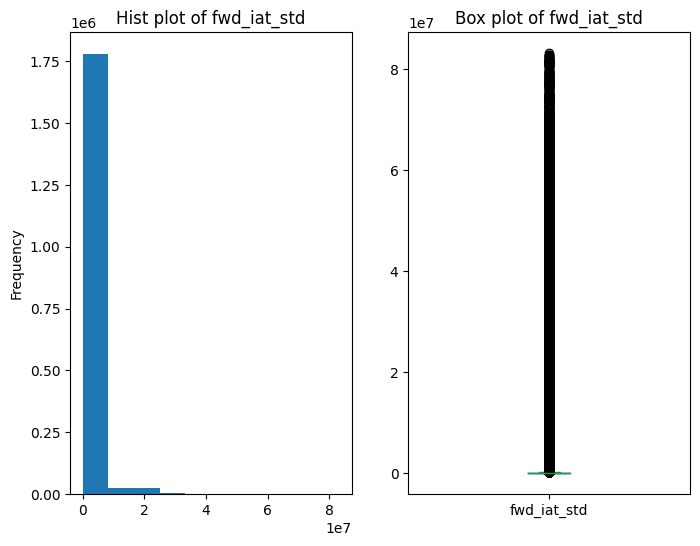

=====
central tendency of bwd_iat_tot: {'mean': 10910015.265792942, 'median': 48.0, 'mode': 0, 'min': 0, 'max': 119999992, 'range': 119999992}
=====
Dispersion of bwd_iat_tot: 
 {'range': 119999992, 'q1': 0.0, 'q3': 239181.75, 'iqr': 239181.75, 'var': 902989340509231.6, 'skew': 2.757984373116458, 'kurtosis': 6.118432001940669}
=====


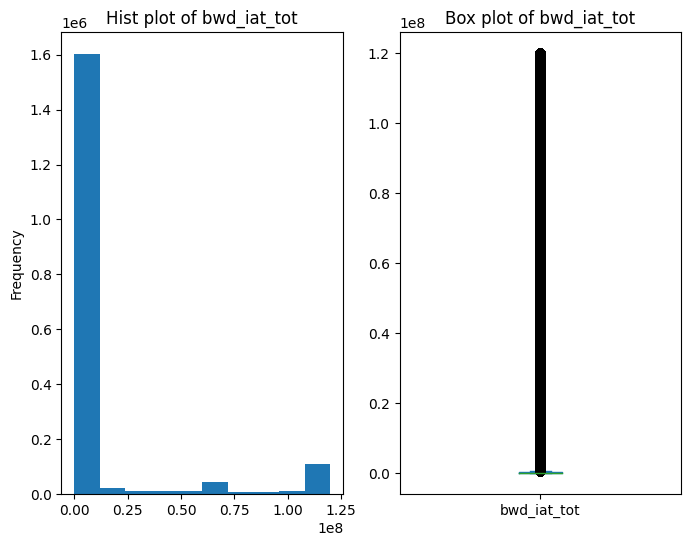

=====
central tendency of bwd_iat_max: {'mean': 3891474.0287456093, 'median': 48.0, 'mode': 0.0, 'min': 0.0, 'max': 119991381.0, 'range': 119991381.0}
=====
Dispersion of bwd_iat_max: 
 {'range': 119991381.0, 'q1': 0.0, 'q3': 155140.5, 'iqr': 155140.5, 'var': 189767788431242.94, 'skew': 4.956180649095514, 'kurtosis': 26.626550434000656}
=====


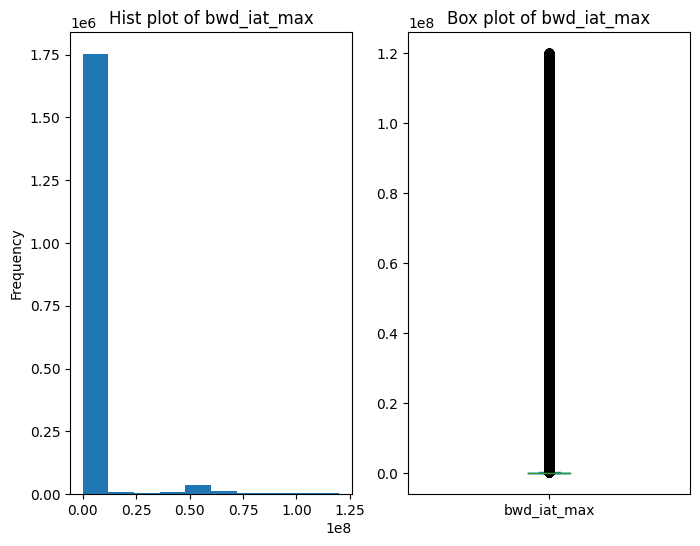

=====
central tendency of bwd_iat_min: {'mean': 1353950.3193184428, 'median': 3.0, 'mode': 0.0, 'min': 0.0, 'max': 119976977.0, 'range': 119976977.0}
=====
Dispersion of bwd_iat_min: 
 {'range': 119976977.0, 'q1': 0.0, 'q3': 48.0, 'iqr': 48.0, 'var': 96334470807342.5, 'skew': 8.327485050578817, 'kurtosis': 73.72707907197429}
=====


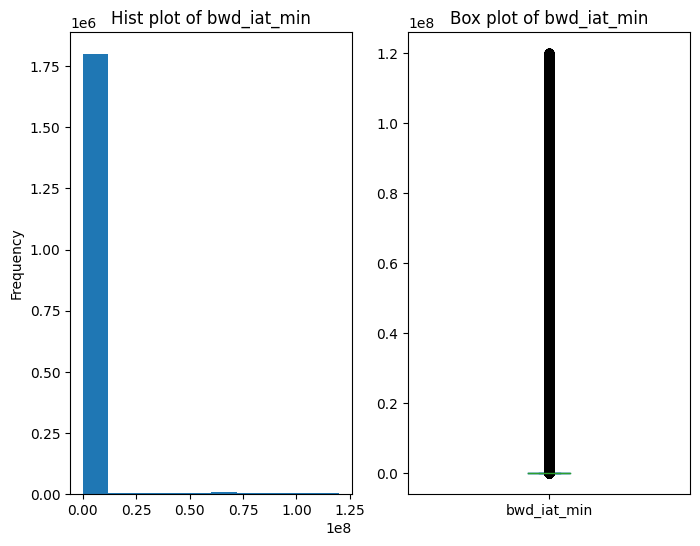

=====
central tendency of bwd_iat_mean: {'mean': 2072981.3334411308, 'median': 48.0, 'mode': 0.0, 'min': 0.0, 'max': 119976977.0, 'range': 119976977.0}
=====
Dispersion of bwd_iat_mean: 
 {'range': 119976977.0, 'q1': 0.0, 'q3': 43910.149999999994, 'iqr': 43910.149999999994, 'var': 104215842303338.56, 'skew': 7.493003075459294, 'kurtosis': 61.835607358372584}
=====


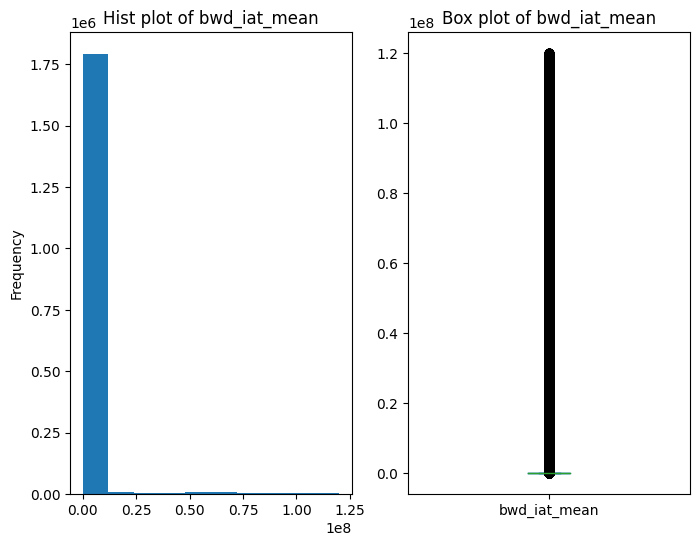

=====
central tendency of bwd_iat_std: {'mean': 999934.0261152615, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 83273028.298771, 'range': 83273028.298771}
=====
Dispersion of bwd_iat_std: 
 {'range': 83273028.298771, 'q1': 0.0, 'q3': 58790.42451775, 'iqr': 58790.42451775, 'var': 17634030560644.13, 'skew': 9.171689196342356, 'kurtosis': 117.31913616461185}
=====


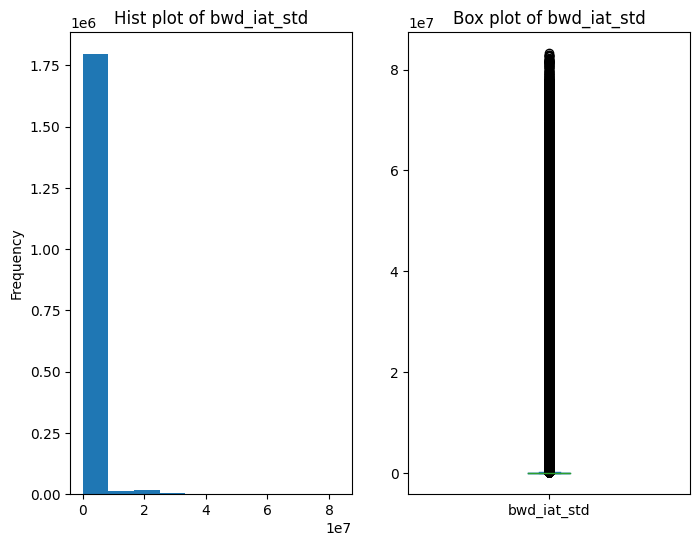

=====
central tendency of active_max: {'mean': 182706.70709029344, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_max: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 1220756283782.718, 'skew': 24.20444295488613, 'kurtosis': 1344.2114350649065}
=====


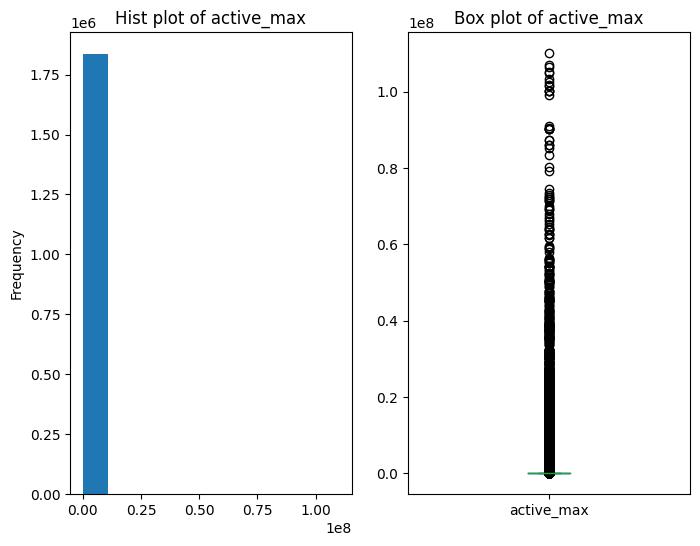

=====
central tendency of active_min: {'mean': 62362.70855968279, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_min: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 410026178454.57404, 'skew': 49.461126100786984, 'kurtosis': 5721.584624426495}
=====


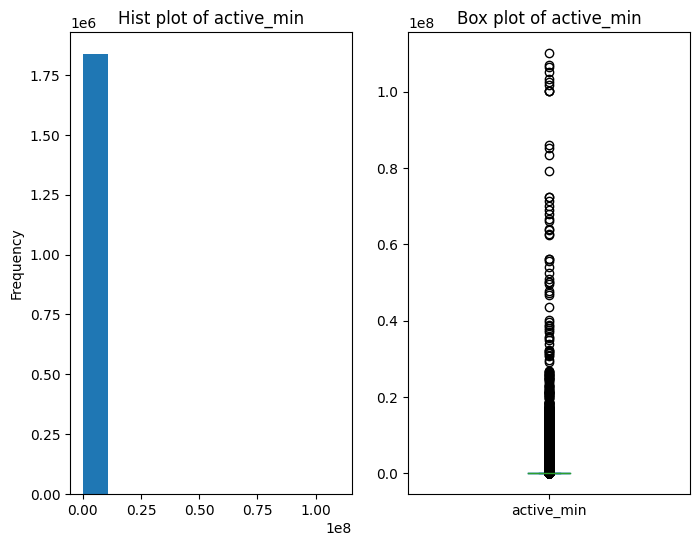

=====
central tendency of active_mean: {'mean': 90855.47339025066, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_mean: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 508441791375.9122, 'skew': 40.202158373583295, 'kurtosis': 3920.6992777660994}
=====


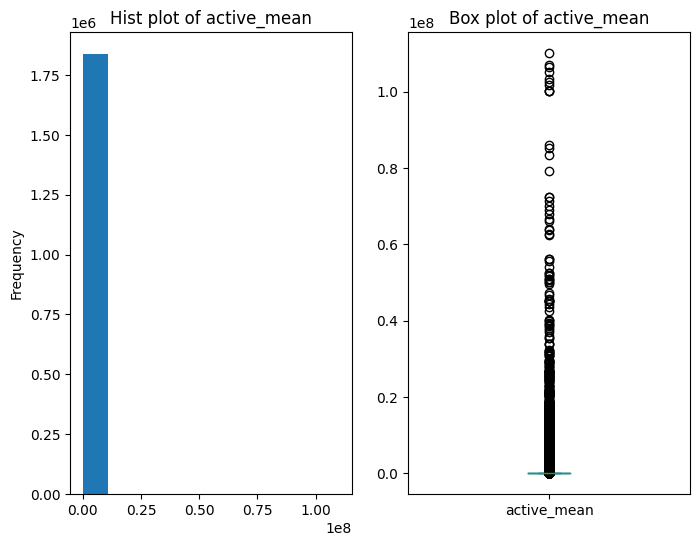

=====
central tendency of active_std: {'mean': 52481.369139203525, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 74154397.744584, 'range': 74154397.744584}
=====
Dispersion of active_std: 
 {'range': 74154397.744584, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 186819270059.87686, 'skew': 40.15785197022466, 'kurtosis': 4054.5715254486145}
=====


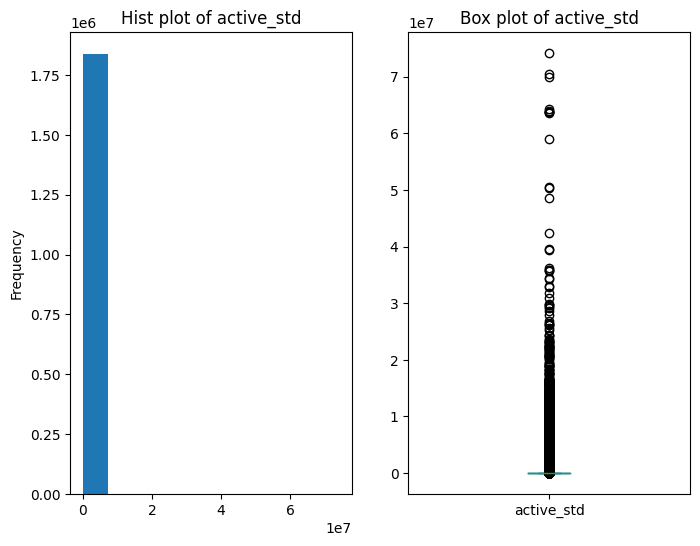

=====
central tendency of idle_max: {'mean': 4033049.586569346, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_max: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 196413552298151.8, 'skew': 4.790198814512726, 'kurtosis': 25.058044506532042}
=====


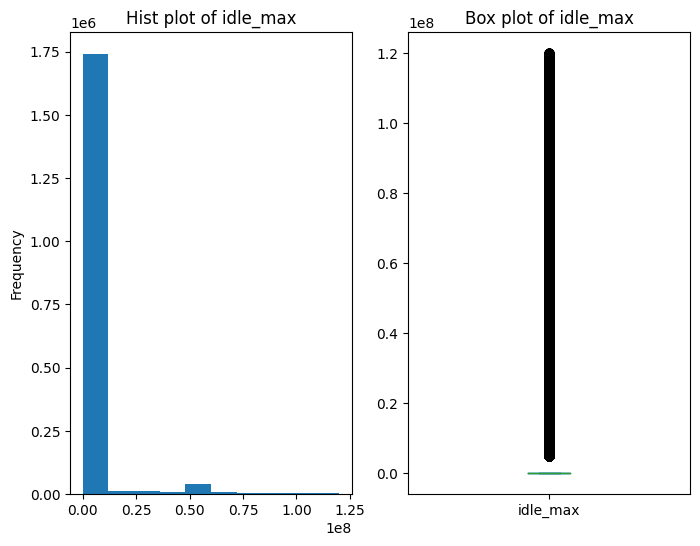

=====
central tendency of idle_min: {'mean': 3658133.306791082, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_min: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 178720382462066.4, 'skew': 5.195765789635457, 'kurtosis': 29.586893500529126}
=====


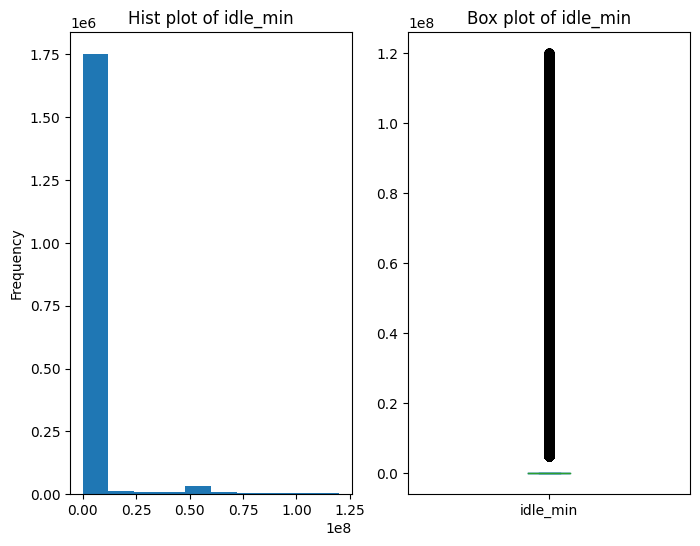

=====
central tendency of idle_mean: {'mean': 3855138.1421034485, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_mean: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 184098296533671.47, 'skew': 5.002860306377417, 'kurtosis': 27.660063698526507}
=====


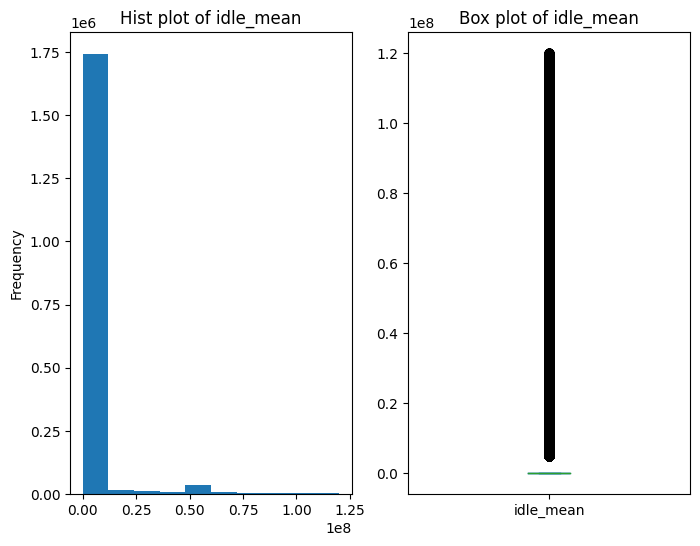

=====
central tendency of idle_std: {'mean': 204665.1016673838, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 76914831.602572, 'range': 76914831.602572}
=====
Dispersion of idle_std: 
 {'range': 76914831.602572, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 4714098662946.028, 'skew': 15.716250632272546, 'kurtosis': 301.1203483912579}
=====


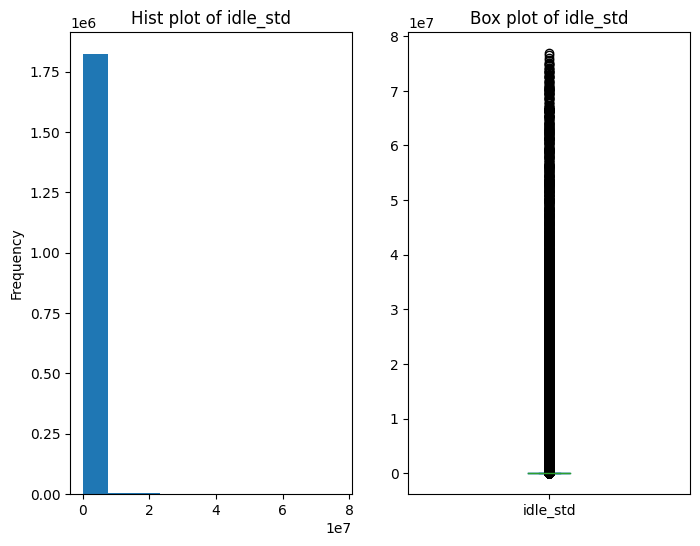

=====
central tendency of flag_SYN: {'mean': 0.9387291850113578, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 52, 'range': 52}
=====
Dispersion of flag_SYN: 
 {'range': 52, 'q1': 0.0, 'q3': 2.0, 'iqr': 2.0, 'var': 1.1222422813721624, 'skew': 0.9470519859510402, 'kurtosis': 6.906866431323574}
=====


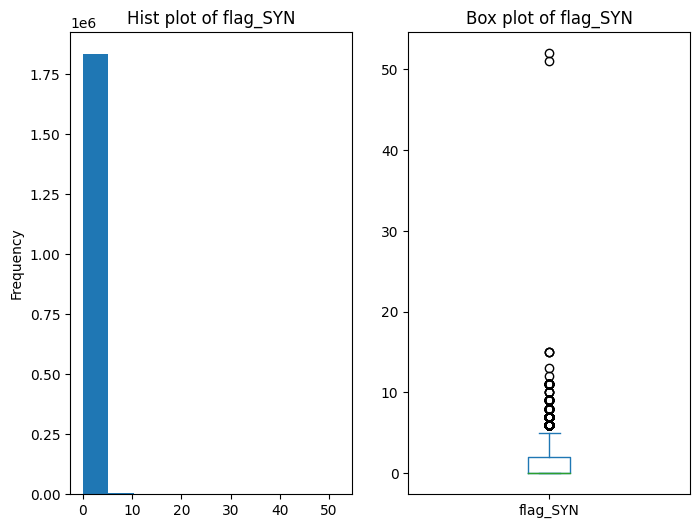

=====
central tendency of flag_fin: {'mean': 0.3834197370554961, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1, 'range': 1}
=====
Dispersion of flag_fin: 
 {'range': 1, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 0.2364091709499826, 'skew': 0.4795383436826683, 'kurtosis': -1.7700449035208525}
=====


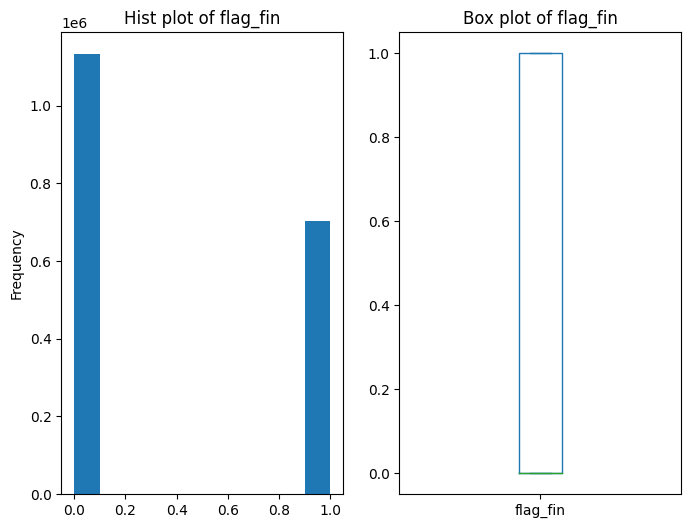

=====
central tendency of flag_rst: {'mean': 0.09971602690179798, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1, 'range': 1}
=====
Dispersion of flag_rst: 
 {'range': 1, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.08977278973671106, 'skew': 2.671937587920636, 'kurtosis': 5.139256067496157}
=====


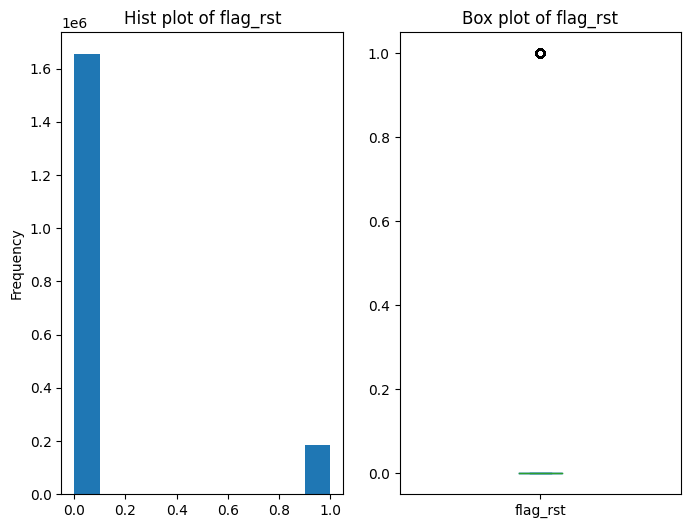

=====
central tendency of flag_ack: {'mean': 24.42313624286938, 'median': 1.0, 'mode': 0, 'min': 0, 'max': 511681, 'range': 511681}
=====
Dispersion of flag_ack: 
 {'range': 511681, 'q1': 0.0, 'q3': 8.0, 'iqr': 8.0, 'var': 4694449.139656008, 'skew': 197.29891790103028, 'kurtosis': 40247.141295553156}
=====


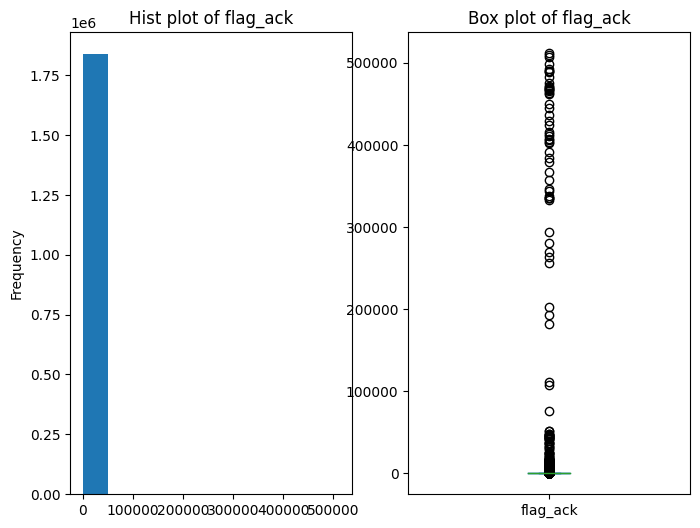

=====
central tendency of flag_psh: {'mean': 3.1683920200185254, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 9861, 'range': 9861}
=====
Dispersion of flag_psh: 
 {'range': 9861, 'q1': 0.0, 'q3': 2.0, 'iqr': 2.0, 'var': 829.8130653498575, 'skew': 167.453202484809, 'kurtosis': 38556.70552037928}
=====


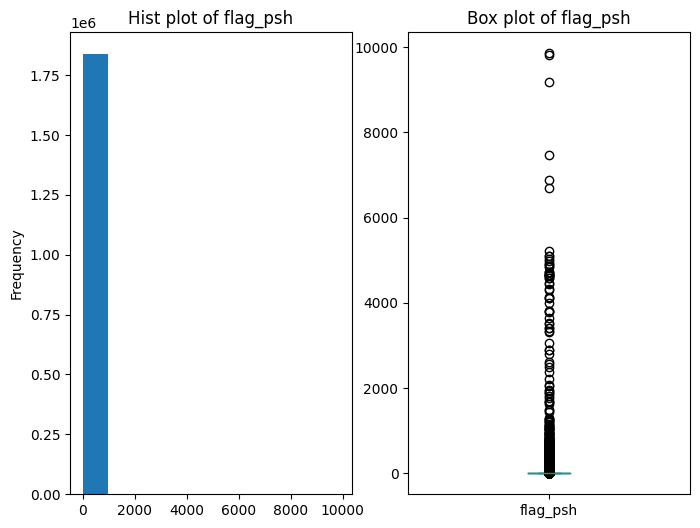

=====
central tendency of fwd_flag_psh: {'mean': 1.4157539219090307, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1589, 'range': 1589}
=====
Dispersion of fwd_flag_psh: 
 {'range': 1589, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 22.917827369851125, 'skew': 57.04711685041641, 'kurtosis': 10821.28454219773}
=====


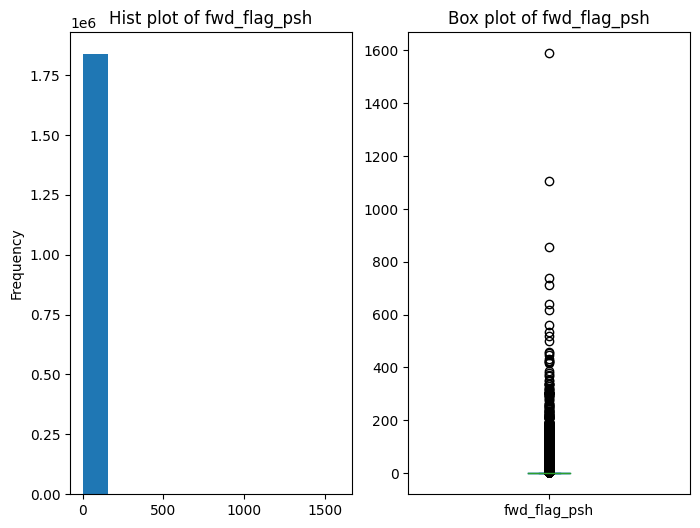

=====
central tendency of bwd_flag_psh: {'mean': 1.7526380981094944, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 9761, 'range': 9761}
=====
Dispersion of bwd_flag_psh: 
 {'range': 9761, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 726.2836055442918, 'skew': 192.0457283549542, 'kurtosis': 47292.35304774784}
=====


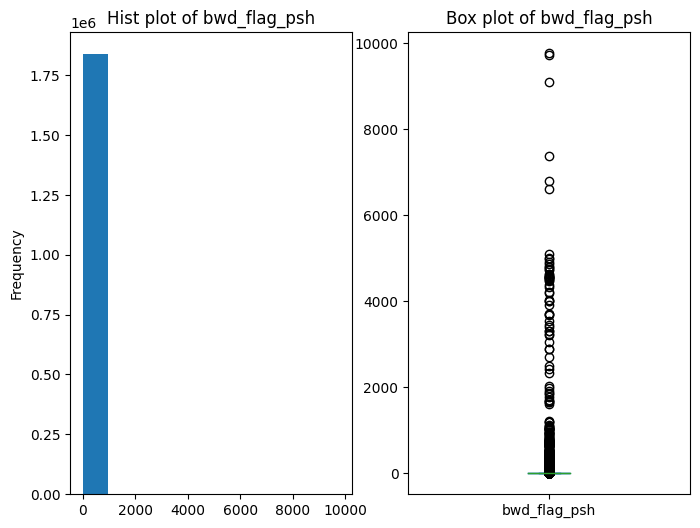

=====
central tendency of flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


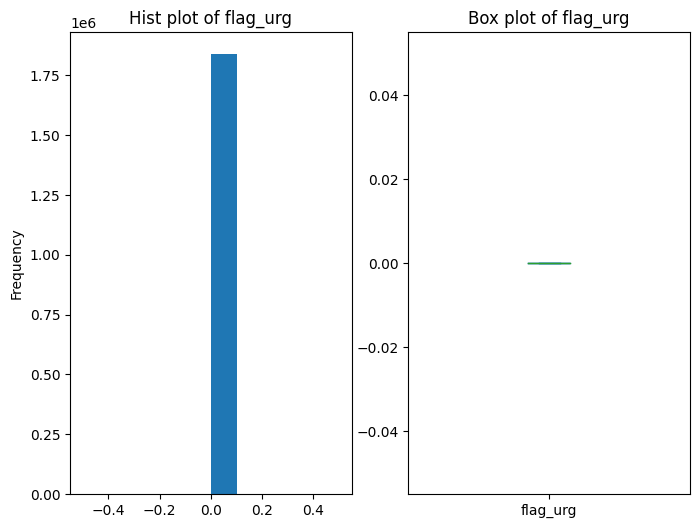

=====
central tendency of fwd_flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of fwd_flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


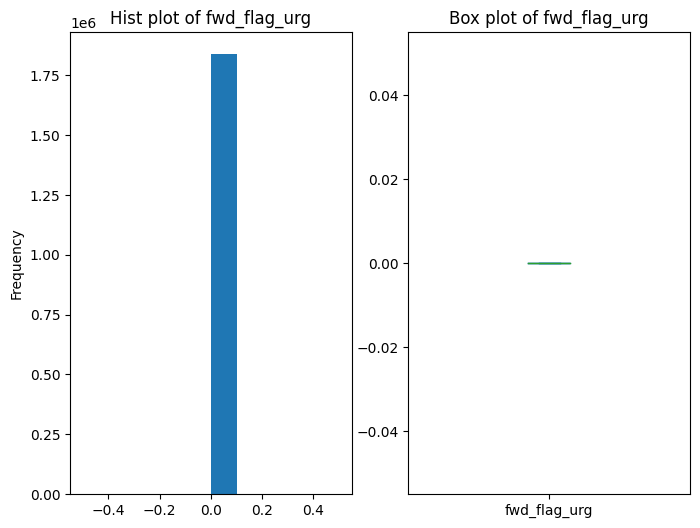

=====
central tendency of bwd_flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of bwd_flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


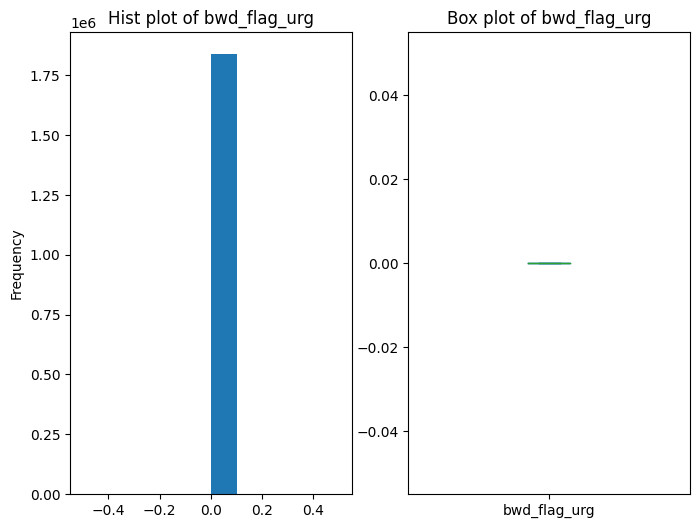

=====
central tendency of flag_cwr: {'mean': 0.00040870792784536365, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 23, 'range': 23}
=====
Dispersion of flag_cwr: 
 {'range': 23, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0008341200341258751, 'skew': 336.2663139268284, 'kurtosis': 230693.25691526328}
=====


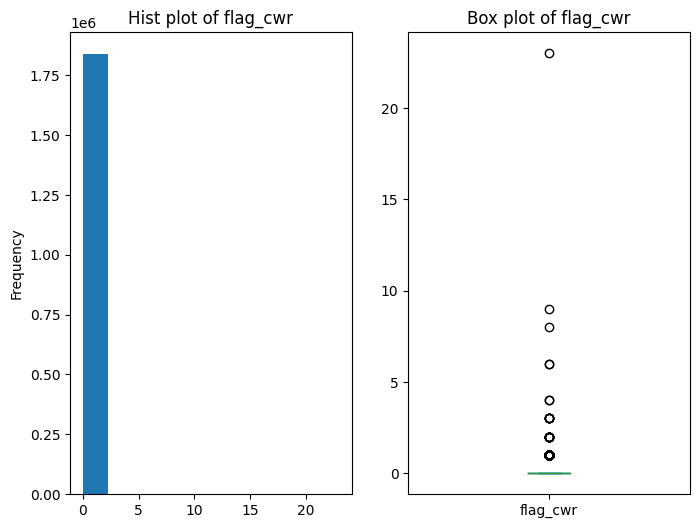

=====
central tendency of flag_ece: {'mean': 0.0006057149449958585, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 2, 'range': 2}
=====
Dispersion of flag_ece: 
 {'range': 2, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0011658935167057254, 'skew': 57.404033708509154, 'kurtosis': 3325.1696505591226}
=====


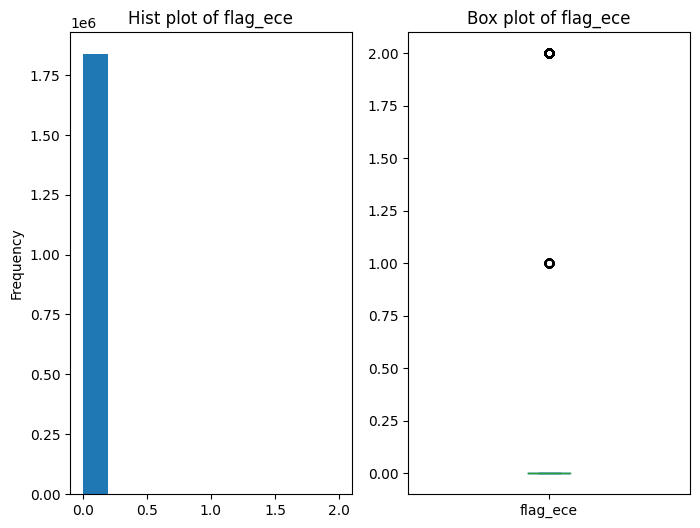

=====
central tendency of fwd_bulk_bytes_mean: {'mean': 67.7536686902544, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 351373.0, 'range': 351373.0}
=====
Dispersion of fwd_bulk_bytes_mean: 
 {'range': 351373.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 1971303.8134196044, 'skew': 93.29873147373445, 'kurtosis': 16138.658510614734}
=====


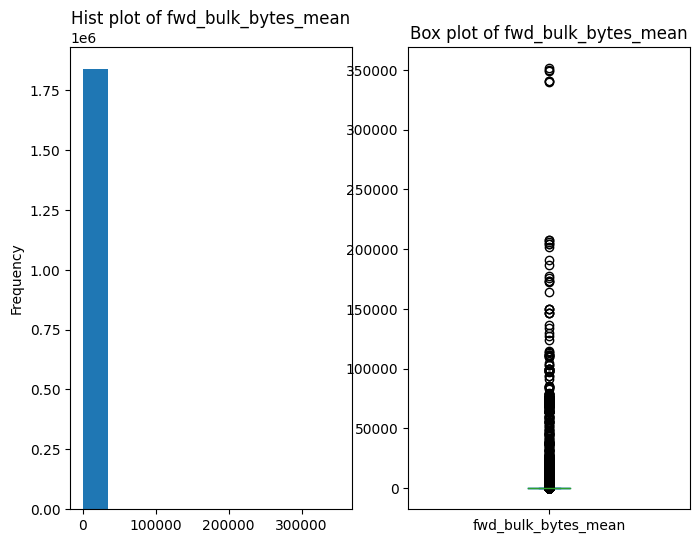

=====
central tendency of fwd_bulk_pkt_mean: {'mean': 0.2369939670715287, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 360.0, 'range': 360.0}
=====
Dispersion of fwd_bulk_pkt_mean: 
 {'range': 360.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 2.698927282083065, 'skew': 36.195316481313476, 'kurtosis': 4370.456263331852}
=====


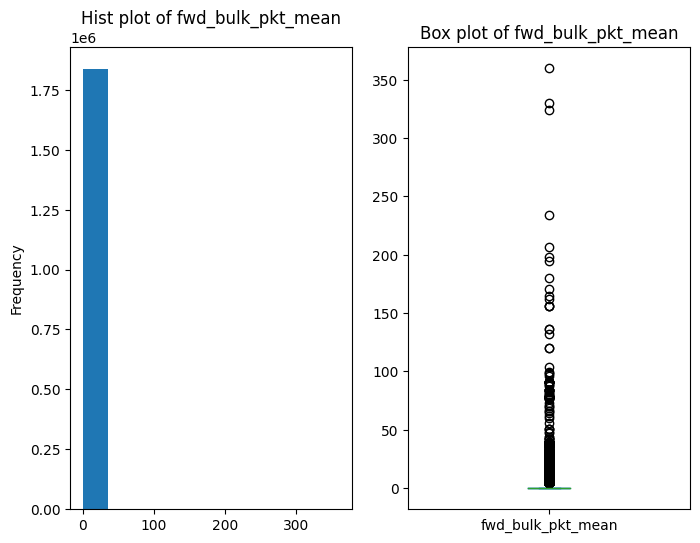

=====
central tendency of fwd_bulk_rate_mean: {'mean': 182195.14421378967, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 974000000.0, 'range': 974000000.0}
=====
Dispersion of fwd_bulk_rate_mean: 
 {'range': 974000000.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 17057822188820.076, 'skew': 51.92490439337114, 'kurtosis': 5952.015713026731}
=====


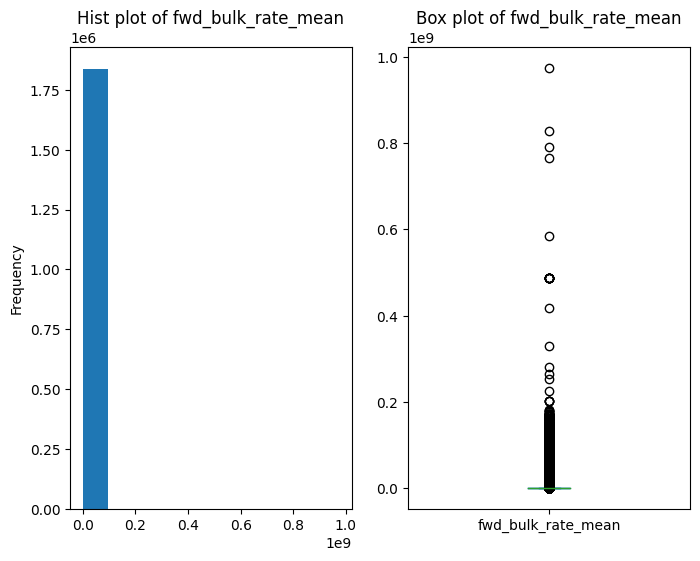

=====
central tendency of bwd_bulk_bytes_mean: {'mean': 4215.857202688916, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 156761876.25, 'range': 156761876.25}
=====
Dispersion of bwd_bulk_bytes_mean: 
 {'range': 156761876.25, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 101392215136.60713, 'skew': 400.7541587568549, 'kurtosis': 180437.8061248833}
=====


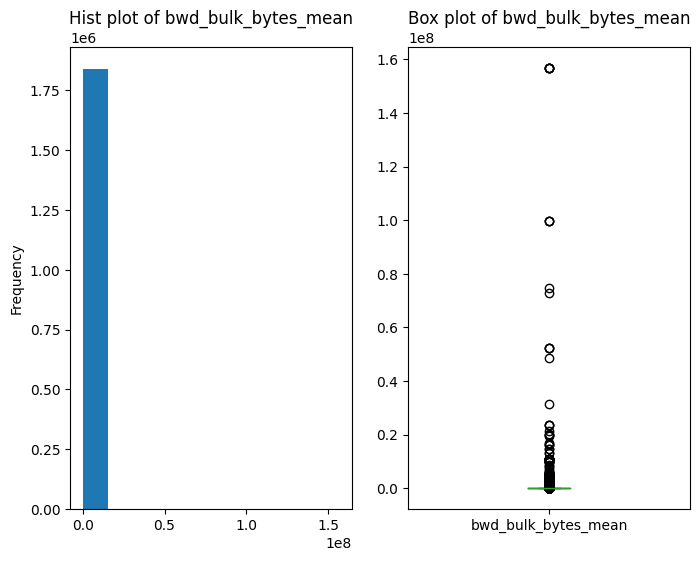

=====
central tendency of bwd_bulk_pkt_mean: {'mean': 2.0933050419782773, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 58270.75, 'range': 58270.75}
=====
Dispersion of bwd_bulk_pkt_mean: 
 {'range': 58270.75, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 12781.165915544985, 'skew': 376.1229499029029, 'kurtosis': 164113.31591496267}
=====


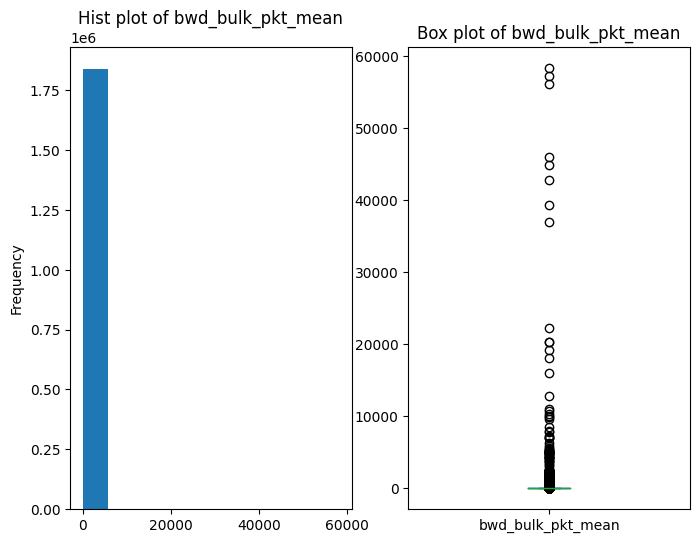

=====
central tendency of bwd_bulk_rate_mean: {'mean': 2855677.4026941564, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1369000000.0, 'range': 1369000000.0}
=====
Dispersion of bwd_bulk_rate_mean: 
 {'range': 1369000000.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 106853084398559.45, 'skew': 11.927733798005896, 'kurtosis': 702.5766537728558}
=====


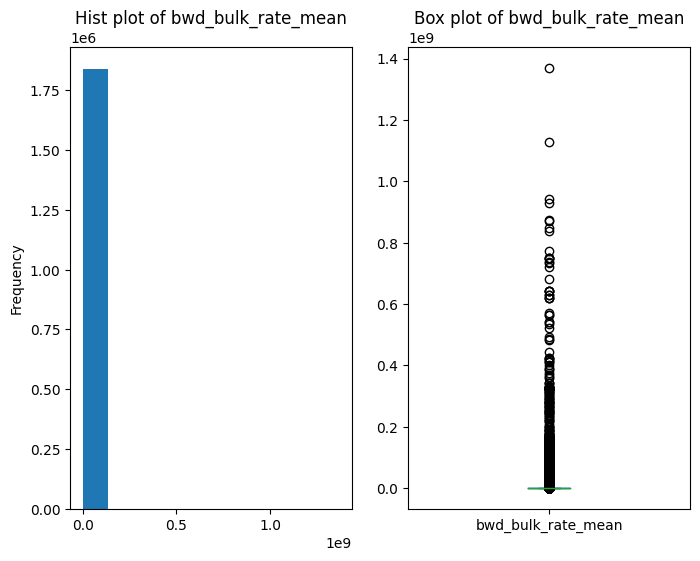

=====
central tendency of fwd_subflow_bytes_mean: {'mean': 268.14844081993175, 'median': 74.0, 'mode': 0.0, 'min': 0.0, 'max': 1783979.0, 'range': 1783979.0}
=====
Dispersion of fwd_subflow_bytes_mean: 
 {'range': 1783979.0, 'q1': 48.0, 'q3': 202.0, 'iqr': 154.0, 'var': 6017734.336430733, 'skew': 419.3760588059683, 'kurtosis': 263456.99759191566}
=====


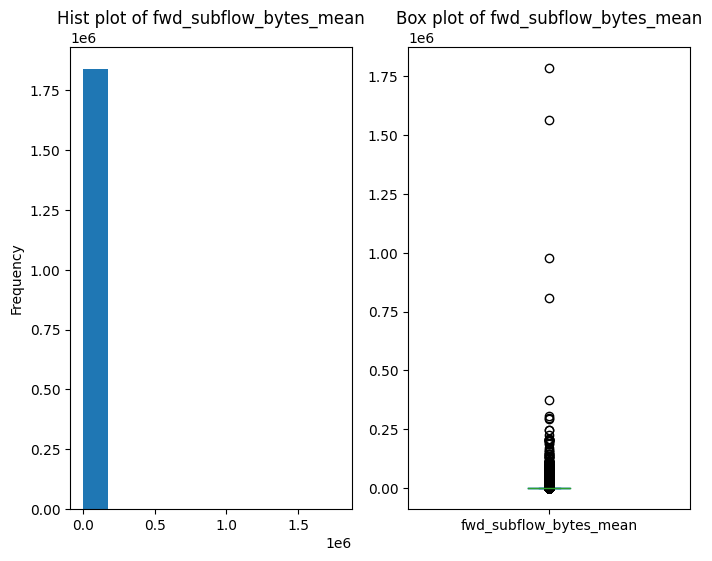

=====
central tendency of fwd_subflow_pkt_mean: {'mean': 6.813950739654139, 'median': 2.0, 'mode': 2.0, 'min': 0.0, 'max': 219759.0, 'range': 219759.0}
=====
Dispersion of fwd_subflow_pkt_mean: 
 {'range': 219759.0, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 522145.01377331495, 'skew': 257.69445181587054, 'kurtosis': 70222.03745469746}
=====


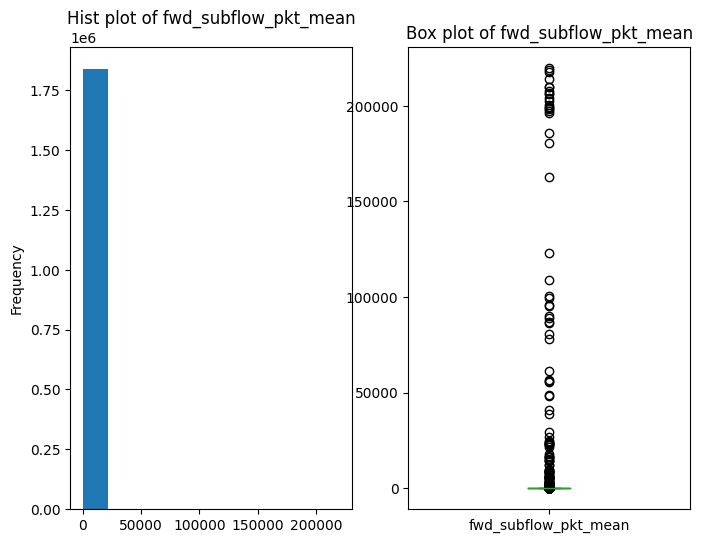

=====
central tendency of bwd_subflow_bytes_mean: {'mean': 13959.962720128824, 'median': 206.0, 'mode': 0.0, 'min': 0.0, 'max': 655452323.0, 'range': 655452323.0}
=====
Dispersion of bwd_subflow_bytes_mean: 
 {'range': 655452323.0, 'q1': 98.0, 'q3': 1762.5, 'iqr': 1664.5, 'var': 4627389610332.941, 'skew': 253.34306942536818, 'kurtosis': 67813.2492445578}
=====


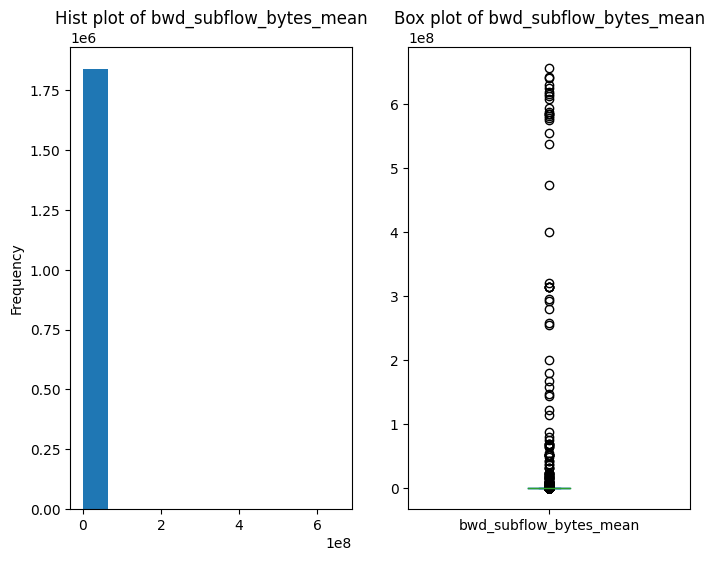

=====
central tendency of bwd_subflow_pkt_mean: {'mean': 8.270970366132099, 'median': 2.0, 'mode': 2.0, 'min': 0.0, 'max': 291922.0, 'range': 291922.0}
=====
Dispersion of bwd_subflow_pkt_mean: 
 {'range': 291922.0, 'q1': 1.0, 'q3': 3.5, 'iqr': 2.5, 'var': 935935.8401020962, 'skew': 258.941660484433, 'kurtosis': 70789.80365777202}
=====


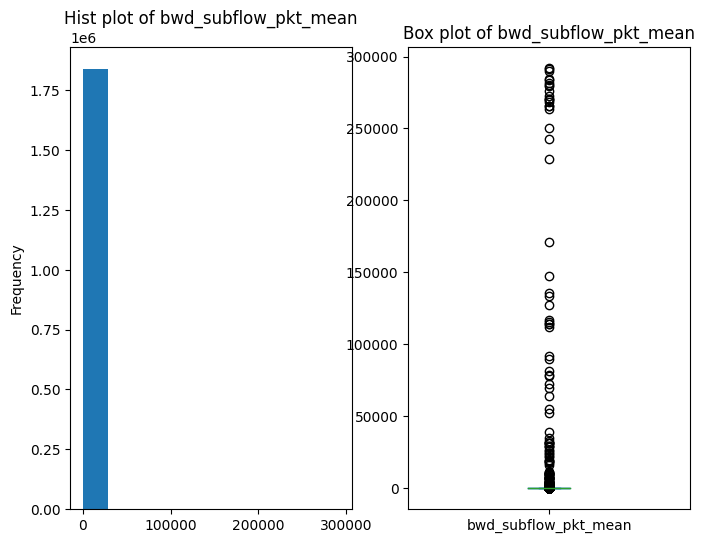

=====
central tendency of fwd_tcp_init_win_bytes: {'mean': 10695.108767465324, 'median': 364.0, 'mode': -1, 'min': -1, 'max': 65535, 'range': 65536}
=====
Dispersion of fwd_tcp_init_win_bytes: 
 {'range': 65536, 'q1': -1.0, 'q3': 29200.0, 'iqr': 29201.0, 'var': 245943014.2544253, 'skew': 1.6644854267014937, 'kurtosis': 2.621052849816807}
=====


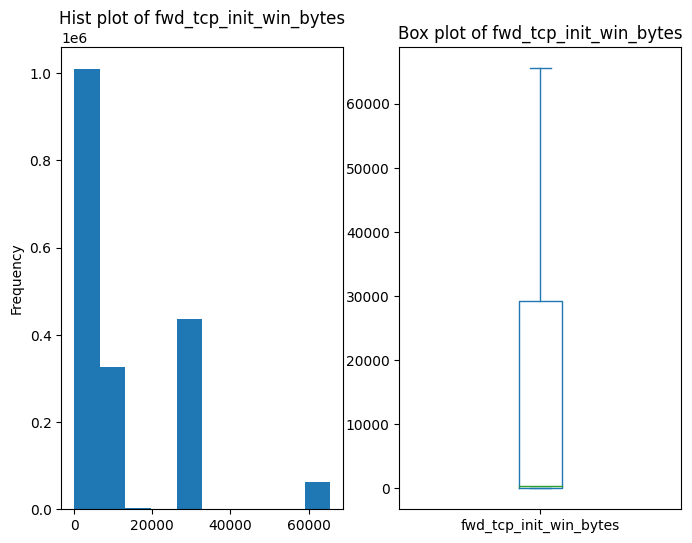

=====
central tendency of bwd_tcp_init_win_bytes: {'mean': 11462.36497509113, 'median': 0.0, 'mode': -1, 'min': -1, 'max': 65535, 'range': 65536}
=====
Dispersion of bwd_tcp_init_win_bytes: 
 {'range': 65536, 'q1': -1.0, 'q3': 28960.0, 'iqr': 28961.0, 'var': 241798244.31923515, 'skew': 1.0011387027953618, 'kurtosis': 0.07666360735557998}
=====


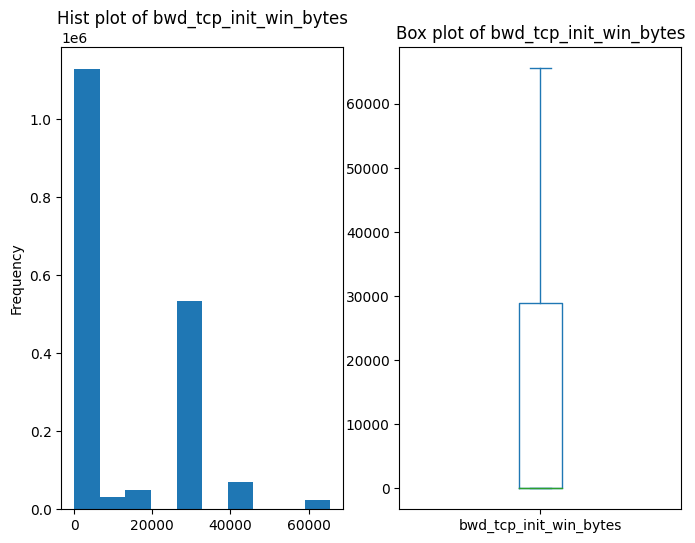

In [45]:
# Phân tích chi tiết từng biến numeric
_analyzer = Analyzer()
for col in numeric_cols:
    _analyzer.analyze_numeric_variable(variable_name=col, df=df_raw)
    print('=' * 50)

## Features - categorical

### Thống kê mô tả

In [46]:
# Thực hiện thống kê mô tả - dữ liệu categorical
df_raw[category_cols].describe()

,attack_type,dst_addr,dst_port,flow_id,ip_prot,label,source_day,src_addr,src_port
count,1837498,1837498,1837498,1837498,1837498,1837498,1837498,1837498,1837498
unique,14,18095,5077,942759,5,2,5,268,64491
top,benign,192.168.10.3,53,192.168.10.3-192.168.10.255-137-137-17,6,0,Friday,172.16.0.1,123
freq,1395675,602976,848618,451,949815,1395675,542962,442471,22691


### Phân bổ

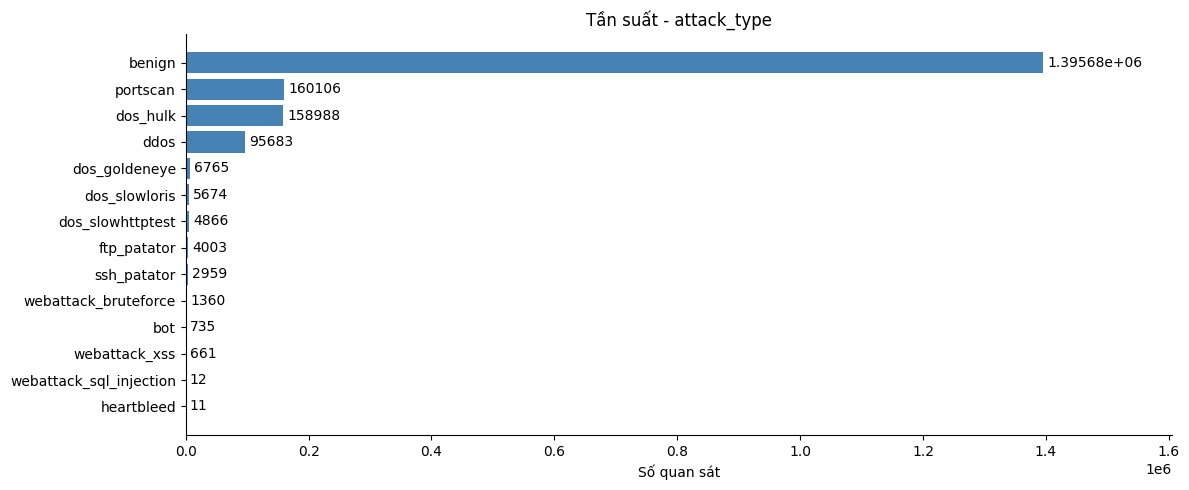

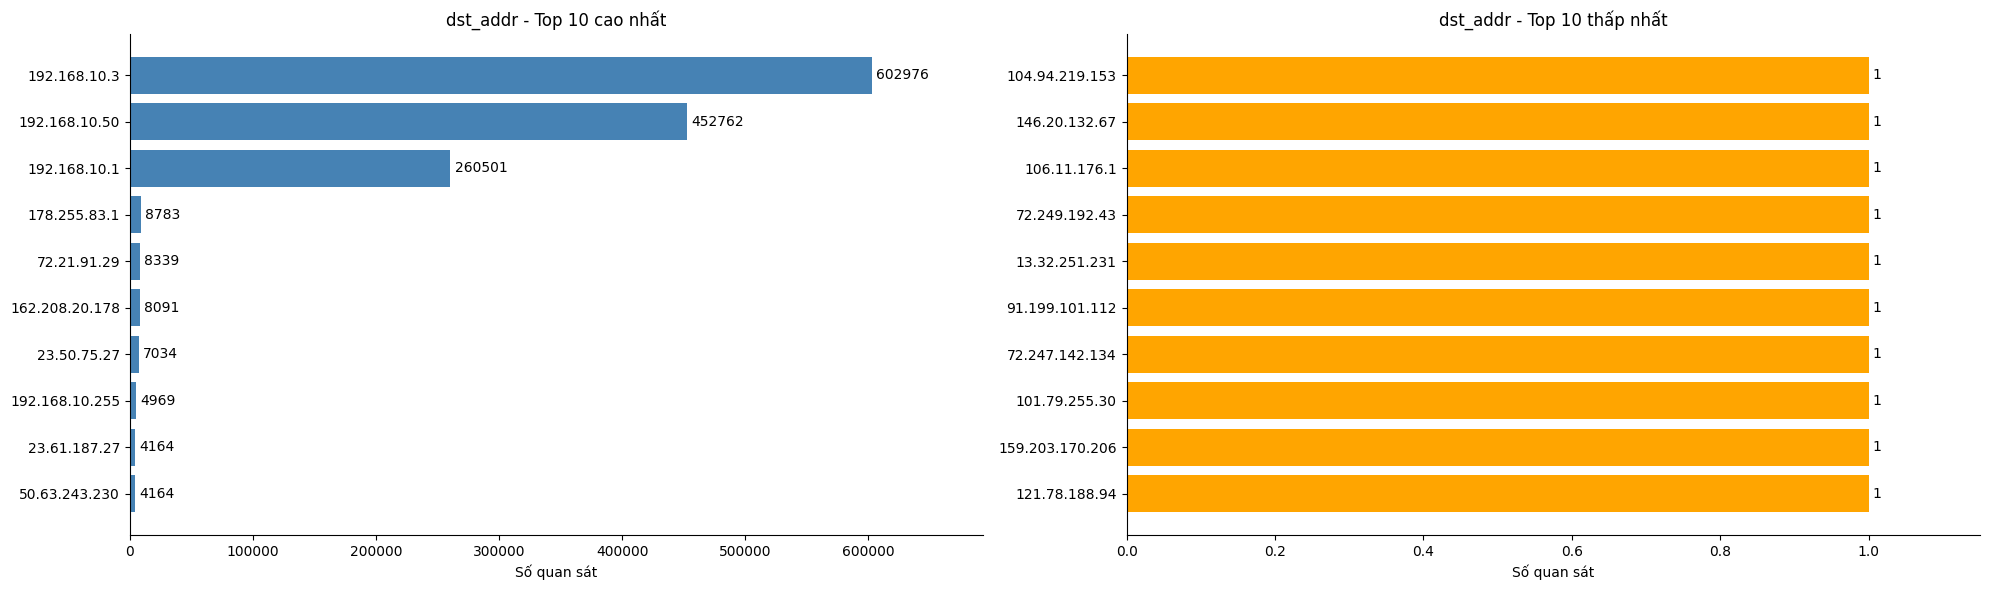

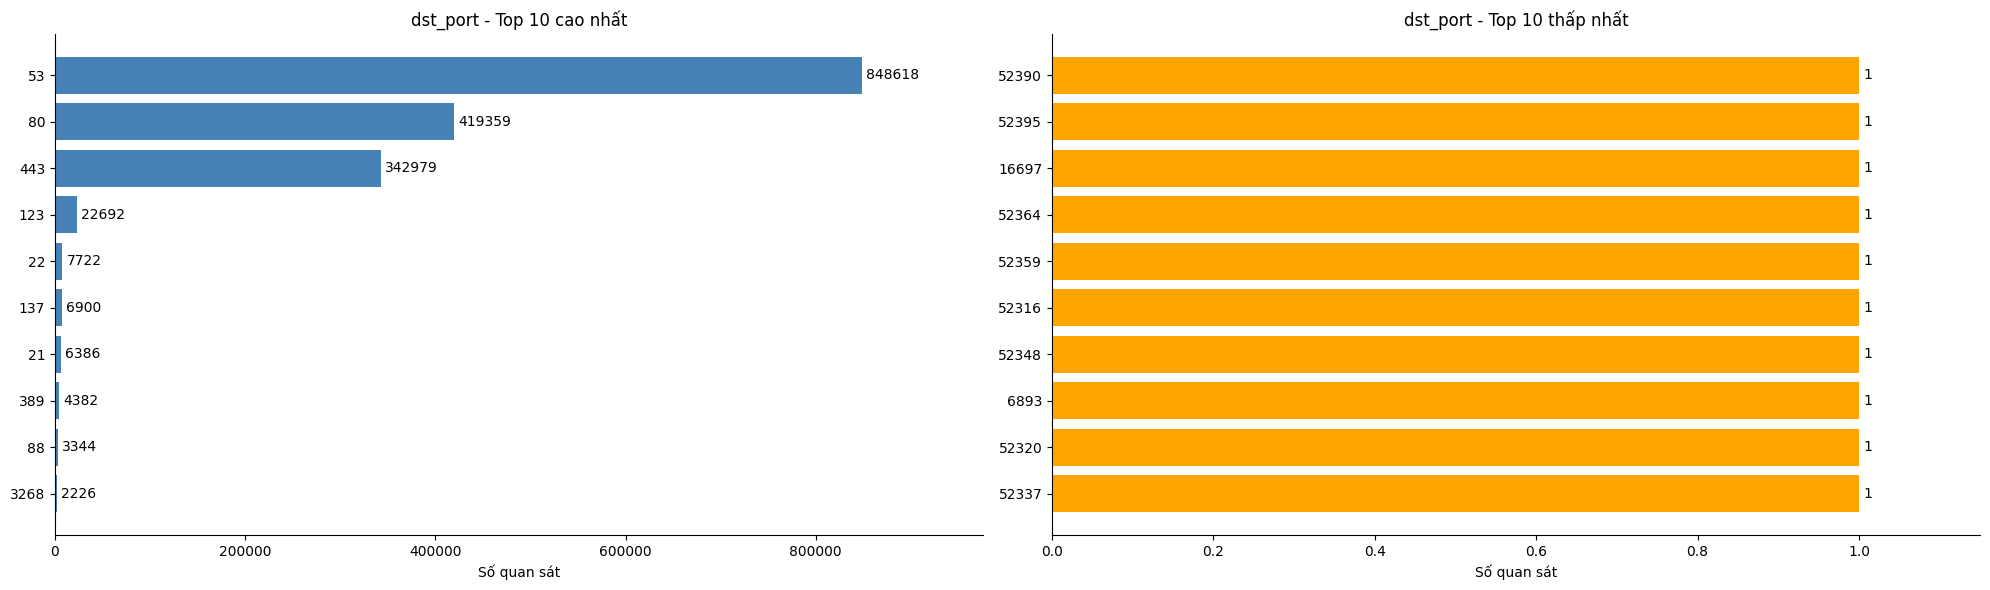

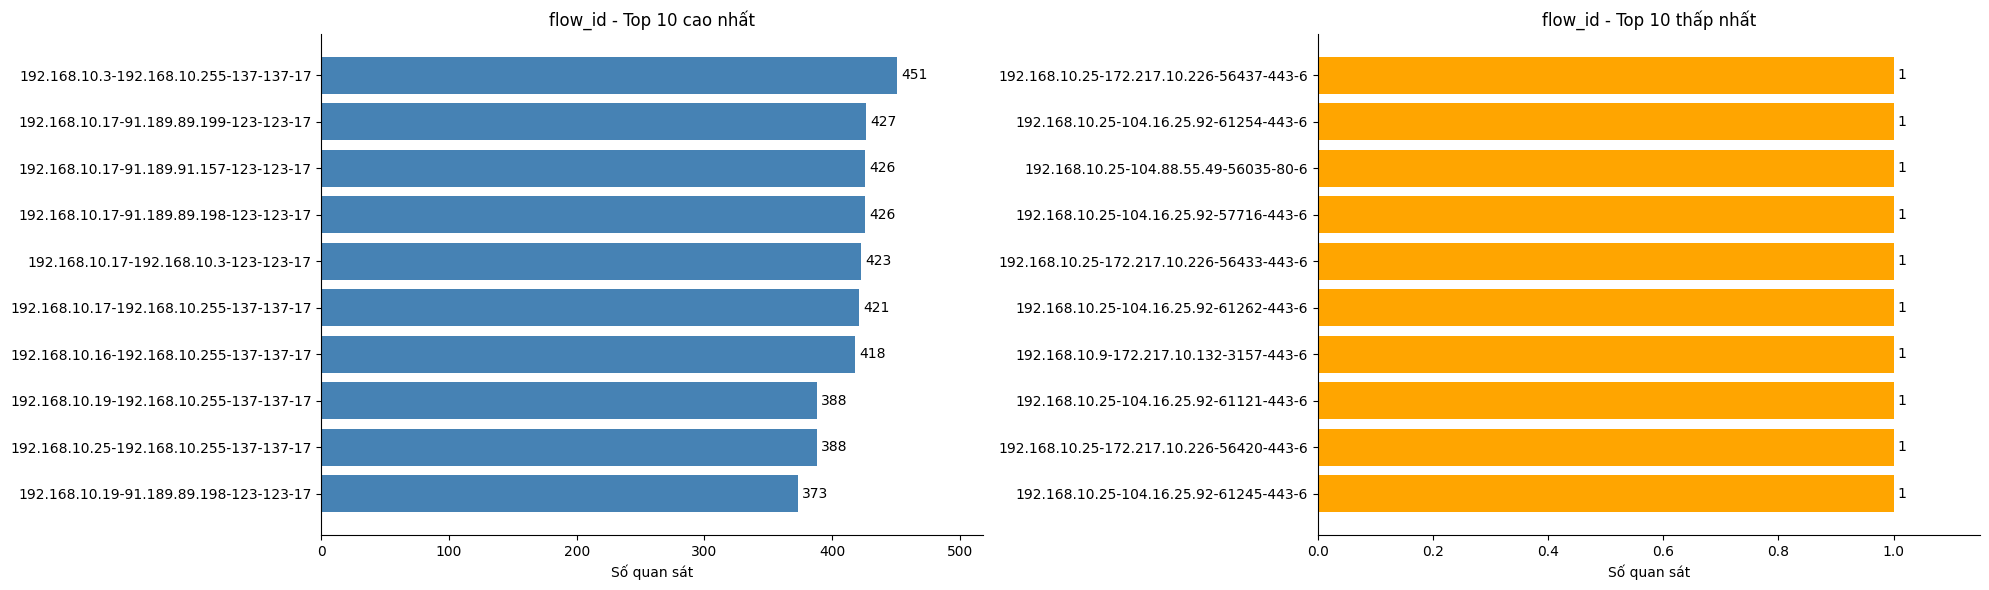

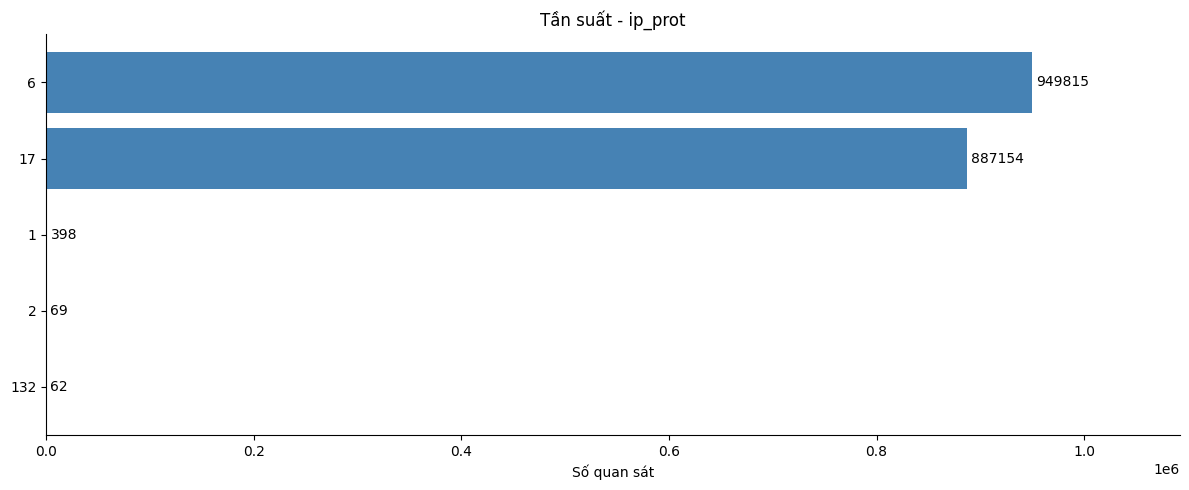

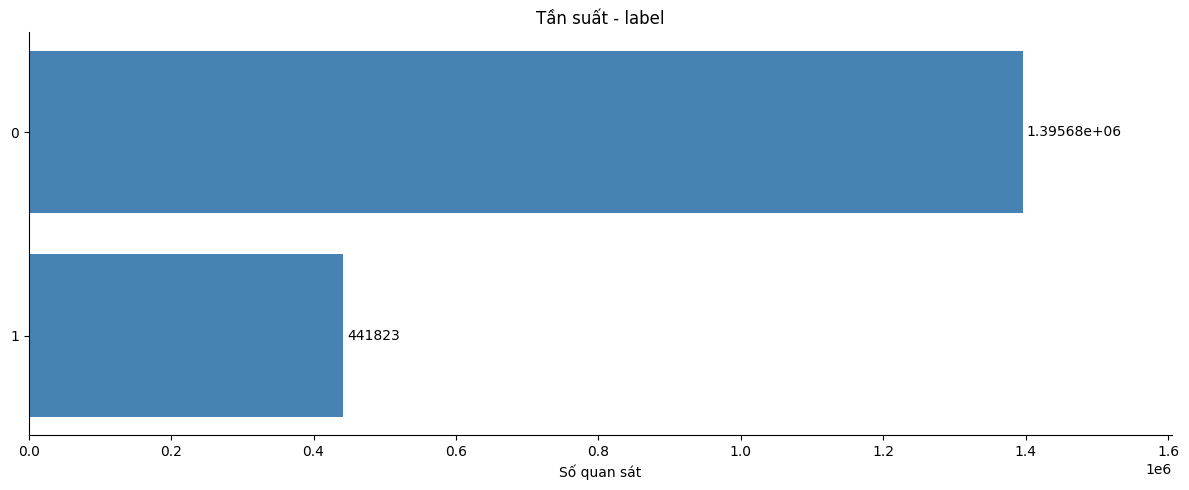

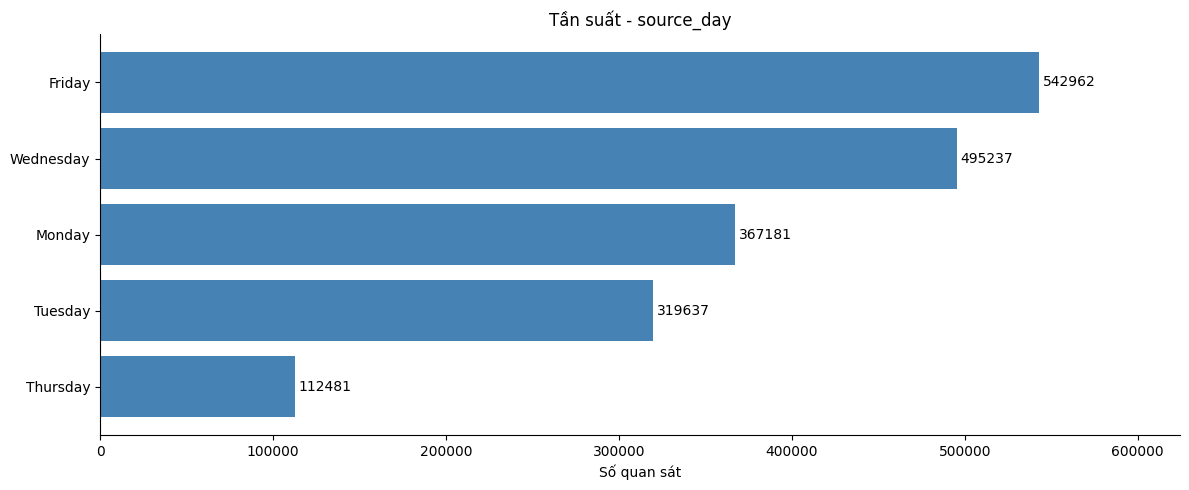

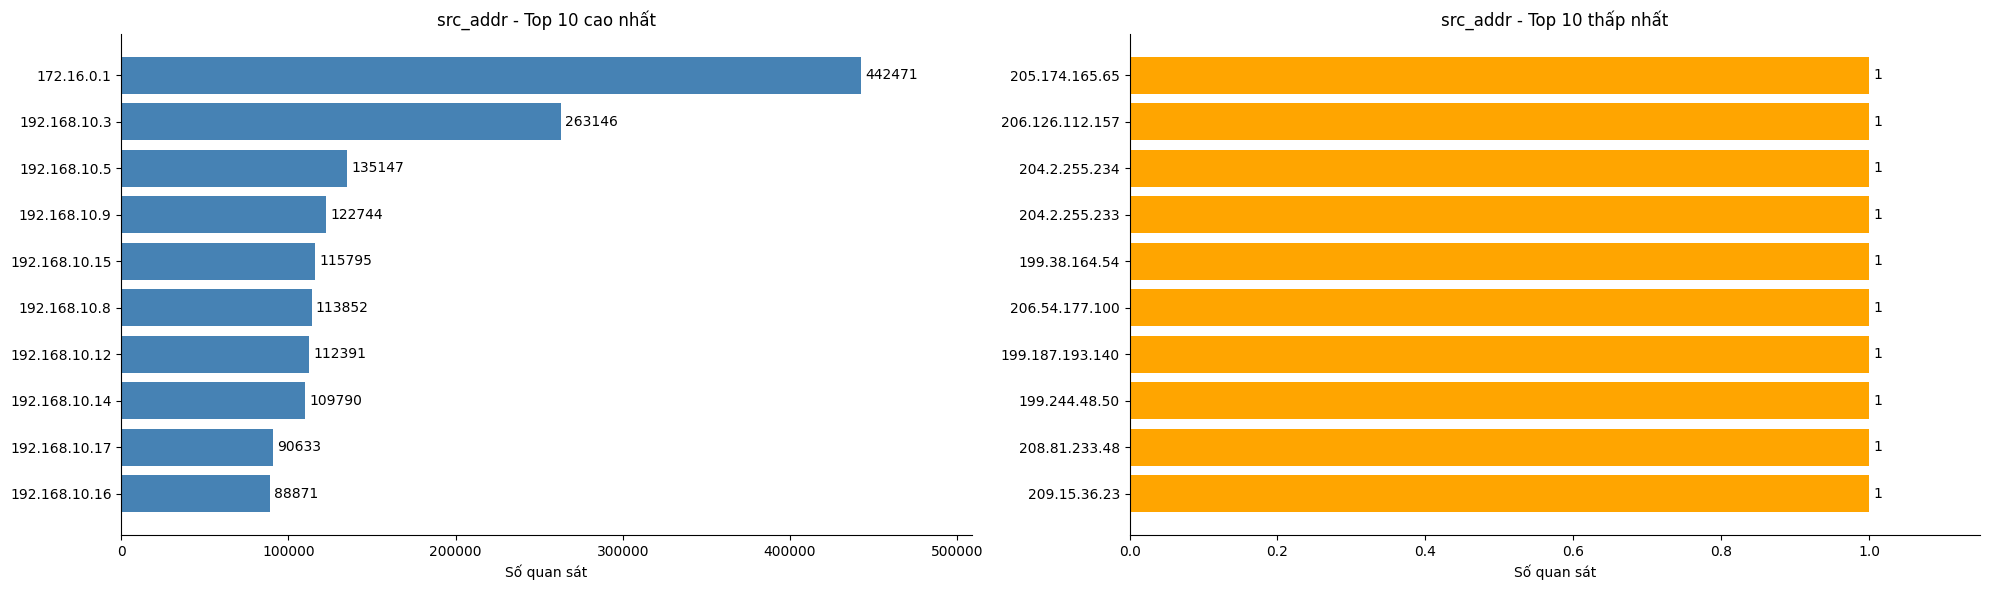

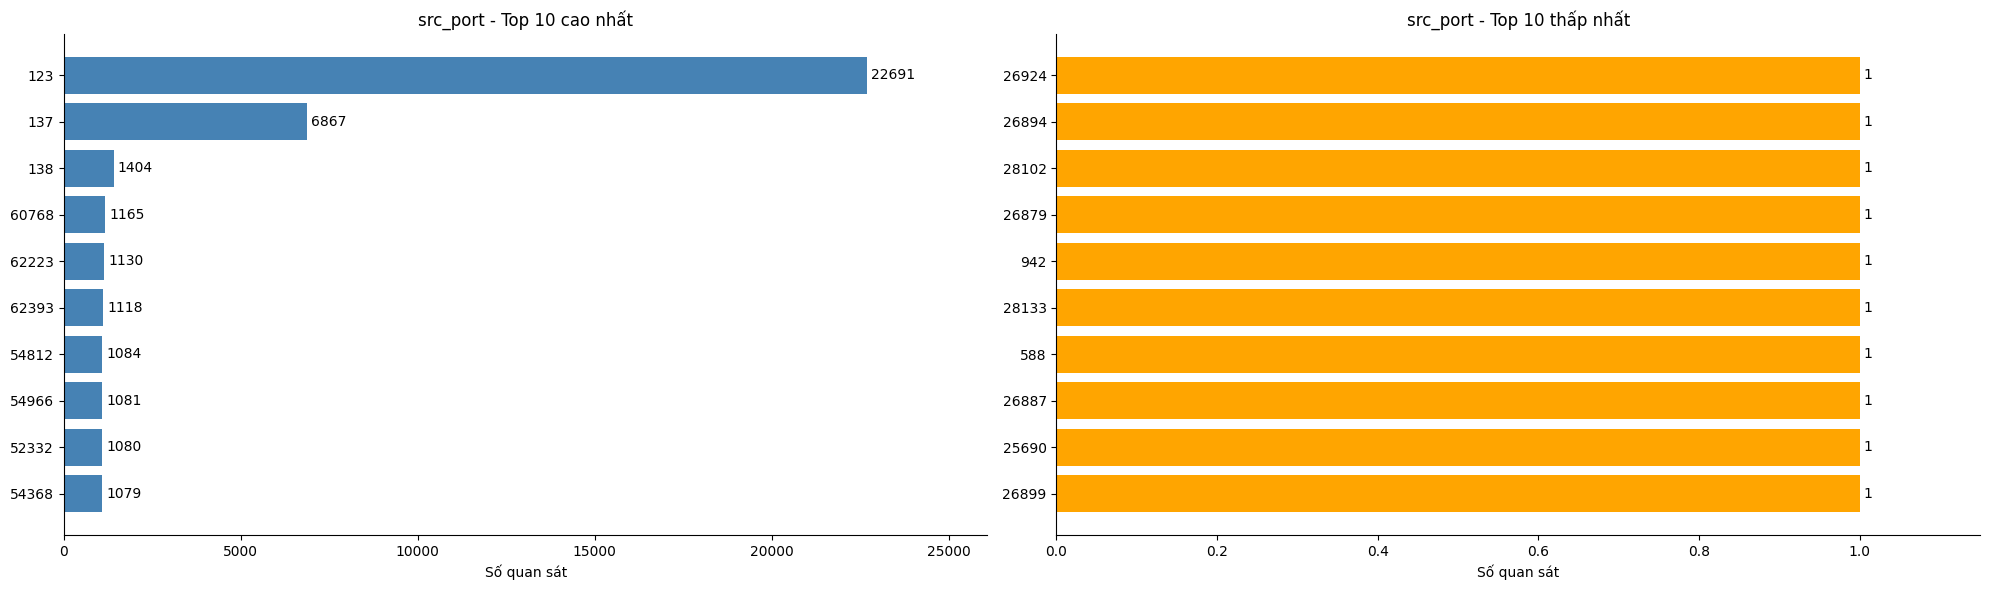

In [47]:
# Tần suất các biến phân loại có ý nghĩa; bỏ qua mã định danh duy nhất
for col in category_cols:
    counts = df_raw[col].value_counts(dropna=False)

    if counts.size > 20:
        fig, axes = plt.subplots(1, 2, figsize=(20, 6))
        top_high = counts.nlargest(10).sort_values()
        top_low = counts.nsmallest(10).sort_values(ascending=False)

        axes[0].barh(top_high.index.astype(str), top_high.values, color='steelblue')
        axes[0].bar_label(axes[0].containers[0], padding=3)
        axes[0].set_title(f'{col} - Top 10 cao nhất')

        axes[1].barh(top_low.index.astype(str), top_low.values, color='orange')
        axes[1].bar_label(axes[1].containers[0], padding=3)
        axes[1].set_title(f'{col} - Top 10 thấp nhất')
    else:
        fig, ax = plt.subplots(figsize=(12, 5))
        counts = counts.sort_values()
        ax.barh(counts.index.astype(str), counts.values, color='steelblue')
        ax.bar_label(ax.containers[0], padding=3)
        ax.set_title(f'Tần suất - {col}')
        axes = [ax]

    for ax in axes:
        ax.set_xlabel('Số quan sát')
        ax.spines[['top', 'right']].set_visible(False)
        ax.margins(x=0.15)
    plt.tight_layout()
    plt.show()

## Correlation

In [48]:
def analyze_category_vs_continous(category_var,continous_var, df):
    lst = []
    for name, g in df.groupby(category_var):
        lst.append(g[continous_var])
    f_statistic, p_value = f_oneway(*lst)
    return f_statistic, p_value

### Target & Numeric feature

In [49]:
target = ['label']

n = len(numeric_cols)
m = len(target)

for j in range(m):
    indepen = []
    dep = []
    for i in range(n):

        f_statistic, p_value = analyze_category_vs_continous(target[j],numeric_cols[i],df_raw)
        alpha = 0.05
        if p_value < alpha:
            dep.append(numeric_cols[i])
        else:
            indepen.append(numeric_cols[i])
    print()
    print(f'Các biến có tác động đến {target}: {dep}')
    print(f'Các biến không có tác động đến {target}: {indepen}')


Các biến có tác động đến ['label']: ['timestamp', 'flow_duration', 'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'flag_rst', 'flag_ack', 'flag_psh', 'fwd_flag_psh', 'bwd_flag_psh', 'flag_cwr', 'flag_

### Target & Categorical feature

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and attack_type=====
Reject H0 - Dependent


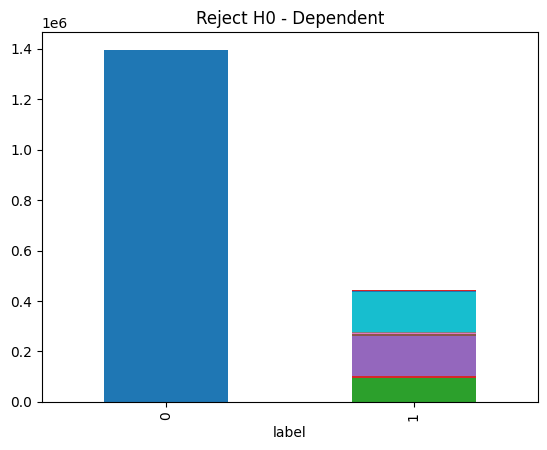

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and dst_addr=====
Reject H0 - Dependent


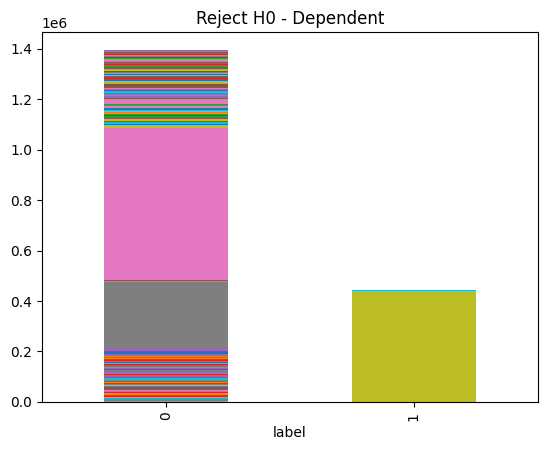

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and dst_port=====
Reject H0 - Dependent


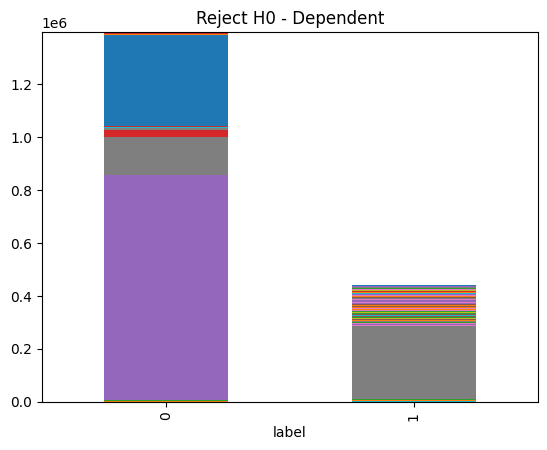

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and flow_id=====
Reject H0 - Dependent


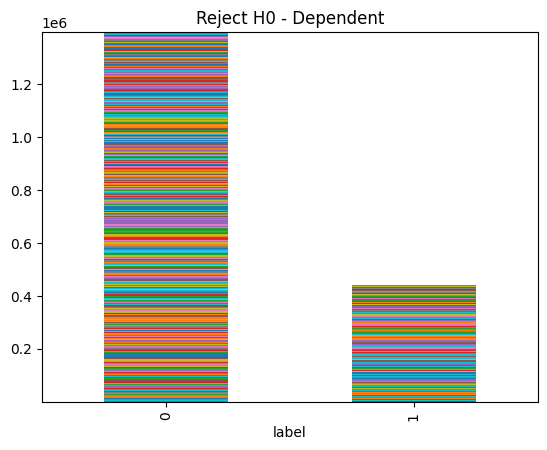

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and ip_prot=====
Reject H0 - Dependent


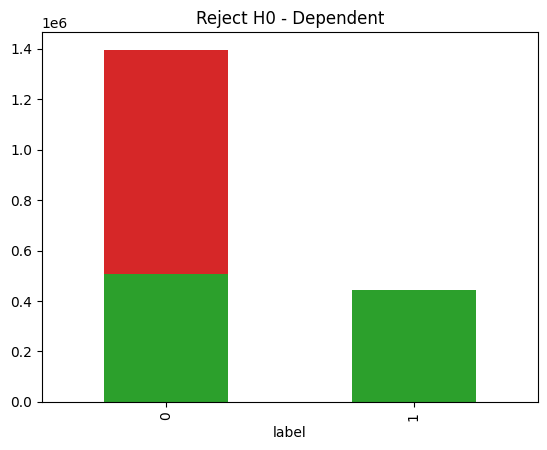

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and source_day=====
Reject H0 - Dependent


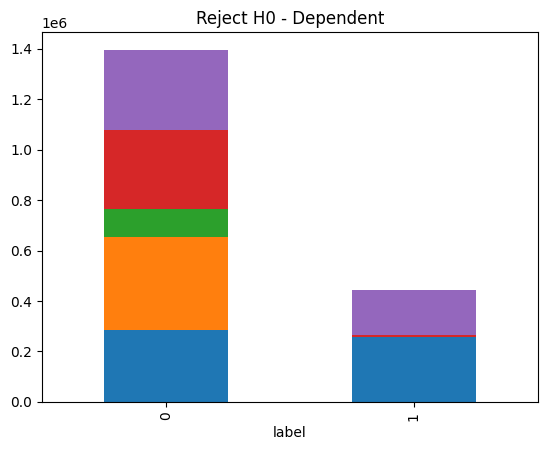

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and src_addr=====
Reject H0 - Dependent


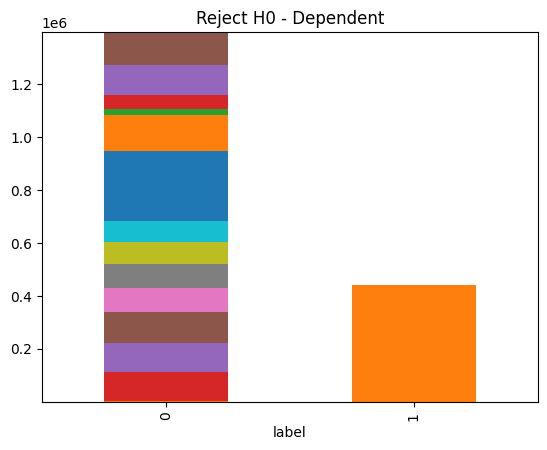

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of label and src_port=====
Reject H0 - Dependent


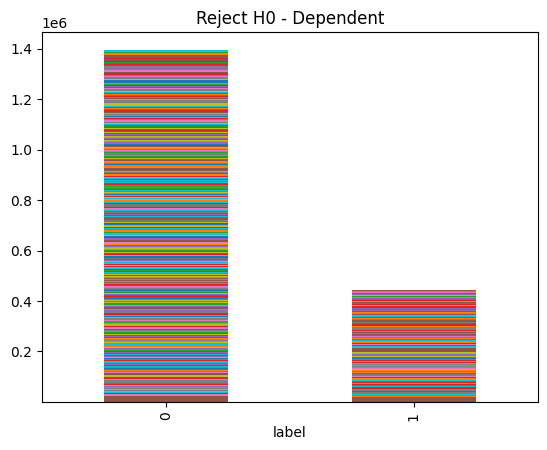

In [50]:
target_col = target[0]

for col in category_cols:
    if col == target_col:
        continue

    print('* ' * 40)
    _analyzer.analyze_category_vs_category(
        var1=target_col,
        var2=col,
        df=df_raw
    )

### Feature & Feature

#### Numeric - Numeric

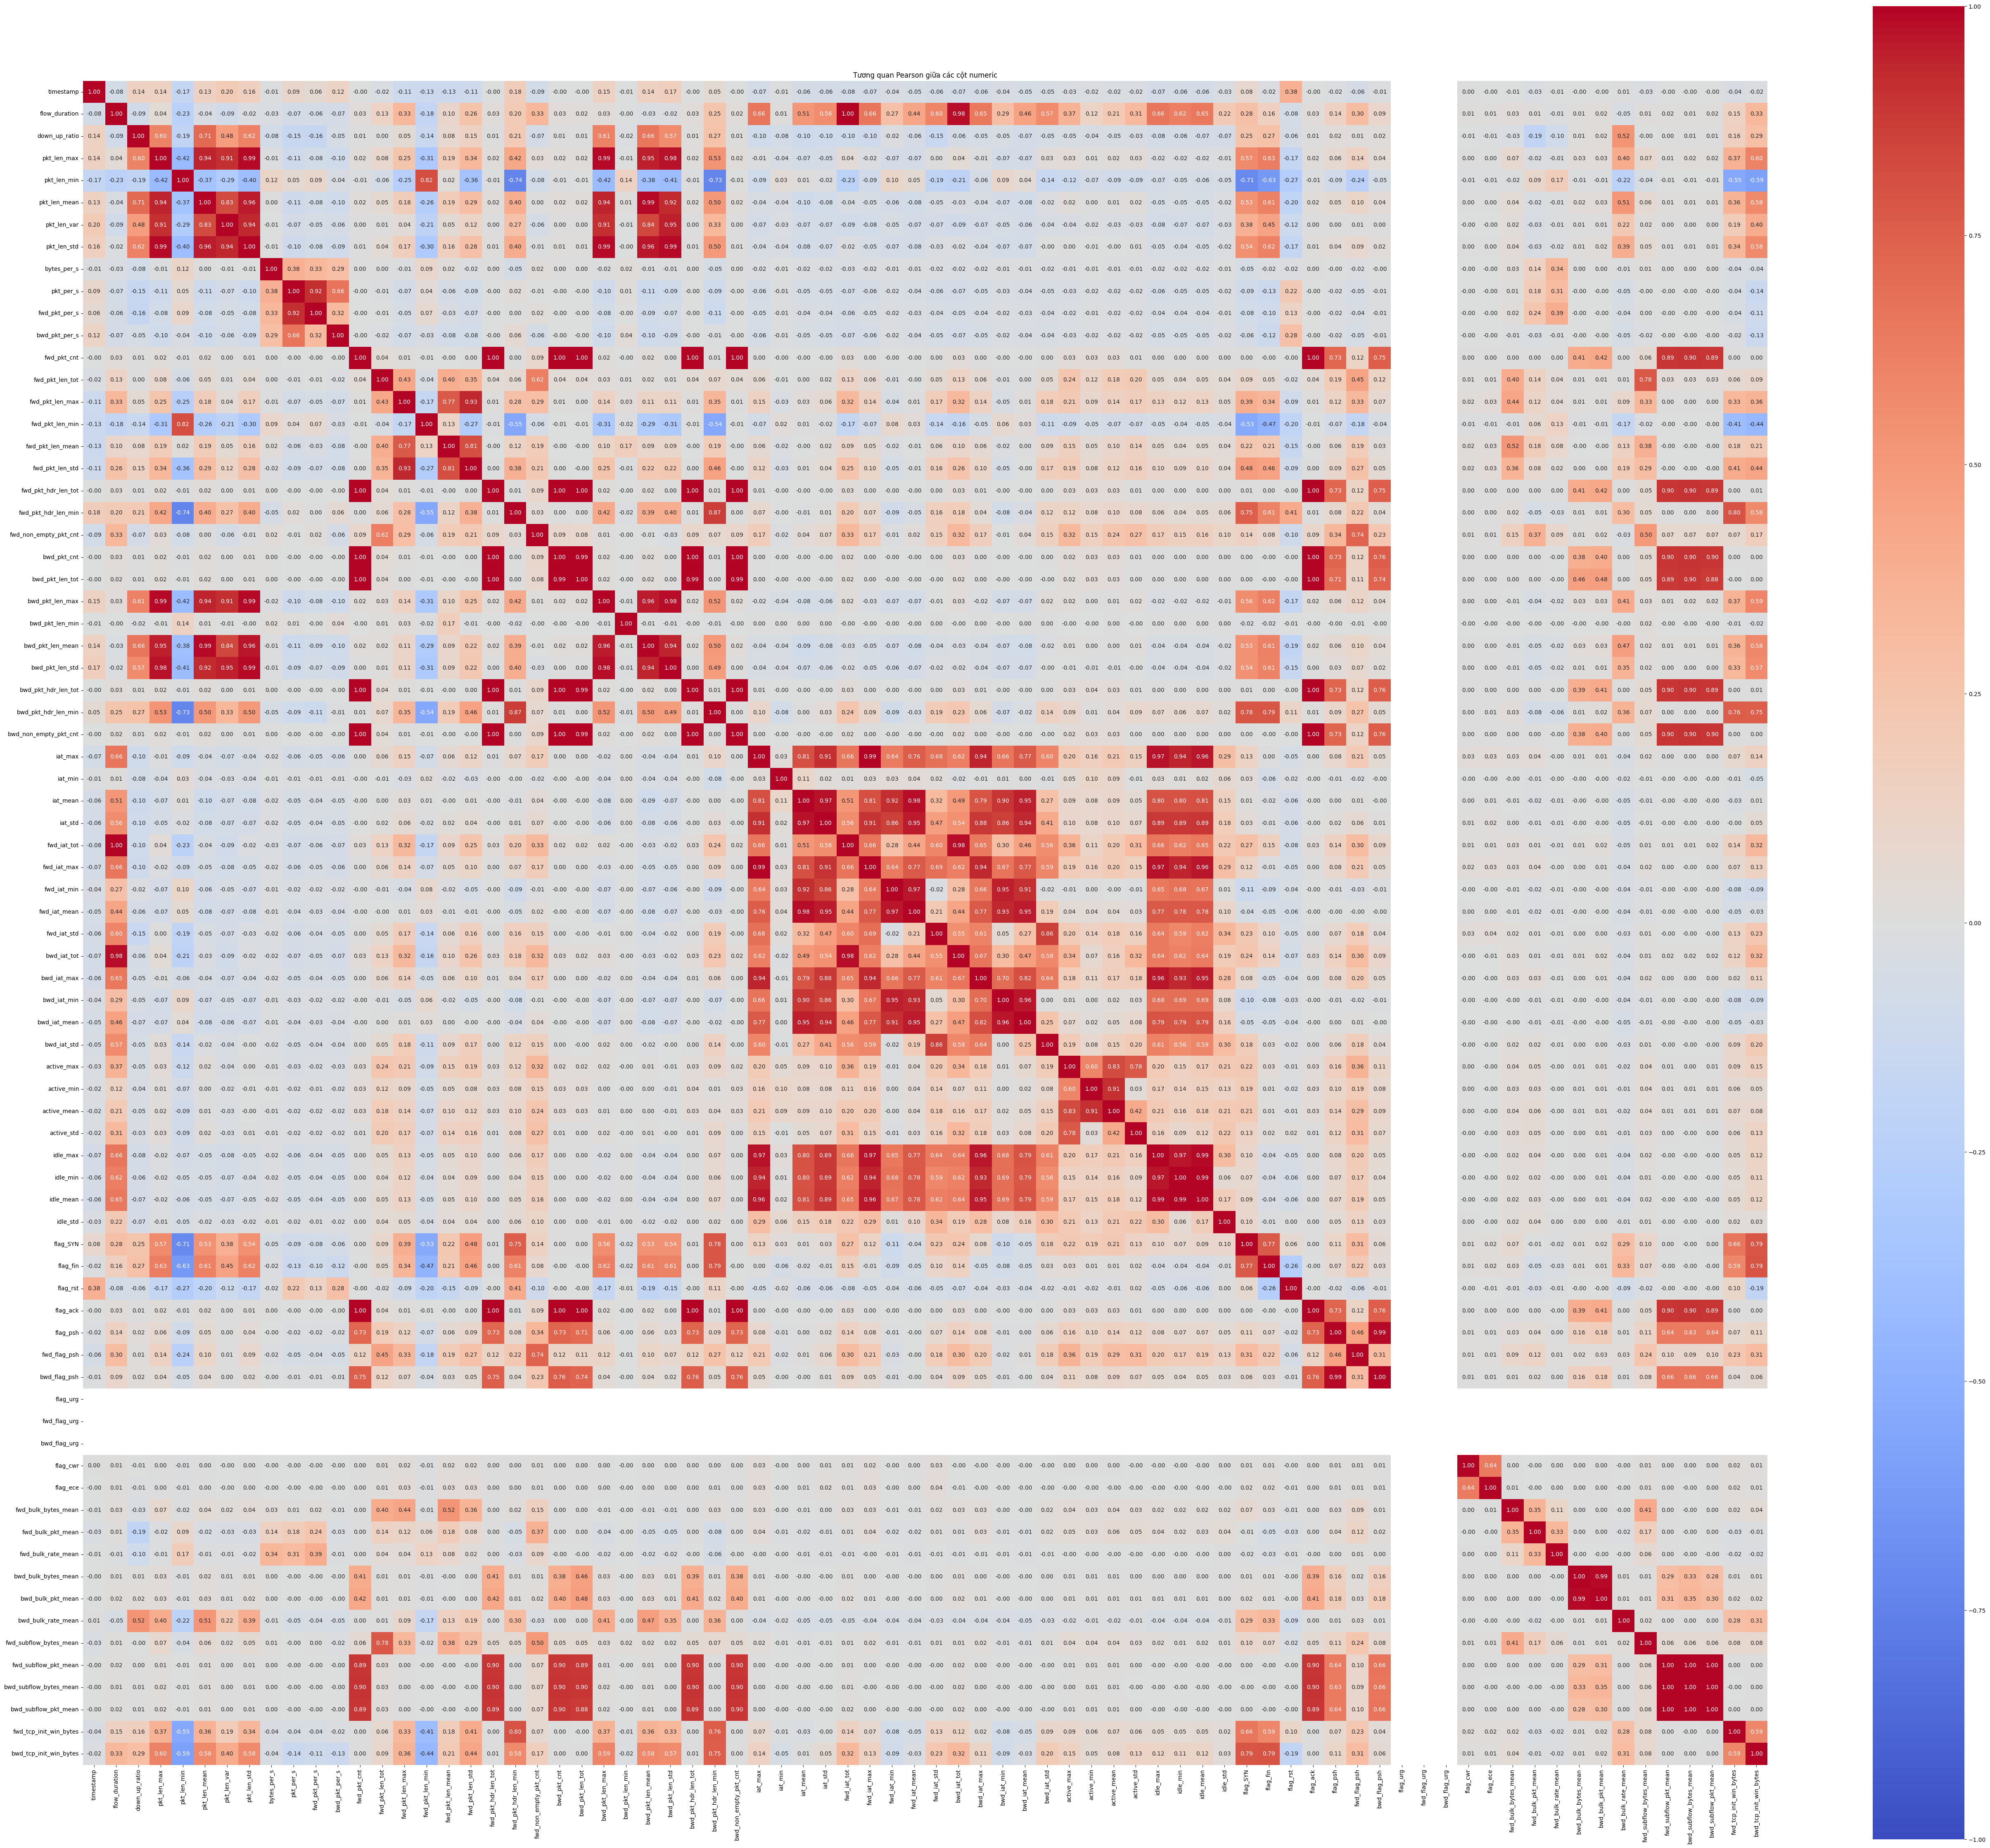

: 

In [ ]:
corr_num = df_raw[numeric_cols].corr(method="pearson")

if corr_num.empty:
    print("Không có cột numeric.")
else:
    plt.figure(figsize=(max(8, len(corr_num.columns) * 0.7),
                        max(6, len(corr_num.columns) * 0.6)))
    sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, square=True)
    plt.title("Tương quan Pearson giữa các cột numeric")
    plt.tight_layout()
    plt.show()

#### Category – Category

In [ ]:
def cramers_v(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(pair["x"], pair["y"])
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt((chi2 / n) / (min(table.shape) - 1))

if category_cols.empty:
    print("Không có cột category.")
else:
    cat_df = df_raw[category_cols]
    corr_cat = pd.DataFrame(
        index=category_cols, columns=category_cols, dtype=float
    )

    for a in category_cols:
        for b in category_cols:
            corr_cat.loc[a, b] = (
                1.0 if a == b else cramers_v(cat_df[a], cat_df[b])
            )

    plt.figure(figsize=(
        max(8, len(category_cols) * 0.7),
        max(6, len(category_cols) * 0.6)
    ))
    sns.heatmap(
        corr_cat, annot=True, fmt=".2f", cmap="Blues",
        vmin=0, vmax=1, square=True
    )
    plt.title("Liên hệ Cramér's V giữa các cột category")
    plt.tight_layout()
    plt.show()

#### Numeric – Category

In [ ]:
cols = list(numeric_cols) + list(category_cols)
numeric_set = set(numeric_cols)

def cramers_v(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(pair["x"], pair["y"])
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt((chi2 / n) / (min(table.shape) - 1))

def eta(category, numeric):
    pair = pd.DataFrame({"category": category, "numeric": numeric}).dropna()
    if pair.empty:
        return np.nan
    values = pair["numeric"].astype(float)
    total = ((values - values.mean()) ** 2).sum()
    if total == 0:
        return np.nan
    means = pair.groupby("category")["numeric"].transform("mean")
    between = ((means - values.mean()) ** 2).sum()
    return np.sqrt(between / total)

if not cols:
    print("Không có cột numeric hoặc category.")
else:
    assoc = pd.DataFrame(np.nan, index=cols, columns=cols)

    for i, a in enumerate(cols):
        assoc.loc[a, a] = 1.0
        for b in cols[i + 1:]:
            if a in numeric_set and b in numeric_set:
                value = abs(df_raw[a].corr(df_raw[b]))
            elif a not in numeric_set and b not in numeric_set:
                value = cramers_v(df_raw[a], df_raw[b])
            else:
                numeric, category = (a, b) if a in numeric_set else (b, a)
                value = eta(df_raw[category], df_raw[numeric])

            assoc.loc[a, b] = assoc.loc[b, a] = value

    plt.figure(figsize=(
        max(9, len(cols) * 0.65),
        max(7, len(cols) * 0.55)
    ))
    sns.heatmap(
        assoc, annot=len(cols) <= 20, fmt=".2f",
        cmap="YlOrRd", vmin=0, vmax=1, square=True
    )
    plt.title("Mức độ liên hệ giữa tất cả cột")
    plt.tight_layout()
    plt.show()

# Preprocess

## Sample Processing

In [25]:
clean_log = []
issue_log = []

### Loại trùng & thiếu
Không có trùng và thiếu

In [26]:
df_clean = df_raw.copy()

duplicate_mask = df_clean.duplicated()
n_duplicate = int(duplicate_mask.sum())
df_clean = df_clean.loc[~duplicate_mask].copy()
clean_log.append(["Trùng toàn bộ", n_duplicate, n_duplicate])

print("Trước xử lý:", len(df_raw))
print("Sau xử lý:", len(df_clean))
print("Đã loại bỏ:", n_duplicate)

Trước xử lý: 1837498
Sau xử lý: 1837498
Đã loại bỏ: 0


### Đổi kiểu dữ liệu

In [27]:
# Đã đổi ở "Xác định kiểu dữ liệu"

### Giá trị không hợp lệ

In [28]:
# Giá trị cổng không hợp lệ
n_invalid_value = 0
for col in ["src_port", "dst_port"]:
    bad = (
        df_clean[col].notna()
        & (
            ~df_clean[col].astype(int).between(0, 65535)
            | df_clean[col].astype(int).mod(1).ne(0)
        )
    )
    n_bad = int(bad.sum())
    df_clean.loc[bad, col] = None
    n_invalid_value += n_bad

    if n_bad > 0:
        issue_log.append([col, "Cổng ngoài 0–65535 hoặc không nguyên", n_bad])
print("Số giá trị cổng không hợp lệ:", n_invalid_value)

# Mã giao thức không hợp lệ
bad = (
    df_clean["ip_prot"].notna()
    & (
        ~df_clean["ip_prot"].astype(int).between(0, 255)
        | df_clean["ip_prot"].astype(int).mod(1).ne(0)
    )
)
n_bad = int(bad.sum())
df_clean.loc[bad, "ip_prot"] = None
n_invalid_value += n_bad
if n_bad > 0:
    issue_log.append(["ip_prot", "Mã giao thức không hợp lệ", n_bad])
print("Số giá trị ip_prot không hợp lệ:", n_invalid_value)

Số giá trị cổng không hợp lệ: 0
Số giá trị ip_prot không hợp lệ: 0


### Giá trị không được âm

In [29]:
nonnegative_cols = [
    col for col in numeric_cols
    if col not in ["bwd_tcp_init_win_bytes", "fwd_tcp_init_win_bytes"]
]

negative_counts = []

for col in nonnegative_cols:
    values = pd.to_numeric(df_clean[col].astype("object"), errors="coerce")
    bad = (values < 0).fillna(False)
    n_bad = int(bad.sum())

    negative_counts.append({"Cột": col, "Số giá trị âm": n_bad})

    if n_bad > 0:
        df_clean.loc[bad, col] = None
        n_invalid_value += n_bad
        issue_log.append([col, "Giá trị âm không hợp lệ", n_bad])

negative_report = (
    pd.DataFrame(negative_counts)
    .query("`Số giá trị âm` > 0")
    .sort_values("Số giá trị âm", ascending=False)
)

print("Số giá trị bất hợp lý:", n_invalid_value)
print(negative_report.to_string(index=False) if not negative_report.empty
      else "Không có cột nào chứa giá trị âm.")

clean_log.append(["Giá trị bất hợp lý → None", 0, n_invalid_value])

# Loại tại data chỉ chiếm 2270/1tr8 dòng
df_clean = df_clean[df_clean['iat_min'].notna()].copy()
df_clean

Số giá trị bất hợp lý: 2270
    Cột  Số giá trị âm
iat_min           2270


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,attack_type,source_day,label
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday,0
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday,0
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday,0
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday,0
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7

### Giá trị vô cực
=> không có

In [30]:
n_inf = 0
for col in numeric_cols:
    values = pd.to_numeric(df_clean[col], errors="coerce")
    bad = np.isinf(values.to_numpy(dtype=float, na_value=None))
    n_inf += int(bad.sum())
    if bad.any():
        df_clean.loc[bad, col] = None
        issue_log.append([col, "Có giá trị vô cực", n_bad])
print(f"Đã đổi {n_inf:,} giá trị vô cực thành None")

Đã đổi 0 giá trị vô cực thành None


### Results

In [31]:
clean_table = pd.DataFrame(
    clean_log,
    columns=["Bước", "Số dòng loại", "Số giá trị cần xử lý"]
)
clean_table

,Bước,Số dòng loại,Số giá trị cần xử lý
0,Trùng toàn bộ,0,0
1,Giá trị bất hợp lý → None,0,2270


In [32]:
issue_table = pd.DataFrame(
    issue_log,
    columns=["Cột", "Vấn đề", "Số giá trị cần xử lý"]
)
issue_table

,Cột,Vấn đề,Số giá trị cần xử lý
0,iat_min,Giá trị âm không hợp lệ,2270


## Feature Processing

### Loại bỏ features

In [33]:
# Không sử dụng các cột định danh như: id, địa chỉ ip, thời gian
# Đồng thời loại các cột label
exclude_cols = {"flow_id", "src_addr", "dst_addr", "timestamp", "attack_type", "label", "src_port", "dst_port"}
all_cols = list(dict.fromkeys([*numeric_cols, *category_cols]))
candidate_cols = [c for c in all_cols if c not in exclude_cols]

# Loại thuộc tính chỉ có 1 giá trị phân biệt hoặc ít hơn
drop_constant = [
    c for c in candidate_cols
    if df_clean[c].nunique(dropna=True) <= 1
]
candidate_cols = [c for c in candidate_cols if c not in drop_constant]
print("Các cột bị loại do thuộc tính chỉ có 1 giá trị:", drop_constant)
print("Các features:", candidate_cols)

Các cột bị loại do thuộc tính chỉ có 1 giá trị: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
Các features: ['flow_duration', 'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'flag_rst', 'flag_ack', 'flag

### Split train - test

In [34]:
RANDOM_STATE = 42

train_idx, test_idx = train_test_split(
    df_clean.index,
    test_size=0.20,
    stratify=df_clean["label"],
    shuffle=True,
    random_state=RANDOM_STATE,
)

print(f"Train: {len(train_idx):,} dòng | Test: {len(test_idx):,} dòng")
print("Tỷ lệ tấn công train/test:",
      df_clean.loc[train_idx, "label"].mean().round(4),"/",
      df_clean.loc[test_idx, "label"].mean().round(4))

# Tách train/test
X_train = df_clean.loc[train_idx, candidate_cols].copy()
X_test = df_clean.loc[test_idx, candidate_cols].copy()
y_train = df_clean.loc[train_idx, "label"].copy()
y_test = df_clean.loc[test_idx, "label"].copy()

Train: 1,468,182 dòng | Test: 367,046 dòng
Tỷ lệ tấn công train/test: 0.2406 / 0.2406


In [35]:
categorical_features = [c for c in category_cols if c in candidate_cols]
numeric_features = [c for c in numeric_cols if c in candidate_cols]

### Features selection

In [36]:
usable_cols = [
    c for c in candidate_cols
    if X_train[c].nunique(dropna=False) > 1
]
if not usable_cols:
    raise ValueError("Không còn thuộc tính nào biến thiên trong train.")

if len(train_idx) > 50_000:
    rank_idx, _ = train_test_split(
        train_idx,
        train_size=50_000,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )
else:
    rank_idx = train_idx

rank_numeric = [c for c in usable_cols if c in numeric_features]
rank_category = [c for c in usable_cols if c in categorical_features]

X_rank = pd.DataFrame(index=rank_idx)

for col in rank_numeric:
    X_rank[col] = X_train.loc[rank_idx, col].to_numpy(dtype=np.float32)

if rank_category:
    rank_encoder = OrdinalEncoder(dtype=np.float32)
    encoded = rank_encoder.fit_transform(
        X_train.loc[rank_idx, rank_category].astype(str)
    )
    for j, col in enumerate(rank_category):
        X_rank[col] = encoded[:, j]

discrete_mask = [c in rank_category for c in X_rank.columns]
mi_scores = mutual_info_classif(
    X_rank,
    y_train.loc[rank_idx],
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE,
)

ranking = (
    pd.DataFrame({"feature": X_rank.columns, "MI": mi_scores})
    .sort_values(["MI", "feature"], ascending=[False, True])
    .reset_index(drop=True)
)

# Tương quan giữa các thuộc tính số, chỉ dùng dữ liệu train đã lấy mẫu
corr_numeric = X_rank[rank_numeric].corr(method="spearman").abs()
CORR_THRESHOLD = 0.95
K = min(30, len(ranking))

# Liệt kê các cặp tương quan mạnh để kiểm tra
upper = corr_numeric.where(
    np.triu(np.ones(corr_numeric.shape), k=1).astype(bool)
)
strong_pairs = (
    upper.stack()
    .reset_index()
    .set_axis(["Cột 1", "Cột 2", "|Spearman|"], axis=1)
    .query("`|Spearman|` >= @CORR_THRESHOLD")
    .sort_values("|Spearman|", ascending=False)
)

print("Các cặp thuộc tính số tương quan mạnh:")
display(strong_pairs)

# Duyệt theo MI từ cao xuống thấp; bỏ cột gần trùng với cột đã giữ
selected_features = []
redundant_log = []

for feature in ranking["feature"]:
    matching = None

    if feature in rank_numeric:
        for kept in selected_features:
            if (
                kept in rank_numeric
                and corr_numeric.loc[feature, kept] >= CORR_THRESHOLD
            ):
                matching = kept
                break

    if matching is not None:
        redundant_log.append([
            feature, matching, corr_numeric.loc[feature, matching]
        ])
        continue

    selected_features.append(feature)
    if len(selected_features) == K:
        break

redundant_report = pd.DataFrame(
    redundant_log,
    columns=["Cột bỏ", "Cột giữ", "|Spearman|"],
)

print(f"Đã chọn {len(selected_features)} thuộc tính:")
display(ranking[ranking["feature"].isin(selected_features)])
print("Các cột bỏ do tương quan mạnh:")
display(redundant_report)

Các cặp thuộc tính số tương quan mạnh:


,Cột 1,Cột 2,|Spearman|
345,pkt_len_var,pkt_len_std,1.000000
2465,flag_cwr,flag_ece,1.000000
2490,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,0.999837
2501,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,0.999734
2491,fwd_bulk_bytes_mean,fwd_bulk_rate_mean,0.999726
...,...,...,...
1176,fwd_pkt_hdr_len_min,fwd_tcp_init_win_bytes,0.955242
1654,iat_max,iat_mean,0.955042
685,bwd_pkt_per_s,iat_mean,0.953301
603,fwd_pkt_per_s,bwd_pkt_per_s,0.951290


Đã chọn 30 thuộc tính:


,feature,MI
0,bwd_pkt_len_mean,0.467624
2,bwd_pkt_len_tot,0.462402
4,pkt_len_max,0.450228
8,fwd_pkt_hdr_len_tot,0.420308
9,flag_ack,0.408288
10,fwd_pkt_len_max,0.407098
11,fwd_pkt_len_mean,0.402173
12,fwd_subflow_bytes_mean,0.394906
13,fwd_pkt_len_tot,0.385225
14,bwd_pkt_hdr_len_tot,0.377790


Các cột bỏ do tương quan mạnh:


,Cột bỏ,Cột giữ,|Spearman|
0,bwd_subflow_bytes_mean,bwd_pkt_len_mean,0.950624
1,pkt_len_mean,bwd_pkt_len_mean,0.965986
2,pkt_len_std,pkt_len_max,0.989298
3,pkt_len_var,pkt_len_max,0.989298
4,bwd_pkt_len_max,bwd_pkt_len_mean,0.958496
5,fwd_iat_tot,fwd_iat_max,0.996995
6,flow_duration,iat_max,0.987278
7,fwd_iat_mean,fwd_iat_max,0.995961
8,fwd_pkt_hdr_len_min,fwd_tcp_init_win_bytes,0.955242
9,fwd_pkt_per_s,iat_max,0.970390


In [37]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

selected_category = [
    c for c in selected_features if c in categorical_features
]

# Mã hóa các cột phân loại để mô hình nhận dữ liệu số.
# Giá trị chỉ xuất hiện ở test sẽ nhận mã -1.
X_train_model = X_train_selected.copy()
X_test_model = X_test_selected.copy()

### Encoding

In [ ]:
model_encoder = None

if selected_category:
    model_encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        dtype=np.float32,
    )
    X_train_model[selected_category] = model_encoder.fit_transform(
        X_train_selected[selected_category].astype(str)
    )
    X_test_model[selected_category] = model_encoder.transform(
        X_test_selected[selected_category].astype(str)
    )

print("Dữ liệu phân lớp:", X_train_model.shape, X_test_model.shape)
print("Cột đã chọn:", selected_features)

### Scaling

In [39]:
# scale_cols = [c for c in selected_features if c in numeric_features]
# X_train_scaled = X_train_model.copy()
# X_test_scaled = X_test_model.copy()

# if scale_cols:
#     scaler = StandardScaler()
#     X_train_scaled[scale_cols] = scaler.fit_transform(
#         X_train_model[scale_cols]
#     )
#     X_test_scaled[scale_cols] = scaler.transform(
#         X_test_model[scale_cols]
#     )

# print("Đã scale các cột số:", scale_cols)

### Rời rạc hóa

In [ ]:
arm_train = pd.DataFrame(index=X_train_selected.index)
arm_test = pd.DataFrame(index=X_test_selected.index)
bin_edges = {}

y_for_bins = y_train.reindex(X_train_selected.index)

for col in selected_features:
    # Cột phân loại: giữ nguyên giá trị dưới dạng item
    if col in categorical_features:
        arm_train[col] = pd.Categorical(
            col + "=" + X_train_selected[col].astype(str)
        )
        arm_test[col] = pd.Categorical(
            col + "=" + X_test_selected[col].astype(str)
        )
        continue

    # Cột số: học ngưỡng chia bằng cây trên tập train
    train_values = (
        pd.to_numeric(X_train_selected[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    test_values = (
        pd.to_numeric(X_test_selected[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    valid = train_values.notna() & y_for_bins.notna()
    cuts = np.array([])

    if (
        train_values.loc[valid].nunique() > 1
        and y_for_bins.loc[valid].nunique() > 1
    ):
        tree = DecisionTreeClassifier(
            criterion="entropy",
            max_leaf_nodes=4,
            min_samples_leaf=0.02,
            random_state=42,
        )

        tree.fit(
            train_values.loc[valid].to_frame(),
            y_for_bins.loc[valid],
        )

        cuts = np.sort(
            tree.tree_.threshold[tree.tree_.feature >= 0]
        )

    edges = np.r_[-np.inf, cuts, np.inf]
    bin_edges[col] = edges

    labels = [
        f"{col}=B{i + 1}"
        for i in range(len(edges) - 1)
    ]

    missing_item = f"{col}=missing"

    arm_train[col] = (
        pd.cut(train_values, bins=edges, labels=labels)
        .cat.add_categories(missing_item)
        .fillna(missing_item)
    )
    arm_test[col] = (
        pd.cut(test_values, bins=edges, labels=labels)
        .cat.add_categories(missing_item)
        .fillna(missing_item)
    )

print("Bảng item train/test:", arm_train.shape, arm_test.shape)
arm_train

Bảng item train/test: (1468182, 30) (367046, 30)
Ngưỡng bytes_per_s: [          -inf 7.80649995e-03 6.13328125e+03 7.27258938e+05
            inf]


,bwd_pkt_len_mean,bwd_pkt_len_tot,pkt_len_max,fwd_pkt_hdr_len_tot,flag_ack,fwd_pkt_len_max,fwd_pkt_len_mean,fwd_subflow_bytes_mean,fwd_pkt_len_tot,bwd_pkt_hdr_len_tot,bwd_tcp_init_win_bytes,iat_max,fwd_iat_max,fwd_tcp_init_win_bytes,bwd_pkt_len_std,bytes_per_s,flag_SYN,bwd_pkt_per_s,bwd_iat_max,fwd_pkt_len_std,fwd_subflow_pkt_mean,down_up_ratio,fwd_pkt_cnt,bwd_pkt_cnt,fwd_iat_std,fwd_non_empty_pkt_cnt,bwd_subflow_pkt_mean,bwd_non_empty_pkt_cnt,fwd_pkt_len_min,bwd_pkt_hdr_len_min
1396392,bwd_pkt_len_mean=B2,bwd_pkt_len_tot=B2,pkt_len_max=B2,fwd_pkt_hdr_len_tot=B1,flag_ack=B1,fwd_pkt_len_max=B2,fwd_pkt_len_mean=B2,fwd_subflow_bytes_mean=B2,fwd_pkt_len_tot=B2,bwd_pkt_hdr_len_tot=B1,bwd_tcp_init_win_bytes=B1,iat_max=B2,fwd_iat_max=B1,fwd_tcp_init_win_bytes=B1,bwd_pkt_len_std=B1,bytes_per_s=B2,flag_SYN=B1,bwd_pkt_per_s=B2,bwd_iat_max=B2,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B2,down_up_ratio=B2,fwd_pkt_cnt=B2,bwd_pkt_cnt=B2,fwd_iat_std=B1,fwd_non_empty_pkt_cnt=B3,bwd_subflow_pkt_mean=B2,bwd_non_empty_pkt_cnt=B2,fwd_pkt_len_min=B2,bwd_pkt_hdr_len_min=B1
248855,bwd_pkt_len_mean=B1,bwd_pkt_len_tot=B1,pkt_len_max=B1,fwd_pkt_hdr_len_tot=B2,flag_ack=B2,fwd_pkt_len_max=B1,fwd_pkt_len_mean=B1,fwd_subflow_bytes_mean=B1,fwd_pkt_len_tot=B1,bwd_pkt_hdr_len_tot=B2,bwd_tcp_init_win_bytes=B2,iat_max=B1,fwd_iat_max=B1,fwd_tcp_init_win_bytes=B2,bwd_pkt_len_std=B1,bytes_per_s=B1,flag_SYN=B2,bwd_pkt_per_s=B4,bwd_iat_max=B1,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B1,down_up_ratio=B2,fwd_pkt_cnt=B1,bwd_pkt_cnt=B1,fwd_iat_std=B1,fwd_non_empty_pkt_cnt=B1,bwd_subflow_pkt_mean=B1,bwd_non_empty_pkt_cnt=B1,fwd_pkt_len_min=B1,bwd_pkt_hdr_len_min=B2
866105,bwd_pkt_len_mean=B2,bwd_pkt_len_tot=B2,pkt_len_max=B2,fwd_pkt_hdr_len_tot=B3,flag_ack=B1,fwd_pkt_len_max=B2,fwd_pkt_len_mean=B2,fwd_subflow_bytes_mean=B2,fwd_pkt_len_tot=B2,bwd_pkt_hdr_len_tot=B3,bwd_tcp_init_win_bytes=B1,iat_max=B2,fwd_iat_max=B3,fwd_tcp_init_win_bytes=B1,bwd_pkt_len_std=B1,bytes_per_s=B3,flag_SYN=B1,bwd_pkt_per_s=B2,bwd_iat_max=B3,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B4,down_up_ratio=B2,fwd_pkt_cnt=B3,bwd_pkt_cnt=B3,fwd_iat_std=B3,fwd_non_empty_pkt_cnt=B3,bwd_subflow_pkt_mean=B3,bwd_non_empty_pkt_cnt=B3,fwd_pkt_len_min=B2,bwd_pkt_hdr_len_min=B1
253743,bwd_pkt_len_mean=B1,bwd_pkt_len_tot=B1,pkt_len_max=B1,fwd_pkt_hdr_len_tot=B2,flag_ack=B2,fwd_pkt_len_max=B1,fwd_pkt_len_mean=B1,fwd_subflow_bytes_mean=B1,fwd_pkt_len_tot=B1,bwd_pkt_hdr_len_tot=B2,bwd_tcp_init_win_bytes=B2,iat_max=B1,fwd_iat_max=B1,fwd_tcp_init_win_bytes=B2,bwd_pkt_len_std=B1,bytes_per_s=B1,flag_SYN=B2,bwd_pkt_per_s=B4,bwd_iat_max=B1,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B1,down_up_ratio=B2,fwd_pkt_cnt=B1,bwd_pkt_cnt=B1,fwd_iat_std=B1,fwd_non_empty_pkt_cnt=B1,bwd_subflow_pkt_mean=B1,bwd_non_empty_pkt_cnt=B1,fwd_pkt_len_min=B1,bwd_pkt_hdr_len_min=B2
1784461,bwd_pkt_len_mean=B2,bwd_pkt_len_tot=B2,pkt_len_max=B2,fwd_pkt_hdr_len_tot=B1,flag_ack=B1,fwd_pkt_len_max=B2,fwd_pkt_len_mean=B2,fwd_subflow_bytes_mean=B2,fwd_pkt_len_tot=B2,bwd_pkt_hdr_len_tot=B1,bwd_tcp_init_win_bytes=B1,iat_max=B2,fwd_iat_max=B1,fwd_tcp_init_win_bytes=B1,bwd_pkt_len_std=B1,bytes_per_s=B4,flag_SYN=B1,bwd_pkt_per_s=B3,bwd_iat_max=B2,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B2,down_up_ratio=B2,fwd_pkt_cnt=B2,bwd_pkt_cnt=B2,fwd_iat_std=B1,fwd_non_empty_pkt_cnt=B3,bwd_subflow_pkt_mean=B2,bwd_non_empty_pkt_cnt=B2,fwd_pkt_len_min=B2,bwd_pkt_hdr_len_min=B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
266729,bwd_pkt_len_mean=B1,bwd_pkt_len_tot=B1,pkt_len_max=B1,fwd_pkt_hdr_len_tot=B2,flag_ack=B2,fwd_pkt_len_max=B1,fwd_pkt_len_mean=B1,fwd_subflow_bytes_mean=B1,fwd_pkt_len_tot=B1,bwd_pkt_hdr_len_tot=B2,bwd_tcp_init_win_bytes=B2,iat_max=B1,fwd_iat_max=B1,fwd_tcp_init_win_bytes=B2,bwd_pkt_len_std=B1,bytes_per_s=B1,flag_SYN=B2,bwd_pkt_per_s=B4,bwd_iat_max=B1,fwd_pkt_len_std=B1,fwd_subflow_pkt_mean=B1,down_up_ratio=B2,fwd_pkt_cnt=B1,bwd_pkt_cnt=B1,fwd_iat_std=B1,fwd_non_empty_pkt_cnt=B1,b

### Results

In [83]:
p0 = df_raw.drop(columns=["label", "attack_type"], errors="ignore").shape[1]
p1 = len(selected_features)

summary_before_after = pd.DataFrame({
    "Chỉ tiêu": [
        "Số dòng dữ liệu",
        "Số thuộc tính",
        "Số giá trị thiếu",
        "Số dòng trùng lặp",
        "Số thuộc tính bị loại",
    ],
    "Trước xử lý": [
        len(df_raw),
        p0,
        int(df_raw.drop(columns=["label", "attack_type"], errors="ignore")
            .isna().sum().sum()),
        int(df_raw.duplicated().sum()),
        "—",
    ],
    "Sau xử lý": [
        len(df_clean),
        p1,
        int(X_train[selected_features].isna().sum().sum()
            + X_test[selected_features].isna().sum().sum()),
        int(df_clean.duplicated().sum()),
        p0 - p1,
    ],
})

summary_before_after

,Chỉ tiêu,Trước xử lý,Sau xử lý
0,Số dòng dữ liệu,1837498,1835228
1,Số thuộc tính,83,30
2,Số giá trị thiếu,0,0
3,Số dòng trùng lặp,0,0
4,Số thuộc tính bị loại,—,53


In [84]:
pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index(),
}).rename(index={0: "Benign", 1: "Attack"})

,Train,Test
label,,
Benign,0.759369,0.759368
Attack,0.240631,0.240632


# Export data

In [89]:
X_train_model.to_pickle("04_output/02_clean_data/X_train_model.pkl")
X_test_model.to_pickle("04_output/02_clean_data/X_test_model.pkl")
y_train.to_pickle("04_output/02_clean_data/y_train.pkl")
y_test.to_pickle("04_output/02_clean_data/y_test.pkl")
arm_train.to_pickle("04_output/02_clean_data/arm_train.pkl")
arm_test.to_pickle("04_output/02_clean_data/arm_test.pkl")

print("Đã lưu train/test và bảng item vào:", "02_clean_data")

Đã lưu train/test và bảng item vào: 02_clean_data
